# BCMID : Data & Quality Agent (version code simple, sans agent)

Notebook nettoyé : une seule version finale de chaque fonction, exécution de haut en bas.

| Section | Contenu |
|---|---|
| 0 à 4 | Setup, métadonnées, profiling, intégrité, modalités manquantes, `group_id` |
| 5A | Diagnostic des images (polarité, bordures, alpha) |
| 5B | Constantes et fonctions de prétraitement |
| 5C | Analyse des sources d'acquisition et des raccourcis |
| 5D | Traitement des images (mammographies puis échographies) |
| 5E | Sondes de signature (que reste-t-il de la source ?) |
| 6 | Anonymisation (rapports, pseudo-IDs, masquage du texte) |
| 7 | Validation et découpage en 5 plis par groupe |
| 8 | Rapport qualité JSON |

**Cellule lente :** 5A (≈3-5 min), 5D (≈5 min), 6/OCR (≈6 min avec GPU). Active le GPU (Settings → Accelerator) avant la section 6.

# Étape 0 : Setup & exploration de l'arborescence

In [1]:
# ============================================================
# Étape 0 : Setup & Auto-détection de l'environnement (Kaggle / Local)
# ============================================================
import os
import random
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# Reproductibilité
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# 1) Détection automatique de l'environnement (Kaggle ou Local Windows/Linux)
INPUT_ROOT = Path("/kaggle/input")
if INPUT_ROOT.exists():
    print("Environnement Kaggle détecté.")
    WORK_DIR = Path("/kaggle/working")
    
    # Recherche robuste du dataset (bcmid, bcmdid, bcmid-data, etc.)
    tsv_list = list(INPUT_ROOT.rglob("BCMID_annotations.tsv"))
    if tsv_list:
        DATA_ROOT = tsv_list[0].parent
    else:
        bcmid_dirs = [p for p in INPUT_ROOT.rglob("BCMID") if p.is_dir()]
        if bcmid_dirs:
            DATA_ROOT = bcmid_dirs[0].parent
        else:
            bcm_candidates = [p for p in INPUT_ROOT.iterdir() if p.is_dir() and "bcm" in p.name.lower()]
            if bcm_candidates:
                DATA_ROOT = bcm_candidates[0]
            else:
                all_dirs = [p for p in INPUT_ROOT.iterdir() if p.is_dir()]
                DATA_ROOT = all_dirs[0] if all_dirs else INPUT_ROOT
else:
    print("Environnement Local Windows/Linux détecté.")
    LOCAL_ROOT = Path.cwd()
    if not (LOCAL_ROOT / "BCMID").exists():
        LOCAL_ROOT = Path(r"c:\Users\moham\OneDrive - ESPRIT\Documents\deeplearning5eme")
    DATA_ROOT = LOCAL_ROOT
    WORK_DIR = LOCAL_ROOT / "bcmid_work" / "dq_outputs"
    WORK_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_ROOT =", DATA_ROOT)
print("WORK_DIR  =", WORK_DIR)


Datasets détectés dans /kaggle/input :
  - datasets

DATA_ROOT = /kaggle/input/datasets
WORK_DIR  = /kaggle/working


## Arborescence

In [2]:
def show_tree(root, max_depth=3, max_items=8):
    """Affiche l'arborescence jusqu'à une profondeur donnée."""
    if root is None:
        print("⚠️ DATA_ROOT est None. Vérifiez que le dataset est bien attaché dans /kaggle/input.")
        return
    root = Path(root)
    if not root.exists():
        print(f"⚠️ Le dossier n'existe pas : {root}")
        return
    def _walk(path, depth):
        if depth > max_depth:
            return
        items = sorted(path.iterdir(), key=lambda x: (x.is_file(), x.name))
        dirs = [i for i in items if i.is_dir()]
        files = [i for i in items if i.is_file()]
        indent = "    " * depth
        for d in dirs[:max_items]:
            n = sum(1 for _ in d.rglob("*") if _.is_file())
            print(f"{indent}📁 {d.name}/  ({n} fichiers)")
            _walk(d, depth + 1)
        if len(dirs) > max_items:
            print(f"{indent}... +{len(dirs) - max_items} autres dossiers")
        for f in files[:max_items]:
            print(f"{indent}📄 {f.name}  ({f.stat().st_size/1024:.1f} KB)")
        if len(files) > max_items:
            print(f"{indent}... +{len(files) - max_items} autres fichiers")
    print(f"📂 {root}")
    _walk(root, 1)

show_tree(DATA_ROOT, max_depth=3)


📂 /kaggle/input/datasets
    📁 ikbelhamdi/  (2323 fichiers)
        📁 bcmid-data/  (2323 fichiers)
            📁 BCMID/  (2322 fichiers)
            📄 BCMID_annotations.tsv  (8.7 KB)


## Statistiques par extension

In [3]:
all_files = [f for f in DATA_ROOT.rglob("*") if f.is_file()]
ext_counts = Counter(f.suffix.lower() for f in all_files)

print(f"Nombre total de fichiers : {len(all_files)}")
print("\nRépartition par extension :")
for ext, n in ext_counts.most_common():
    print(f"  {ext or '(sans extension)':<18} {n}")

total_gb = sum(f.stat().st_size for f in all_files) / 1024**3
print(f"\nTaille totale : {total_gb:.2f} GB")

Nombre total de fichiers : 2323

Répartition par extension :
  .png               2001
  .pdf               321
  .tsv               1

Taille totale : 12.11 GB


# Étape 1 : Chargement des métadonnées

### chemins + structure du dossier BCMID

In [4]:
# ============================================================
# Chemins précis vers les données (Auto-détection Kaggle / Local)
# ============================================================
if Path("/kaggle/input/datasets/ikbelhamdi/bcmid-data").exists():
    DATA_ROOT = Path("/kaggle/input/datasets/ikbelhamdi/bcmid-data")
    IMG_ROOT  = DATA_ROOT / "BCMID"
    ANN_PATH  = DATA_ROOT / "BCMID_annotations.tsv"
    WORK_DIR  = Path("/kaggle/working")
elif Path("/kaggle/input").exists() and list(Path("/kaggle/input").rglob("BCMID_annotations.tsv")):
    ANN_PATH  = next(Path("/kaggle/input").rglob("BCMID_annotations.tsv"))
    DATA_ROOT = ANN_PATH.parent
    IMG_ROOT  = DATA_ROOT / "BCMID" if (DATA_ROOT / "BCMID").exists() else next(Path("/kaggle/input").rglob("BCMID"))
    WORK_DIR  = Path("/kaggle/working")
else:
    LOCAL_CWD = Path.cwd()
    if not (LOCAL_CWD / "BCMID").exists():
        LOCAL_CWD = Path(r"c:\Users\moham\OneDrive - ESPRIT\Documents\deeplearning5eme")
    DATA_ROOT = LOCAL_CWD
    IMG_ROOT  = DATA_ROOT / "BCMID"
    ANN_PATH  = DATA_ROOT / "BCMID_annotations.tsv"
    WORK_DIR  = DATA_ROOT / "bcmid_work" / "dq_outputs"
    WORK_DIR.mkdir(parents=True, exist_ok=True)

print("Annotations existe  :", ANN_PATH.exists(), f"({ANN_PATH})")
print("Dossier BCMID existe :", IMG_ROOT.exists(), f"({IMG_ROOT})")

# Structure détaillée du dossier BCMID
show_tree(IMG_ROOT, max_depth=3, max_items=6)


Annotations existe : True
Dossier BCMID existe : True
📂 /kaggle/input/datasets/ikbelhamdi/bcmid-data/BCMID
    📁 00074y23/  (13 fichiers)
        📁 Mammogram/  (2 fichiers)
            📄 00074y23_R_CC_1.png  (3202.8 KB)
            📄 00074y23_R_MLO_1.png  (3713.4 KB)
        📁 Ultrasound/  (11 fichiers)
            📄 00074y23_US_R_1.png  (363.4 KB)
            📄 00074y23_US_R_10.png  (338.5 KB)
            📄 00074y23_US_R_11.png  (341.4 KB)
            📄 00074y23_US_R_2.png  (361.8 KB)
            📄 00074y23_US_R_3.png  (345.6 KB)
            📄 00074y23_US_R_4.png  (340.7 KB)
            ... +5 autres fichiers
    📁 00163y21/  (5 fichiers)
        📁 Mammogram/  (2 fichiers)
            📄 00163y21_L_CC_1.png  (1491.1 KB)
            📄 00163y21_L_MLO_1.png  (1784.9 KB)
        📁 Ultrasound/  (3 fichiers)
            📄 00163y21_US_L_1.png  (368.0 KB)
            📄 00163y21_US_L_2.png  (370.2 KB)
            📄 00163y21_US_L_3.png  (336.6 KB)
    📁 0016y11/  (7 fichiers)
        📁 Mammogram

## lecture du TSV

In [5]:
ann = pd.read_csv(ANN_PATH, sep="\t")

print("Shape :", ann.shape)
print("\nColonnes :")
for i, c in enumerate(ann.columns):
    print(f"  {i:>2}. {c}")

print("\nTypes et valeurs non nulles :")
ann.info()

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
ann.head(10)

Shape : (332, 4)

Colonnes :
   0. Patient ID
   1. BI-RADS Label
   2. Binary Label
   3. Pathology Label

Types et valeurs non nulles :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 332 entries, 0 to 331
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Patient ID       332 non-null    object
 1   BI-RADS Label    332 non-null    int64 
 2   Binary Label     327 non-null    object
 3   Pathology Label  327 non-null    object
dtypes: int64(1), object(3)
memory usage: 10.5+ KB


,Patient ID,BI-RADS Label,Binary Label,Pathology Label
0,2071y19,2,Negative,Benign
1,3597y17,2,Negative,Benign
2,0470y18,3,Negative,Benign
3,0919y18,1,Negative,Normal
4,0877y07,4,Positive,Malignant
5,04138y20,2,Negative,Benign
6,1780y07,2,Negative,Benign
7,1238y19,2,Negative,Benign
8,2889y13,3,Negative,Benign
9,3679y19,1,Negative,Normal


## exemples de noms de fichiers, pour faire le lien avec le TSV

In [6]:
png_files = sorted(IMG_ROOT.rglob("*.png"))
pdf_files = sorted(IMG_ROOT.rglob("*.pdf"))

print("Exemples PNG :")
for f in png_files[:8]:
    print("  ", f.relative_to(IMG_ROOT))

print("\nExemples PDF :")
for f in pdf_files[:8]:
    print("  ", f.relative_to(IMG_ROOT))

# Valeurs uniques des colonnes catégorielles (peu de modalités)
print("\nColonnes catégorielles :")
for c in ann.columns:
    if ann[c].nunique() <= 15:
        print(f"\n--- {c} ---")
        print(ann[c].value_counts(dropna=False).to_string())

Exemples PNG :
   00074y23/Mammogram/00074y23_R_CC_1.png
   00074y23/Mammogram/00074y23_R_MLO_1.png
   00074y23/Ultrasound/00074y23_US_R_1.png
   00074y23/Ultrasound/00074y23_US_R_10.png
   00074y23/Ultrasound/00074y23_US_R_11.png
   00074y23/Ultrasound/00074y23_US_R_2.png
   00074y23/Ultrasound/00074y23_US_R_3.png
   00074y23/Ultrasound/00074y23_US_R_4.png

Exemples PDF :
   0016y11/0016y11_US_MG_Report.pdf
   00212y21/00212y21_US_MG_Report.pdf
   0021y19/0021y19_US_MG_Report.pdf
   00247y21/00247y21_US_MG_Report.pdf
   00263y23/00263y23_US_MG_Report.pdf
   00278y20/00278y20_US_MG_Report.pdf
   00338y23/00338y23_US_MG_Report.pdf
   00472y20/00472y20_US_MG_Report.pdf

Colonnes catégorielles :

--- BI-RADS Label ---
BI-RADS Label
2    167
1     50
3     47
4     24
6     24
5     15
0      5

--- Binary Label ---
Binary Label
Negative    264
Positive     63
NaN           5

--- Pathology Label ---
Pathology Label
Benign       214
Malignant     63
Normal        50
NaN            5


## Resumé :
- Le TSV contient 332 patients et le dossier BCMID contient 332 sous-dossiers (chaque patient a Mammogram/, Ultrasound/ et parfois un PDF _US_MG_Report.pdf).

- 2001 PNG et 321 PDF, donc environ 11 patients sans rapport. On le vérifiera en Étape 4.

- 5 valeurs manquantes dans Binary Label et Pathology Label. C’est probablement les 5 cas BI-RADS 0 (évaluation incomplète), à confirmer.

- Les labels sont déséquilibrés : Malignant 63 contre Benign 214 et Normal 50.

- 63 est aussi la somme des BI-RADS 4+5+6 (24+15+24), donc Binary Label semble dériver du BI-RADS. On le vérifie.

- Les noms de fichiers suivent des conventions : {id}_{côté}_{vue}_{n}.png pour la mammographie, {id}_US_{côté}_{n}.png pour l’échographie (avec UNK pour côté inconnu).

- Les Patient ID contiennent un suffixe yXX (probablement une année), à traiter dans l’Étape 6 (anonymisation).

# Étape 2 : Data Profiling (qualité + métadonnées)

### 2.1 Qualité des annotations : doublons, manquants, cohérence

In [7]:
print("=== Doublons ===")
print("Lignes dupliquées      :", ann.duplicated().sum())
print("Patient ID dupliqués   :", ann["Patient ID"].duplicated().sum())

print("\n=== Valeurs manquantes ===")
print(ann.isna().sum().to_string())

print("\n=== Lignes avec label manquant ===")
display(ann[ann[["Binary Label", "Pathology Label"]].isna().any(axis=1)])

print("\n=== Cohérence BI-RADS vs Binary Label ===")
print(pd.crosstab(ann["BI-RADS Label"], ann["Binary Label"].fillna("NaN")))

print("\n=== Cohérence BI-RADS vs Pathology Label ===")
print(pd.crosstab(ann["BI-RADS Label"], ann["Pathology Label"].fillna("NaN")))

print("\n=== Format des Patient ID ===")
ann["id_len"] = ann["Patient ID"].str.len()
ann["id_suffix"] = ann["Patient ID"].str.extract(r"y(\d+)$")[0]
print("Longueurs d'ID :", ann["id_len"].value_counts().to_dict())
print("IDs ne respectant pas le motif ^\\d+y\\d+$ :",
      (~ann["Patient ID"].str.match(r"^\d+y\d+$")).sum())
print("Suffixes (y??) :", ann["id_suffix"].value_counts().sort_index().to_dict())# Étape 2 : Data Profiling (qualité + métadonnées)

=== Doublons ===
Lignes dupliquées      : 0
Patient ID dupliqués   : 0

=== Valeurs manquantes ===
Patient ID         0
BI-RADS Label      0
Binary Label       5
Pathology Label    5

=== Lignes avec label manquant ===


,Patient ID,BI-RADS Label,Binary Label,Pathology Label
35,3761y16,0,NaN,NaN
179,7281y18,0,NaN,NaN
213,1946y18,0,NaN,NaN
223,1265y07,0,NaN,NaN
310,00639y20,0,NaN,NaN



=== Cohérence BI-RADS vs Binary Label ===
Binary Label   NaN  Negative  Positive
BI-RADS Label                         
0                5         0         0
1                0        50         0
2                0       167         0
3                0        47         0
4                0         0        24
5                0         0        15
6                0         0        24

=== Cohérence BI-RADS vs Pathology Label ===
Pathology Label  Benign  Malignant  NaN  Normal
BI-RADS Label                                  
0                     0          0    5       0
1                     0          0    0      50
2                   167          0    0       0
3                    47          0    0       0
4                     0         24    0       0
5                     0         15    0       0
6                     0         24    0       0

=== Format des Patient ID ===
Longueurs d'ID : {7: 236, 8: 93, 9: 3}
IDs ne respectant pas le motif ^\d+y\d+$ : 0
Suffixes (y??

### 2.2 Inventaire des fichiers par patient, lié au TSV

In [8]:
import re

rows = []
for pdir in sorted(p for p in IMG_ROOT.iterdir() if p.is_dir()):
    pid = pdir.name
    mammo = sorted((pdir / "Mammogram").glob("*.png")) if (pdir / "Mammogram").exists() else []
    us    = sorted((pdir / "Ultrasound").glob("*.png")) if (pdir / "Ultrasound").exists() else []
    pdfs  = sorted(pdir.glob("*.pdf"))

    # vues mammo : côté + incidence (CC / MLO)
    views = []
    for f in mammo:
        m = re.match(rf"{re.escape(pid)}_([LR])_(CC|MLO)_\d+\.png", f.name)
        views.append(f"{m.group(1)}_{m.group(2)}" if m else "OTHER")
    us_sides = []
    for f in us:
        m = re.match(rf"{re.escape(pid)}_US_([LR]|UNK)_\d+\.png", f.name)
        us_sides.append(m.group(1) if m else "OTHER")

    rows.append({
        "Patient ID": pid,
        "n_mammo": len(mammo),
        "n_us": len(us),
        "n_pdf": len(pdfs),
        "mammo_views": ",".join(sorted(set(views))),
        "us_sides": ",".join(sorted(set(us_sides))),
        "n_other_files": sum(1 for f in pdir.rglob("*")
                             if f.is_file() and f.suffix.lower() not in (".png", ".pdf")),
    })

inv = pd.DataFrame(rows)
print("Patients (dossiers) :", len(inv))

# Correspondance TSV <-> dossiers
ids_tsv, ids_dir = set(ann["Patient ID"]), set(inv["Patient ID"])
print("Dans TSV mais sans dossier :", sorted(ids_tsv - ids_dir))
print("Dossier sans ligne TSV     :", sorted(ids_dir - ids_tsv))

inv.head(10)

Patients (dossiers) : 332
Dans TSV mais sans dossier : []
Dossier sans ligne TSV     : []


,Patient ID,n_mammo,n_us,n_pdf,mammo_views,us_sides,n_other_files
0,00074y23,2,11,0,"R_CC,R_MLO",R,0
1,00163y21,2,3,0,"L_CC,L_MLO",L,0
2,0016y11,4,2,1,"L_CC,L_MLO,R_CC,R_MLO",UNK,0
3,00212y21,2,4,1,"L_CC,L_MLO",L,0
4,0021y19,2,1,1,"L_CC,L_MLO",L,0
5,00247y21,2,6,1,"L_CC,L_MLO",L,0
6,00263y23,2,16,1,"L_CC,L_MLO",L,0
7,00278y20,2,8,1,"L_CC,L_MLO",L,0
8,00338y23,2,2,1,"L_CC,L_MLO",L,0
9,00435y23,2,4,0,"R_CC,R_MLO",R,0


### 2.3 Profil statistique + fusion annotations/inventaire

In [9]:
df = ann.merge(inv, on="Patient ID", how="outer", indicator=True)
print(df["_merge"].value_counts().to_string())

print("\n=== Stats : fichiers par patient ===")
print(inv[["n_mammo", "n_us", "n_pdf"]].describe().round(2).to_string())

print("\nDistribution n_mammo :", inv["n_mammo"].value_counts().sort_index().to_dict())
print("Distribution n_pdf   :", inv["n_pdf"].value_counts().sort_index().to_dict())
print("Patients sans mammo  :", (inv["n_mammo"] == 0).sum())
print("Patients sans US     :", (inv["n_us"] == 0).sum())
print("Patients sans PDF    :", (inv["n_pdf"] == 0).sum())

print("\nCombinaisons de vues mammo :")
print(inv["mammo_views"].value_counts().head(10).to_string())
print("\nCôtés échographie :")
print(inv["us_sides"].value_counts().to_string())

_merge
both          332
left_only       0
right_only      0

=== Stats : fichiers par patient ===
       n_mammo    n_us   n_pdf
count   332.00  332.00  332.00
mean      2.86    3.16    0.97
std       1.00    2.47    0.18
min       1.00    1.00    0.00
25%       2.00    2.00    1.00
50%       2.00    2.00    1.00
75%       4.00    4.00    1.00
max       4.00   16.00    1.00

Distribution n_mammo : {1: 1, 2: 187, 4: 144}
Distribution n_pdf   : {0: 11, 1: 321}
Patients sans mammo  : 0
Patients sans US     : 0
Patients sans PDF    : 11

Combinaisons de vues mammo :
mammo_views
L_CC,L_MLO,R_CC,R_MLO     140
L_CC,L_MLO                 98
R_CC,R_MLO                 81
OTHER                       5
R_CC                        3
L_CC,L_MLO,R_CC             2
L_MLO                       1
L_CC,L_MLO,R_MLO            1
L_CC,L_MLO,OTHER,R_MLO      1

Côtés échographie :
us_sides
L          114
R          100
UNK         78
L,R         38
L,OTHER      2


### 2.4 Graphique

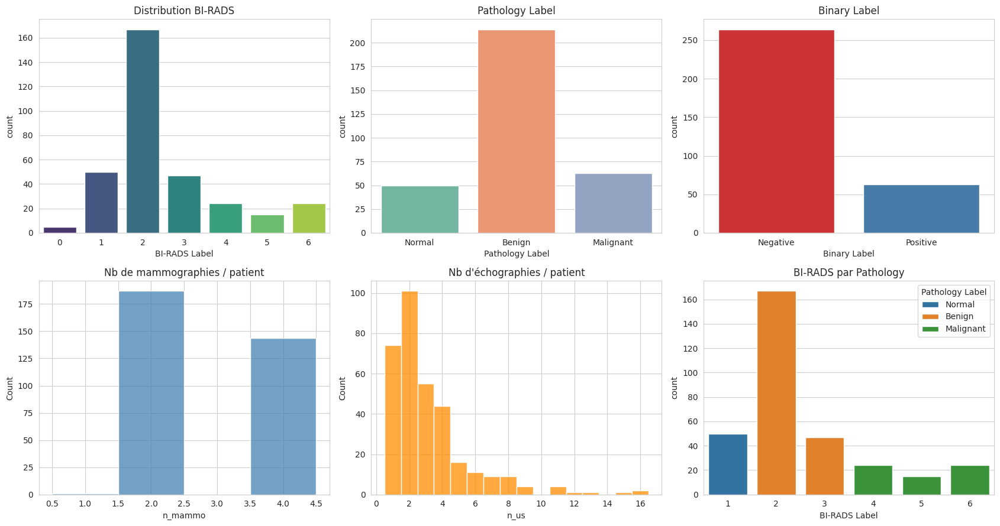

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

sns.countplot(data=ann, x="BI-RADS Label", ax=axes[0, 0], palette="viridis")
axes[0, 0].set_title("Distribution BI-RADS")

sns.countplot(data=ann, x="Pathology Label", ax=axes[0, 1],
              order=["Normal", "Benign", "Malignant"], palette="Set2")
axes[0, 1].set_title("Pathology Label")

sns.countplot(data=ann, x="Binary Label", ax=axes[0, 2],
              order=["Negative", "Positive"], palette="Set1")
axes[0, 2].set_title("Binary Label")

sns.histplot(inv["n_mammo"], discrete=True, ax=axes[1, 0], color="steelblue")
axes[1, 0].set_title("Nb de mammographies / patient")

sns.histplot(inv["n_us"], discrete=True, ax=axes[1, 1], color="darkorange")
axes[1, 1].set_title("Nb d'échographies / patient")

sns.countplot(data=df.dropna(subset=["Pathology Label"]), x="BI-RADS Label",
              hue="Pathology Label", ax=axes[1, 2])
axes[1, 2].set_title("BI-RADS par Pathology")

plt.tight_layout()
plt.show()

Étape 2 validée. Voici ce que ton output nous apprend.

###### Ce qui est propre

- Aucun doublon, et les 332 IDs du TSV correspondent exactement aux 332 dossiers.

- Les 5 labels manquants sont bien les 5 cas BI-RADS 0 (évaluation incomplète). Ils n’ont pas de label exploitable, donc on les marquera unlabeled à l’Étape 7 (exclus de l’entraînement supervisé, gardés pour la démo).

- Binary Label et Pathology Label sont des fonctions déterministes du BI-RADS : 1 → Normal, 2-3 → Benign, 4-5-6 → Malignant. Ce sont des colonnes dérivées, pas des informations indépendantes. Notre vraie cible est donc le BI-RADS.

##### Points d’attention

- Déséquilibre fort : BI-RADS 2 = 167 patients, contre 15 pour le BI-RADS 5 et 5 pour le BI-RADS 0. Il faudra stratifier le split et prévoir des poids de classes.

- IDs atypiques : 4 IDs ont un suffixe à 3 chiffres (y181, y211 ×2, y221), probablement des erreurs de saisie. Ils existent dans le TSV et dans les dossiers, donc on les garde, mais on les liste. Les IDs doivent rester des strings, à cause des zéros initiaux et des longueurs variables (7 à 9).

-Mammographies incomplètes (environ 13 patients) :
    - 5 patients ont des vues qui ne respectent pas la  convention de nommage (OTHER).

    - Il n’y a jamais exactement 3 fichiers (seulement 1, 2 ou 4), alors que des combinaisons comme L_CC, L_MLO, R_CC apparaissent. Il y a donc des vues dupliquées, du type L_CC_1 et L_CC_2.

    -1 patient n’a qu’une seule mammographie.
-Échographies :
    - Le côté est UNK (inconnu) pour 78 patients (23 %), ce qui empêche de lier ces images au côté de la mammographie.

    - Le nombre d’images varie de 1 à 16 par patient (distribution asymétrique). Le split devra absolument se faire par patient.

-11 patients sans PDF (3,3 %), à traiter à l’Étape 4.

-Taille des fichiers hétérogène : certaines mammographies pèsent 1,5 à 3,7 Mo et d’autres 13 à 17 Mo. Les résolutions sont donc probablement très différentes, ce qu’on mesure à l’étape suivante.

-Risque de fuite à vérifier : les rapports PDF contiennent peut-être la conclusion BI-RADS. Si c’est le cas, l’agent RAG/Reasoning pourrait « lire la réponse ». On le vérifie ici.

# Étape 3 : Format & integrity check

### 3.1 Table au niveau fichier + conventions de nommage

In [11]:
pat_mammo = re.compile(r"^(?P<pid>.+)_(?P<side>[LR])_(?P<view>CC|MLO)_(?P<idx>\d+)\.png$")
pat_us    = re.compile(r"^(?P<pid>.+)_US_(?P<side>[LR]|UNK)_(?P<idx>\d+)\.png$")

recs = []
for f in sorted(IMG_ROOT.rglob("*")):
    if not f.is_file():
        continue
    pid = f.relative_to(IMG_ROOT).parts[0]
    ext = f.suffix.lower()
    side = view = idx = None

    if ext == ".png":
        modality = f.parent.name                      # Mammogram / Ultrasound / autre
        pat = pat_mammo if modality == "Mammogram" else pat_us if modality == "Ultrasound" else None
        m = pat.match(f.name) if pat else None
        name_ok = bool(m) and m.group("pid") == pid
        if m:
            side = m.group("side"); idx = int(m.group("idx"))
            view = m.groupdict().get("view")
    elif ext == ".pdf":
        modality = "Report"
        name_ok = f.name == f"{pid}_US_MG_Report.pdf"
    else:
        modality, name_ok = "Other", False

    recs.append(dict(path=str(f), patient=pid, modality=modality, filename=f.name, ext=ext,
                     side=side, view=view, idx=idx, name_ok=name_ok,
                     size_kb=f.stat().st_size / 1024))

files_df = pd.DataFrame(recs)
print(files_df.groupby(["modality", "ext"]).size().to_string())

print("\n=== Fichiers hors convention de nommage ===")
bad = files_df[~files_df["name_ok"]]
print(len(bad), "fichiers")
display(bad[["patient", "modality", "filename"]])

print("\n=== Vues mammo dupliquées (même patient, côté, incidence) ===")
mm = files_df[(files_df["modality"] == "Mammogram") & files_df["name_ok"]]
dup = mm.groupby(["patient", "side", "view"]).size().reset_index(name="n")
display(dup[dup["n"] > 1])

print("\n=== IDs avec suffixe atypique ===")
print(ann.loc[ann["id_suffix"].str.len() > 2, ["Patient ID", "BI-RADS Label"]].to_string(index=False))

modality    ext 
Mammogram   .png     951
Report      .pdf     321
Ultrasound  .png    1050

=== Fichiers hors convention de nommage ===
13 fichiers


,patient,modality,filename
280,01566y211,Mammogram,01566y21_L_CC_2.png
281,01566y211,Mammogram,01566y21_L_MLO_1.png
297,0165y09,Ultrasound,0165y09_US_1.png
549,03128y211,Mammogram,03128y21_R_CC_1.png
550,03128y211,Mammogram,03128y21_R_MLO_1.png
720,04412y221,Mammogram,04412y22_L_CC_1.png
721,04412y221,Mammogram,04412y22_L_MLO_1.png
1656,2429y17,Mammogram,2429y17_R_UNK_1.png
2088,3912y19,Ultrasound,3912y19_L_UNK_1.png
2137,4105y18,Mammogram,4105y18_L_CC.png



=== Vues mammo dupliquées (même patient, côté, incidence) ===


,patient,side,view,n
273,04902y22,R,CC,2
362,0721y18,R,CC,2
397,1016y15,R,CC,2
520,1777y11,R,CC,2
575,2053y14,R,MLO,2
805,3638y16,R,CC,2



=== IDs avec suffixe atypique ===
Patient ID  BI-RADS Label
 01566y211              4
 04412y221              4
  7708y181              4
 03128y211              5


### 3.2 Intégrité des PNG : ouverture, dimensions, mode

In [12]:
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

Image.MAX_IMAGE_PIXELS = None

def check_png(path):
    out = {"path": path, "ok": True, "error": None}
    try:
        with Image.open(path) as im:
            out.update(width=im.width, height=im.height, mode=im.mode, fmt=im.format,
                       info_keys=",".join(sorted(map(str, im.info.keys()))))
            im.verify()   # contrôle l'intégrité du fichier (CRC, chunks)
    except Exception as e:
        out.update(ok=False, error=repr(e)[:150])
    return out

png_paths = files_df.loc[files_df["ext"] == ".png", "path"].tolist()
with ThreadPoolExecutor(max_workers=4) as ex:
    res = list(tqdm(ex.map(check_png, png_paths), total=len(png_paths)))

png_df = files_df.merge(pd.DataFrame(res), on="path", how="inner")
png_df["aspect"] = (png_df["width"] / png_df["height"]).round(3)
png_df["megapixels"] = (png_df["width"] * png_df["height"] / 1e6).round(2)

print("Images corrompues :", (~png_df["ok"]).sum())
display(png_df.loc[~png_df["ok"], ["patient", "filename", "error"]])

for mod in ["Mammogram", "Ultrasound"]:
    d = png_df[png_df["modality"] == mod]
    print(f"\n================ {mod} ({len(d)} images) ================")
    print("Modes couleur :", d["mode"].value_counts().to_dict())
    print("Formats       :", d["fmt"].value_counts().to_dict())
    print("Métadonnées PNG (info_keys) :", d["info_keys"].value_counts().head(5).to_dict())
    print("\nTop 10 résolutions (w x h) :")
    print(d.groupby(["width", "height"]).size().sort_values(ascending=False).head(10).to_string())
    print("\nNb de résolutions distinctes :", d.groupby(["width", "height"]).ngroups)
    print(d[["width", "height", "megapixels", "aspect", "size_kb"]].describe().round(2).to_string())

  0%|          | 0/2001 [00:00<?, ?it/s]

Images corrompues : 1


,patient,filename,error
266,0165y09,0165y09_US_1.png,"UnidentifiedImageError(""cannot identify image ..."



================ Mammogram (951 images) ================
Modes couleur : {'L': 949, 'RGBA': 2}
Formats       : {'PNG': 951}
Métadonnées PNG (info_keys) : {'': 949, 'Software,dpi': 2}

Top 10 résolutions (w x h) :
width   height
4728.0  5928.0    875
2800.0  3518.0     76

Nb de résolutions distinctes : 2
         width   height  megapixels  aspect   size_kb
count   951.00   951.00      951.00   951.0    951.00
mean   4573.92  5735.40       26.58     0.8  12940.16
std     523.08   653.85        4.93     0.0   3806.04
min    2800.00  3518.00        9.85     0.8    939.89
25%    4728.00  5928.00       28.03     0.8  12154.51
50%    4728.00  5928.00       28.03     0.8  13698.30
75%    4728.00  5928.00       28.03     0.8  15029.67
max    4728.00  5928.00       28.03     0.8  21914.58

================ Ultrasound (1050 images) ================
Modes couleur : {'RGBA': 1049}
Formats       : {'PNG': 1049}
Métadonnées PNG (info_keys) : {'Software,dpi': 1049}

Top 10 résolutions (w x h) :
wid

### 3.4 Intégrité des PDF + recherche de fuite BI-RADS

In [13]:
try:
    from pypdf import PdfReader
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pypdf"])
    from pypdf import PdfReader

def check_pdf(path):
    out = {"path": path, "ok": True, "error": None}
    try:
        with open(path, "rb") as fh:
            out["header_ok"] = fh.read(5) == b"%PDF-"
        r = PdfReader(path)
        out["n_pages"] = len(r.pages)
        out["encrypted"] = r.is_encrypted
        txt = "\n".join((p.extract_text() or "") for p in r.pages)
        out["n_chars"] = len(txt)
        out["has_birads"] = bool(re.search(r"bi-?\s?rads", txt, flags=re.I))
        out["text"] = txt
    except Exception as e:
        out.update(ok=False, error=repr(e)[:150])
    return out

pdf_paths = files_df.loc[files_df["ext"] == ".pdf", "path"].tolist()
pdf_res = [check_pdf(p) for p in tqdm(pdf_paths)]
pdf_df = files_df.merge(pd.DataFrame(pdf_res), on="path", how="inner")

print("PDF illisibles      :", (~pdf_df["ok"]).sum())
print("En-tête %PDF invalide:", (pdf_df["header_ok"] == False).sum())
print("PDF chiffrés        :", pdf_df["encrypted"].sum())
print("PDF sans texte (scannés ?) :", (pdf_df["n_chars"] < 50).sum())
print("Rapports mentionnant BI-RADS :", pdf_df["has_birads"].sum(), "/", len(pdf_df))
print("\nPages  :", pdf_df["n_pages"].value_counts().to_dict())
print(pdf_df["n_chars"].describe().round(0).to_string())

# Extrait d'un rapport (200 premiers caractères suffisent pour voir la langue/structure)
print("\n--- Extrait ---")
print(pdf_df.iloc[0]["text"][:600])

  0%|          | 0/321 [00:00<?, ?it/s]

PDF illisibles      : 0
En-tête %PDF invalide: 0
PDF chiffrés        : 0
PDF sans texte (scannés ?) : 1
Rapports mentionnant BI-RADS : 312 / 321

Pages  : {1: 296, 2: 25}
count     321.0
mean     1614.0
std       379.0
min         0.0
25%      1447.0
50%      1629.0
75%      1799.0
max      3217.0

--- Extrait ---
ID: 0016/11
Ref. Dr: Amr Mahmoud Procedure: Mammography &  US Breast 
Study Date: 6/15/2021 12:30:00 PM Clinical Data: Left Breast Cancer 
BREAST MAMMOGRAPHY
 Both breast shadows of (ACR A).
 No other abnormal densities.
 Still noted right outer quadrant macro-calcification focus noted.
 No pathological calcification 
 Right axillary nodal shadows are noted 
BRAST UL TRASONOGRAPHY 
 Regression in size regarding the previously reported left 
supraclavicular oval shaped lymph node currently averaging 
5mm….mostly nonspecific..BIRADS 2
 Clear post-operative left scar with no recurrent or d


### 3.5 Sauvegarde des tables pour les prochaines étapes

In [14]:
files_df.to_csv(WORK_DIR / "files_inventory.csv", index=False)
png_df.drop(columns=[]).to_csv(WORK_DIR / "png_integrity.csv", index=False)
pdf_df.drop(columns=["text"]).to_csv(WORK_DIR / "pdf_integrity.csv", index=False)
print("Tables sauvegardées dans", WORK_DIR)

Tables sauvegardées dans /kaggle/working


**Conclusion section 3.** 1 image vide (`0165y09_US_1.png`), 13 fichiers hors convention de nommage, 2 résolutions de mammographie (4728×5928 et 2800×3518), 2 mammographies RGBA. 312 rapports sur 321 mentionnent le BI-RADS : le texte contient la réponse, donc il faudra une version aveugle (section 6).

# Étape 4 : Missing modality handling

### normalisation des noms + table de complétude par patient

In [15]:
# ---------- 1) Normalisation tolérante des côtés / vues ----------
def parse_mammo(name):
    m = re.search(r"_(L|R)_(CC|MLO|UNK)(?:_(\d+))?\.png$", name)
    return (m.group(1), m.group(2), int(m.group(3)) if m.group(3) else np.nan) if m else (None, None, np.nan)

def parse_us(name):
    m = re.search(r"_(?:US_)?(L|R|UNK)(?:_UNK)?_(\d+)\.png$", name)
    if m:
        return m.group(1), None, int(m.group(2))
    m = re.search(r"_US_(\d+)\.png$", name)          # ex: 0165y09_US_1.png (côté absent)
    return ("UNK", None, int(m.group(1))) if m else (None, None, np.nan)

img = png_df.drop(columns=["side", "view", "idx"]).copy()
parsed = img.apply(lambda r: parse_mammo(r["filename"]) if r["modality"] == "Mammogram"
                   else parse_us(r["filename"]), axis=1, result_type="expand")
img[["side", "view", "idx"]] = parsed.values

img["valid"] = img["ok"].eq(True)
img["id_in_name"] = img["filename"].str.split("_").str[0]
img["id_mismatch"] = img["id_in_name"] != img["patient"]

print("Images invalides (exclues)        :", (~img["valid"]).sum())
print("Fichiers dont l'ID ≠ nom du dossier:", img["id_mismatch"].sum())
for pid in img.loc[img["id_mismatch"], "patient"].unique():
    fixed = img.loc[img["patient"] == pid, "id_in_name"].iloc[0]
    print(f"  {pid} -> ID dans les fichiers : {fixed} | existe déjà dans le TSV : {fixed in ids_tsv}")

# ---------- 2) Agrégation par patient ----------
mm = img[(img["modality"] == "Mammogram") & img["valid"]].copy()
mm["sv"] = mm["side"] + "_" + mm["view"]
mm_g = mm.groupby("patient").agg(
    n_mammo=("path", "size"),
    mammo_views=("sv", lambda s: ",".join(sorted(set(s)))),
    mammo_min_width=("width", "min"),
    n_mammo_dup=("sv", lambda s: int(s.duplicated().sum())),
).reset_index()

us = img[(img["modality"] == "Ultrasound") & img["valid"]]
us_g = us.groupby("patient").agg(
    n_us=("path", "size"),
    us_sides=("side", lambda s: ",".join(sorted(set(s)))),
).reset_index()

rep = pdf_df[["patient", "ok", "n_pages", "n_chars", "has_birads"]].rename(columns={"ok": "report_ok"})

comp = (ann.rename(columns={"Patient ID": "patient"})
           [["patient", "BI-RADS Label", "Binary Label", "Pathology Label"]]
        .merge(mm_g, on="patient", how="left")
        .merge(us_g, on="patient", how="left")
        .merge(rep, on="patient", how="left"))

comp["n_mammo"] = comp["n_mammo"].fillna(0).astype(int)
comp["n_us"] = comp["n_us"].fillna(0).astype(int)
comp["mammo_views"] = comp["mammo_views"].fillna("")
comp["us_sides"] = comp["us_sides"].fillna("")

# ---------- 3) Masques de modalités ----------
comp["has_mammo"] = comp["n_mammo"] > 0
comp["has_us"] = comp["n_us"] > 0
comp["has_report"] = comp["report_ok"].eq(True) & (comp["n_chars"].fillna(0) >= 50)

def full_sides(v):
    s = set(v.split(",")) if v else set()
    return "".join(x for x in "LR" if {f"{x}_CC", f"{x}_MLO"} <= s)

comp["full_pair_sides"] = comp["mammo_views"].apply(full_sides)
comp["has_full_pair"] = comp["full_pair_sides"] != ""

# ---------- 4) Flags de qualité ----------
comp["flag_view_unknown"] = comp["mammo_views"].str.contains("UNK")
comp["flag_dup_view"] = comp["n_mammo_dup"].fillna(0) > 0
comp["flag_id_mismatch"] = comp["patient"].isin(img.loc[img["id_mismatch"], "patient"])
comp["flag_us_side_unk"] = comp["us_sides"].eq("UNK")
comp["small_res"] = comp["mammo_min_width"] < 4000

# ---------- 5) Décision ----------
def decide(r):
    if pd.isna(r["Binary Label"]):
        return "unlabeled"            # BI-RADS 0
    if not (r["has_mammo"] and r["has_us"]):
        return "exclude"              # modalité image manquante
    if not r["has_report"]:
        return "keep_no_report"
    if not r["has_full_pair"]:
        return "keep_partial_mammo"
    return "keep_complete"

comp["status"] = comp.apply(decide, axis=1)

print("\n=== Décision par patient ===")
print(comp["status"].value_counts().to_string())
print("\n=== Combinaisons (mammo, US, rapport) ===")
print(comp.groupby(["has_mammo", "has_us", "has_report"]).size().to_string())
print("\n=== Flags ===")
flags = [c for c in comp.columns if c.startswith("flag_")]
print(comp[flags].sum().to_string())

rare = ["flag_view_unknown", "flag_dup_view", "flag_id_mismatch"]
display(comp.loc[comp[rare].any(axis=1) | ~comp["has_report"] | ~comp["has_full_pair"],
                 ["patient", "BI-RADS Label", "mammo_views", "us_sides", "has_report", "status"] + rare])

print("\n=== Résolution mammo (small_res) vs Pathology (risque de biais d'appareil) ===")
print(pd.crosstab(comp["small_res"], comp["Pathology Label"].fillna("NaN")).to_string())

Images invalides (exclues)        : 1
Fichiers dont l'ID ≠ nom du dossier: 8
  01566y211 -> ID dans les fichiers : 01566y21 | existe déjà dans le TSV : True
  03128y211 -> ID dans les fichiers : 03128y21 | existe déjà dans le TSV : True
  04412y221 -> ID dans les fichiers : 04412y22 | existe déjà dans le TSV : True
  7708y181 -> ID dans les fichiers : 7708y18 | existe déjà dans le TSV : False

=== Décision par patient ===
status
keep_complete         312
keep_no_report         12
unlabeled               5
keep_partial_mammo      3

=== Combinaisons (mammo, US, rapport) ===
has_mammo  has_us  has_report
True       True    False          12
                   True          320

=== Flags ===
flag_view_unknown     1
flag_dup_view         6
flag_id_mismatch      4
flag_us_side_unk     78


,patient,BI-RADS Label,mammo_views,us_sides,has_report,status,flag_view_unknown,flag_dup_view,flag_id_mismatch
13,01566y211,4,"L_CC,L_MLO",L,True,keep_complete,False,False,True
21,04902y22,6,R_CC,R,True,keep_partial_mammo,False,True,False
34,2429y17,3,"L_CC,L_MLO,R_MLO,R_UNK",UNK,True,keep_complete,True,False,False
58,04412y221,4,"L_CC,L_MLO",L,True,keep_complete,False,False,True
84,00953y23,5,"R_CC,R_MLO",R,False,keep_no_report,False,False,False
92,04734y22,4,L_MLO,L,False,keep_no_report,False,False,False
105,1777y11,2,"L_CC,L_MLO,R_CC",UNK,True,keep_complete,False,True,False
143,00701y23,4,"L_CC,L_MLO",L,False,keep_no_report,False,False,False
146,0721y18,2,"L_CC,L_MLO,R_CC",UNK,True,keep_complete,False,True,False
147,00074y23,5,"R_CC,R_MLO",R,False,keep_no_report,False,False,False



=== Résolution mammo (small_res) vs Pathology (risque de biais d'appareil) ===
Pathology Label  Benign  Malignant  NaN  Normal
small_res                                      
False               203         49    5      47
True                 11         14    0       3


### vérification visuelle des vues dupliquées

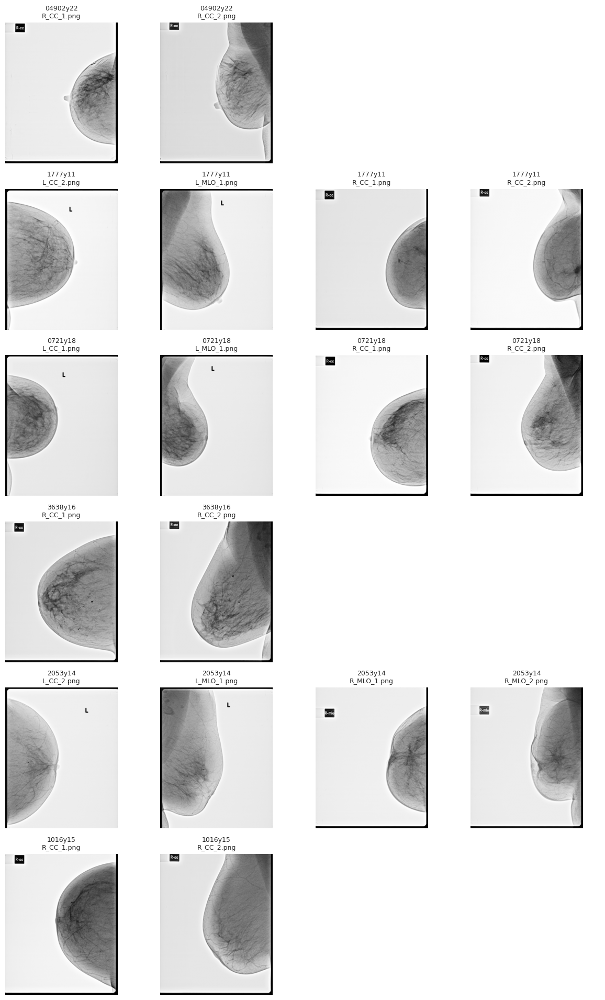

In [16]:
import matplotlib.pyplot as plt

dup_patients = comp.loc[comp["flag_dup_view"], "patient"].tolist()
fig, axes = plt.subplots(len(dup_patients), 4, figsize=(12, 3.2 * len(dup_patients)))
axes = np.atleast_2d(axes)

for i, pid in enumerate(dup_patients):
    files = mm[mm["patient"] == pid].sort_values(["side", "view", "idx"])
    for j in range(4):
        ax = axes[i, j]
        ax.axis("off")
        if j < len(files):
            r = files.iloc[j]
            with Image.open(r["path"]) as im:
                small = np.asarray(im.convert("L").reduce(12))
            ax.imshow(small, cmap="gray")
            ax.set_title(f"{pid}\n{r['filename'].split('_', 1)[1]}", fontsize=9)

plt.tight_layout()
plt.show()

### sauvegarde

In [17]:
img.to_csv(WORK_DIR / "images_clean_table.csv", index=False)
comp.to_csv(WORK_DIR / "patient_completeness.csv", index=False)
print("Sauvegardé :", [p.name for p in WORK_DIR.glob("*.csv")])

Sauvegardé : ['patient_completeness.csv', 'files_inventory.csv', 'pdf_integrity.csv', 'images_clean_table.csv', 'png_integrity.csv']


# Étape 4b : Corrections des vues, group_id et détection de doublons

### correction des vues + contrôle visuel de 2429y17

Vues encore dupliquées après correction : 0


,patient,filename,view,view_fixed,fix_reason
697,04902y22,04902y22_R_CC_1.png,CC,CC,dup_view
698,04902y22,04902y22_R_CC_2.png,CC,MLO,dup_view
883,0721y18,0721y18_R_CC_1.png,CC,CC,dup_view
884,0721y18,0721y18_R_CC_2.png,CC,MLO,dup_view
949,1016y15,1016y15_R_CC_1.png,CC,CC,dup_view
950,1016y15,1016y15_R_CC_2.png,CC,MLO,dup_view
1192,1777y11,1777y11_R_CC_1.png,CC,CC,dup_view
1193,1777y11,1777y11_R_CC_2.png,CC,MLO,dup_view
1292,2053y14,2053y14_R_MLO_1.png,MLO,CC,dup_view
1293,2053y14,2053y14_R_MLO_2.png,MLO,MLO,dup_view


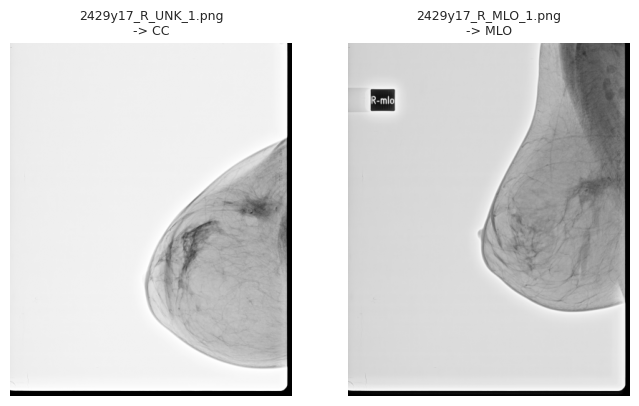

In [18]:
mm = img[(img["modality"] == "Mammogram") & img["valid"]].copy()
mm["view_fixed"] = mm["view"]
mm["fix_reason"] = ""

# a) vues dupliquées : idx le plus bas = CC, l'autre = MLO (confirmé visuellement sur les 6 cas)
dups = mm[mm["view"].isin(["CC", "MLO"])].groupby(["patient", "side", "view"]).filter(lambda g: len(g) > 1)
for (pid, side, _), g in dups.groupby(["patient", "side", "view"]):
    g = g.sort_values("idx")
    for rank, i in enumerate(g.index):
        mm.loc[i, "view_fixed"] = "CC" if rank == 0 else "MLO"
        mm.loc[i, "fix_reason"] = "dup_view"

# b) vue UNK : on prend la vue manquante du même côté
for i, r in mm[mm["view"] == "UNK"].iterrows():
    have = set(mm.loc[(mm["patient"] == r["patient"]) & (mm["side"] == r["side"])
                      & mm["view_fixed"].isin(["CC", "MLO"]), "view_fixed"])
    missing = {"CC", "MLO"} - have
    if len(missing) == 1:
        mm.loc[i, "view_fixed"] = missing.pop()
        mm.loc[i, "fix_reason"] = "unk_by_elimination"

mm["sv_fixed"] = mm["side"] + "_" + mm["view_fixed"]
still_dup = mm.groupby(["patient", "sv_fixed"]).size().gt(1).sum()
print("Vues encore dupliquées après correction :", still_dup)
display(mm.loc[mm["fix_reason"] != "", ["patient", "filename", "view", "view_fixed", "fix_reason"]])

# contrôle visuel : 2429y17 (R_UNK doit ressembler à une CC, sans muscle pectoral)
f = mm[(mm["patient"] == "2429y17") & (mm["side"] == "R")].sort_values("view_fixed")
fig, axes = plt.subplots(1, len(f), figsize=(4 * len(f), 5))
for ax, (_, r) in zip(np.atleast_1d(axes), f.iterrows()):
    with Image.open(r["path"]) as im:
        ax.imshow(np.asarray(im.convert("L").reduce(12)), cmap="gray")
    ax.set_title(f"{r['filename']}\n-> {r['view_fixed']}", fontsize=9); ax.axis("off")
plt.show()

### group_id + doublons d’images

In [19]:
import hashlib
from collections import defaultdict
from scipy.stats import fisher_exact

# ---------- group_id : on enlève le chiffre en trop des IDs atypiques ----------
def base_id(pid):
    m = re.match(r"^(\d+)y(\d{2})\d?$", pid)
    return f"{m.group(1)}y{m.group(2)}" if m else pid

ann2 = ann.rename(columns={"Patient ID": "patient"}).copy()
ann2["group_id"] = ann2["patient"].map(base_id)
multi = ann2[ann2.duplicated("group_id", keep=False)].sort_values("group_id")
print("Groupes contenant plusieurs patients :")
display(multi[["group_id", "patient", "BI-RADS Label", "Pathology Label"]])

# même numéro (zéros de tête ignorés) avec des suffixes différents : information seulement
ann2["num"] = ann2["patient"].str.extract(r"^(\d+)y")[0].str.lstrip("0")
same_num = ann2[ann2.duplicated("num", keep=False)].sort_values("num")
print("\nMême numéro, suffixes différents :", len(same_num), "lignes")
display(same_num[["num", "patient", "BI-RADS Label"]].head(20))

# ---------- doublons d'images (MD5 sur les fichiers de même taille uniquement) ----------
valid_img = img[img["valid"]]
by_size = defaultdict(list)
for p in valid_img["path"]:
    by_size[os.stat(p).st_size].append(p)
cand = [p for ps in by_size.values() if len(ps) > 1 for p in ps]
print("\nFichiers à hasher (taille identique à un autre) :", len(cand))

def md5(p):
    h = hashlib.md5()
    with open(p, "rb") as fh:
        while chunk := fh.read(1 << 20):
            h.update(chunk)
    return p, h.hexdigest()

with ThreadPoolExecutor(max_workers=4) as ex:
    hh = dict(tqdm(ex.map(md5, cand), total=len(cand)))

hd = pd.DataFrame({"path": list(hh), "md5": list(hh.values())}).merge(
        valid_img[["path", "patient", "modality", "filename"]], on="path")
dupimg = hd[hd.duplicated("md5", keep=False)].copy()
dupimg["n_patients"] = dupimg.groupby("md5")["patient"].transform("nunique")
print("Groupes d'images identiques       :", dupimg["md5"].nunique())
print("  dont entre patients différents  :", dupimg.loc[dupimg["n_patients"] > 1, "md5"].nunique())
print("  dont au sein d'un même patient  :", dupimg.loc[dupimg["n_patients"] == 1, "md5"].nunique())
dupimg["md5"] = dupimg["md5"].str[:8]
display(dupimg.sort_values("md5")[["md5", "patient", "modality", "filename", "n_patients"]].head(30))

Groupes contenant plusieurs patients :


,group_id,patient,BI-RADS Label,Pathology Label
12,01566y21,01566y21,5,Malignant
13,01566y21,01566y211,4,Malignant
272,03128y21,03128y211,5,Malignant
273,03128y21,03128y21,4,Malignant
57,04412y22,04412y22,4,Malignant
58,04412y22,04412y221,4,Malignant



Même numéro, suffixes différents : 18 lignes


,num,patient,BI-RADS Label
41,1000,1000y17,2
303,1000,1000y16,6
12,1566,01566y21,5
13,1566,01566y211,4
245,1893,1893y11,4
235,1893,1893y15,4
238,263,00263y23,6
194,263,0263y19,3
272,3128,03128y211,5
273,3128,03128y21,4



Fichiers à hasher (taille identique à un autre) : 21


  0%|          | 0/21 [00:00<?, ?it/s]

Groupes d'images identiques       : 6
  dont entre patients différents  : 0
  dont au sein d'un même patient  : 6


,md5,patient,modality,filename,n_patients
3,2025987f,00278y20,Ultrasound,00278y20_US_L_1.png,1
4,2025987f,00278y20,Ultrasound,00278y20_US_L_2.png,1
19,529da215,4908y16,Ultrasound,4908y16_US_L_1.png,1
20,529da215,4908y16,Ultrasound,4908y16_US_L_4.png,1
0,7ee8b7a1,00263y23,Ultrasound,00263y23_US_L_15.png,1
1,7ee8b7a1,00263y23,Ultrasound,00263y23_US_L_5.png,1
2,7ee8b7a1,00263y23,Ultrasound,00263y23_US_L_6.png,1
15,a3fc80e3,06025y20,Ultrasound,06025y20_US_R_4.png,1
16,a3fc80e3,06025y20,Ultrasound,06025y20_US_R_5.png,1
13,f50160aa,04747y22,Ultrasound,04747y22_US_L_1.png,1


### table maître par patient + test des raccourcis

In [20]:
mg = mm.groupby("patient")["sv_fixed"].apply(lambda s: ",".join(sorted(set(s)))).rename("mammo_views_fixed").reset_index()

pm = (comp.drop(columns=["mammo_views", "full_pair_sides", "has_full_pair",
                         "flag_view_unknown", "flag_dup_view", "status"])
          .merge(mg, on="patient", how="left")
          .merge(ann2[["patient", "group_id"]], on="patient", how="left"))

pm["full_pair_sides"] = pm["mammo_views_fixed"].apply(full_sides)
pm["has_full_pair"] = pm["full_pair_sides"] != ""
pm["bilateral"] = pm["full_pair_sides"].str.len() == 2
pm["labeled"] = pm["Binary Label"].notna()
pm["missing_report"] = ~pm["has_report"]
pm["partial_mammo"] = ~pm["has_full_pair"]

print("Patients étiquetés            :", pm["labeled"].sum())
print("Non étiquetés (BI-RADS 0)     :", (~pm["labeled"]).sum())
print("Mammo partielle (étiquetés)   :", (pm["partial_mammo"] & pm["labeled"]).sum())
print("Sans rapport (étiquetés)      :", (pm["missing_report"] & pm["labeled"]).sum())
display(pm.loc[pm["partial_mammo"], ["patient", "BI-RADS Label", "mammo_views_fixed", "labeled"]])

# ---------- raccourcis métadonnées -> label ----------
lab = pm[pm["labeled"]]
print("\n=== Taux de Malignant selon des variables NON médicales ===")
for col in ["small_res", "missing_report", "bilateral", "flag_us_side_unk"]:
    t = pd.crosstab(lab[col], lab["Pathology Label"].eq("Malignant"))
    rate = lab.groupby(col)["Pathology Label"].apply(lambda s: (s == "Malignant").mean()).round(2).to_dict()
    print(f"{col:<18} taux : {rate} | p(Fisher) = {fisher_exact(t.values)[1]:.2g}")

print("\nNb d'échographies par classe :")
print(lab.groupby("Pathology Label")["n_us"].describe().round(1).to_string())

pm.to_csv(WORK_DIR / "patient_master.csv", index=False)
mm.to_csv(WORK_DIR / "mammo_views_fixed.csv", index=False)
print("\nSauvegardé : patient_master.csv, mammo_views_fixed.csv")

Patients étiquetés            : 327
Non étiquetés (BI-RADS 0)     : 5
Mammo partielle (étiquetés)   : 1
Sans rapport (étiquetés)      : 12


,patient,BI-RADS Label,mammo_views_fixed,labeled
92,04734y22,4,L_MLO,True



=== Taux de Malignant selon des variables NON médicales ===
small_res          taux : {False: 0.16, True: 0.5} | p(Fisher) = 0.00011
missing_report     taux : {False: 0.17, True: 0.92} | p(Fisher) = 6.5e-08
bilateral          taux : {False: 0.34, True: 0.0} | p(Fisher) = 1.2e-18
flag_us_side_unk   taux : {False: 0.25, True: 0.0} | p(Fisher) = 8.4e-09

Nb d'échographies par classe :
                 count  mean  std  min  25%  50%  75%   max
Pathology Label                                            
Benign           214.0   3.0  2.2  1.0  2.0  2.0  4.0  15.0
Malignant         63.0   4.4  3.2  1.0  2.0  4.0  5.5  16.0
Normal            50.0   2.3  1.8  1.0  1.0  2.0  3.0   9.0

Sauvegardé : patient_master.csv, mammo_views_fixed.csv


# Étape 4c : Application des décisions (group_id, exclusions, vues corrigées)

In [21]:
# ---------- 1) group_id strict : numéro sans zéros de tête ----------
pm["group_id"] = pm["patient"].str.extract(r"^(\d+)y")[0].str.lstrip("0")
print("Patients :", len(pm), "| groupes :", pm["group_id"].nunique())

# ---------- 2) table finale des images ----------
im_all = img.merge(mm[["path", "view_fixed", "fix_reason"]], on="path", how="left")
im_all["view_final"] = im_all["view_fixed"]
im_all["exclude_reason"] = ""
im_all.loc[~im_all["valid"], "exclude_reason"] = "corrupt_or_empty"

# doublons exacts : on garde l'idx le plus bas
dd = (hd[hd.duplicated("md5", keep=False)]
        .merge(im_all[["path", "idx"]], on="path")
        .sort_values(["md5", "idx"]))
redundant = dd[dd.duplicated("md5", keep="first")]["path"]
im_all.loc[im_all["path"].isin(redundant), "exclude_reason"] = "exact_duplicate"

print("\nImages par statut :")
print(im_all["exclude_reason"].replace("", "kept").value_counts().to_string())
print(im_all[im_all["exclude_reason"] != ""][["patient", "filename", "exclude_reason"]].to_string(index=False))

im_ok = im_all[im_all["exclude_reason"] == ""].copy()
print("\nImages conservées par modalité :", im_ok["modality"].value_counts().to_dict())

us_n = (im_ok[im_ok["modality"] == "Ultrasound"].groupby("patient").size().rename("n_us_clean"))
pm = pm.drop(columns=["n_us_clean"], errors="ignore").merge(us_n, on="patient", how="left")

# ---------- 3) lien entre raccourcis (pour l'évaluation équitable) ----------
lab = pm[pm["labeled"]]
print("\n=== Bilatéral x Pathology ===")
print(pd.crosstab(lab["bilateral"], lab["Pathology Label"]).to_string())
print("\n=== Bilatéral x échographie côté inconnu ===")
print(pd.crosstab(lab["bilateral"], lab["flag_us_side_unk"]).to_string())
print("\n=== Sous-ensemble équitable : patients unilatéraux ===")
print(lab[~lab["bilateral"]]["Pathology Label"].value_counts().to_string())

pm.to_csv(WORK_DIR / "patient_master.csv", index=False)
im_ok.to_csv(WORK_DIR / "images_final_list.csv", index=False)

Patients : 332 | groupes : 323

Images par statut :
exclude_reason
kept                1993
exact_duplicate        7
corrupt_or_empty       1
 patient             filename   exclude_reason
00263y23 00263y23_US_L_15.png  exact_duplicate
00263y23  00263y23_US_L_6.png  exact_duplicate
00278y20  00278y20_US_L_2.png  exact_duplicate
 0165y09     0165y09_US_1.png corrupt_or_empty
 0249y16   0249y16_US_R_2.png  exact_duplicate
04747y22  04747y22_US_L_3.png  exact_duplicate
06025y20  06025y20_US_R_5.png  exact_duplicate
 4908y16   4908y16_US_L_4.png  exact_duplicate

Images conservées par modalité : {'Ultrasound': 1042, 'Mammogram': 951}

=== Bilatéral x Pathology ===
Pathology Label  Benign  Malignant  Normal
bilateral                                 
False                89         63      33
True                125          0      17

=== Bilatéral x échographie côté inconnu ===
flag_us_side_unk  False  True 
bilateral                     
False               185      0
True                

**Conclusion section 4.** 7 corrections de vues (6 CC/MLO mal nommées + 1 vue inconnue), 7 doublons exacts d'échographies (aucun entre patients), 3 paires de dossiers = deux seins de la même femme (`group_id`). Premiers raccourcis : 0 % de Malignant chez les patients bilatéraux, 92 % chez les patients sans rapport. Ces variables ne doivent jamais servir de feature.

# Étape 5A : diagnostic des images (polarité, bordures, alpha, quasi-doublons)

mesures sur toutes les images, environ 3 à 5 minutes

In [22]:
def diag_mammo(path):
    with Image.open(path) as im:
        mode = im.mode
        alpha_min, rgb_equal = np.nan, np.nan
        if mode == "RGBA":
            arr = np.asarray(im)
            alpha_min = int(arr[..., 3].min())
            rgb_equal = bool((arr[..., 0] == arr[..., 1]).all() and (arr[..., 1] == arr[..., 2]).all())
        a = np.asarray(im.convert("L"))
    h, w = a.shape
    s = a[::8, ::8]
    out = dict(path=path, h=h, w=w, mode=mode, alpha_min=alpha_min, rgb_equal=rgb_equal,
               med=float(np.median(s)), p1=float(np.percentile(s, 1)), p99=float(np.percentile(s, 99)))

    def run(prof, thr=0.9):
        n = 0
        for v in prof:
            if v > thr: n += 1
            else: break
        return n

    kx, ky = int(w * 0.06), int(h * 0.06)
    out["trim_l"] = run((a[:, :kx] < 25).mean(axis=0))
    out["trim_r"] = run((a[:, -kx:] < 25).mean(axis=0)[::-1])
    out["trim_t"] = run((a[:ky, :] < 25).mean(axis=1))
    out["trim_b"] = run((a[-ky:, :] < 25).mean(axis=1)[::-1])
    thumb = np.asarray(Image.fromarray(s).resize((64, 80), Image.BILINEAR), dtype=np.float32)
    return out, thumb


def diag_us(path):
    with Image.open(path) as im:
        rgba = np.asarray(im.convert("RGBA"))
    rgb = rgba[..., :3].astype(np.int16)
    alpha = rgba[..., 3]
    chroma = np.abs(rgb[..., 0] - rgb[..., 1]) + np.abs(rgb[..., 1] - rgb[..., 2])
    g = rgb.mean(axis=2)
    h, w = g.shape
    ys, xs = np.where(g > 15)
    out = dict(path=path, h=h, w=w, alpha_min=int(alpha.min()), alpha_not255=float((alpha < 255).mean()),
               chroma_frac=float((chroma > 30).mean()), mean_gray=float(g.mean()),
               black_frac=float((g < 10).mean()), white_frac=float((g > 240).mean()),
               bbox_w=int(xs.max() - xs.min() + 1) if len(xs) else 0,
               bbox_h=int(ys.max() - ys.min() + 1) if len(ys) else 0)
    c = g[int(h * .15):int(h * .85), int(w * .15):int(w * .85)].astype(np.uint8)
    thumb = np.asarray(Image.fromarray(c).resize((64, 45), Image.BILINEAR), dtype=np.float32)
    return out, thumb


mm_paths = im_ok.loc[im_ok["modality"] == "Mammogram", "path"].tolist()
us_paths = im_ok.loc[im_ok["modality"] == "Ultrasound", "path"].tolist()

with ThreadPoolExecutor(max_workers=4) as ex:
    rm = list(tqdm(ex.map(diag_mammo, mm_paths), total=len(mm_paths), desc="mammo"))
    ru = list(tqdm(ex.map(diag_us, us_paths), total=len(us_paths), desc="us"))

meta_cols = ["path", "patient", "filename", "side"]
dm = pd.DataFrame([x[0] for x in rm]); dm["row"] = range(len(dm)); Tm = np.stack([x[1].ravel() for x in rm])
du = pd.DataFrame([x[0] for x in ru]); du["row"] = range(len(du)); Tu = np.stack([x[1].ravel() for x in ru])

pm_cols = ["patient", "group_id", "Pathology Label", "bilateral"]
dm = (dm.merge(im_ok[meta_cols + ["view_final"]], on="path")
        .merge(pm[pm_cols], on="patient"))
du = (du.merge(im_ok[meta_cols], on="path").merge(pm[pm_cols], on="patient"))

dm["polarity"] = np.where(dm["med"] > 128, "negative", "positive")   # negative = fond blanc, tissu sombre
dm["ambiguous"] = dm["med"].between(80, 175)
dm["low_res"] = dm["w"] < 4000
print("Mammos :", len(dm), "| Échographies :", len(du))

mammo:   0%|          | 0/951 [00:00<?, ?it/s]

us:   0%|          | 0/1042 [00:00<?, ?it/s]

Mammos : 951 | Échographies : 1042


résumé mammographies

In [23]:
print("=== Polarité ===")
print(dm["polarity"].value_counts().to_string())
print("Cas ambigus (médiane entre 80 et 175) :", dm["ambiguous"].sum())
print("\nPolarité x résolution :")
print(pd.crosstab(dm["low_res"], dm["polarity"]).to_string())

labd = dm[dm["Pathology Label"].notna()]
print("\nPolarité x Pathology (niveau image) :")
print(pd.crosstab(labd["polarity"], labd["Pathology Label"]).to_string())

print("\n=== Bordures noires détectées (pixels par côté) ===")
print(dm.groupby("polarity")[["trim_l", "trim_r", "trim_t", "trim_b"]].agg(["median", "max"]).to_string())

print("\n=== Plage dynamique (p1, p99) par polarité ===")
print(dm.groupby("polarity")[["p1", "p99"]].describe().round(0).T.to_string())

print("\n=== Mammos RGBA ===")
display(dm[dm["mode"] == "RGBA"][["filename", "alpha_min", "rgb_equal"]])

=== Polarité ===
polarity
negative    875
positive     76
Cas ambigus (médiane entre 80 et 175) : 62

Polarité x résolution :
polarity  negative  positive
low_res                     
False          875         0
True             0        76

Polarité x Pathology (niveau image) :
Pathology Label  Benign  Malignant  Normal
polarity                                  
negative            642         97     122
positive             36         28      12

=== Bordures noires détectées (pixels par côté) ===
         trim_l      trim_r      trim_t      trim_b     
         median  max median  max median  max median  max
polarity                                                
negative   71.0   83    0.0   81    0.0   86    0.0   86
positive  168.0  168    0.0  168    1.5  211  211.0  211

=== Plage dynamique (p1, p99) par polarité ===
polarity   negative  positive
p1  count     875.0      76.0
    mean        6.0       0.0
    std         6.0       0.0
    min         0.0       0.0
    25%    

,filename,alpha_min,rgb_equal
879,4105y18_L_CC.png,255.0,True
880,4105y18_L_MLO.png,255.0,True


résumé échographies

In [24]:
print("=== Canal alpha ===")
print("alpha_min distinct :", du["alpha_min"].value_counts().to_dict())
print("Images avec pixels transparents :", (du["alpha_not255"] > 0).sum())

print("\n=== Statistiques US ===")
print(du[["chroma_frac", "mean_gray", "black_frac", "white_frac", "bbox_w", "bbox_h"]]
      .describe().round(3).T.to_string())
print("\nImages avec couleur notable (>2 % de pixels colorés) :", (du["chroma_frac"] > 0.02).sum())
print("Tailles de la zone non noire (bbox) :")
print(du.groupby(["bbox_w", "bbox_h"]).size().sort_values(ascending=False).head(8).to_string())

print("\n=== Raccourci image-niveau ? (moyennes par classe) ===")
print(du.groupby("Pathology Label")[["chroma_frac", "white_frac", "mean_gray", "bbox_w"]].mean().round(3).to_string())

=== Canal alpha ===
alpha_min distinct : {255: 1042}
Images avec pixels transparents : 0

=== Statistiques US ===
              count     mean     std      min      25%      50%      75%      max
chroma_frac  1042.0    0.023   0.006    0.017    0.020    0.021    0.024    0.065
mean_gray    1042.0   35.778  11.325    3.251   28.204   34.412   42.336   76.199
black_frac   1042.0    0.495   0.094    0.322    0.430    0.505    0.549    0.957
white_frac   1042.0    0.001   0.001    0.000    0.000    0.001    0.003    0.006
bbox_w       1042.0  960.000   0.000  960.000  960.000  960.000  960.000  960.000
bbox_h       1042.0  650.570  36.956  533.000  663.000  663.000  663.000  663.000

Images avec couleur notable (>2 % de pixels colorés) : 789
Tailles de la zone non noire (bbox) :
bbox_w  bbox_h
960     663       936
        541       103
        535         2
        533         1

=== Raccourci image-niveau ? (moyennes par classe) ===
                 chroma_frac  white_frac  mean_gray  bb

quasi-doublons entre patients

In [25]:
def top_pairs(T, meta, k=12):
    Z = T - T.mean(axis=1, keepdims=True)
    Z = Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-6)
    C = np.abs(Z @ Z.T)                       # |corrélation| : insensible à l'inversion de polarité
    iu = np.triu_indices(len(T), 1)
    pats = meta["patient"].values
    cross = pats[iu[0]] != pats[iu[1]]
    i, j = iu[0][cross], iu[1][cross]
    v = C[i, j]
    o = np.argsort(-v)[:k]
    return pd.DataFrame({"corr": v[o].round(4),
                         "a": meta["filename"].values[i[o]],
                         "b": meta["filename"].values[j[o]],
                         "same_group": meta["group_id"].values[i[o]] == meta["group_id"].values[j[o]]})

print("=== Mammos : paires les plus similaires entre patients différents ===")
display(top_pairs(Tm[dm["row"].values], dm))
print("\n=== Échographies : paires les plus similaires entre patients différents ===")
display(top_pairs(Tu[du["row"].values], du))

=== Mammos : paires les plus similaires entre patients différents ===


,corr,a,b,same_group
0,0.9877,1404y16_R_CC_1.png,1800y14_R_CC_1.png,False
1,0.9814,1777y11_R_CC_1.png,3753y19_R_CC_1.png,False
2,0.9813,2786y19_L_MLO_1.png,3391y18_L_MLO_1.png,False
3,0.9805,02967y20_R_MLO_1.png,3962y18_R_MLO_1.png,False
4,0.9797,1231y18_R_CC_1.png,2769y18_R_CC_1.png,False
5,0.9792,0585y12_R_MLO_1.png,06511y20_R_MLO_1.png,False
6,0.9792,1473y18_L_CC_1.png,2104y14_L_CC_1.png,False
7,0.9791,0343y15_R_MLO_1.png,0585y12_R_MLO_1.png,False
8,0.9790,02967y20_L_CC_1.png,04906y21_L_CC_1.png,False
9,0.9790,2226y18_R_CC_1.png,4639y16_R_CC_1.png,False



=== Échographies : paires les plus similaires entre patients différents ===


,corr,a,b,same_group
0,0.9963,0413y16_US_L_2.png,2592y17_US_UNK_1.png,False
1,0.9962,0413y16_US_L_2.png,4315y15_US_L_3.png,False
2,0.9961,0413y16_US_L_2.png,3679y19_US_R_2.png,False
3,0.9960,2592y17_US_UNK_1.png,4315y15_US_L_3.png,False
4,0.9960,3679y19_US_R_2.png,4315y15_US_L_3.png,False
5,0.9959,0413y16_US_L_2.png,3006y17_US_UNK_1.png,False
6,0.9959,2592y17_US_UNK_1.png,3679y19_US_R_2.png,False
7,0.9957,2592y17_US_UNK_1.png,3006y17_US_UNK_1.png,False
8,0.9955,3006y17_US_UNK_1.png,3679y19_US_R_2.png,False
9,0.9953,3006y17_US_UNK_1.png,4315y15_US_L_3.png,False


**Conclusion 5A.** Polarité = résolution : 875 mammographies négatives (fond blanc, haute résolution) et 76 positives (fond noir, basse résolution). Ce facteur correspond à l'appareil et est lié au label. Échographies : pas de transparence, largeur toujours 960 px, deux mises en page (663 px et 541 px de haut).

# Étape 5B : constantes et fonctions de prétraitement (versions finales)

### Mammographie : imports, constantes, `border_trim` (avec crochet `_FORCE`), `segment_breast`, `prep_mammo`

In [26]:
import cv2, itertools
from matplotlib.patches import Rectangle
cv2.setNumThreads(1)

PROC = WORK_DIR / "processed"
(PROC / "mammo").mkdir(parents=True, exist_ok=True)
(PROC / "us").mkdir(parents=True, exist_ok=True)

MM_W, MM_H = 1024, 1280     # taille finale mammographie (ratio 4:5)
WORK_H = 1600               # hauteur de travail avant recadrage

def clahe_u8(a, clip=2.0, tile=8):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(a)

# ---------- 2) détection de bordure plus tolérante ----------
_FORCE = None   # sert aux corrections manuelles de bordure (voir section 5D)
def border_trim(a, max_frac=0.08, dark=80, frac=0.5, tol=6):
    """Pixels de bordure sombre (<dark) à retirer de chaque côté : (gauche, droite, haut, bas).
    tol : nombre de pixels clairs tolérés (liseré) avant de considérer la bordure terminée."""
    if _FORCE is not None:
        return _FORCE
    H, W = a.shape
    def run(prof):
        n, miss = 0, 0
        for i, v in enumerate(prof):
            if v > frac: n, miss = i + 1, 0
            else:
                miss += 1
                if miss > tol: break
        return n
    d = a < dark
    kx, ky = int(W * max_frac), int(H * max_frac)
    return (run(d[:, :kx].mean(axis=0)), run(d[:, -kx:].mean(axis=0)[::-1]),
            run(d[:ky, :].mean(axis=1)), run(d[-ky:, :].mean(axis=1)[::-1]))

def segment_breast(g_small, k=13):
    g = cv2.GaussianBlur(g_small, (0, 0), 2)
    otsu, _ = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    thr = float(np.clip(0.5 * otsu, 8, 40))
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = np.zeros_like(m)
    if cnts:
        cv2.drawContours(out, [max(cnts, key=cv2.contourArea)], -1, 1, thickness=-1)
    return out, thr

def prep_mammo(row):
    with Image.open(row["path"]) as im:
        a = np.asarray(im.convert("L"))
    H, W = a.shape
    info = dict(path=row["path"], polarity=row["polarity"], side=row["side"], flipped=False)

    if row["polarity"] == "negative":
        mg = 6
        l, r, t, b = [v + mg if v > 0 else 0 for v in border_trim(a)]
        a = a[t:H - b, l:W - r]
        a = 255 - a
        bg = int(np.percentile(a[::16, ::16], 1))
        a = np.clip(a.astype(np.int16) - bg, 0, 255).astype(np.uint8)
        info.update(trim=f"{l},{r},{t},{b}", bg=bg)

    if row["side"] == "R":
        a = np.ascontiguousarray(a[:, ::-1]); info["flipped"] = True

    h, w = a.shape
    a = cv2.resize(a, (int(round(w * WORK_H / h)), WORK_H), interpolation=cv2.INTER_AREA)
    rm = int(0.006 * WORK_H)                       # liseré résiduel : haut, bas, droite (pas la paroi à gauche)
    a[:rm] = 0; a[-rm:] = 0; a[:, -rm:] = 0

    small = cv2.resize(a, (a.shape[1] // 4, a.shape[0] // 4), interpolation=cv2.INTER_AREA)
    m_small, thr = segment_breast(small)
    m_small = cv2.dilate(m_small, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    mask = cv2.resize(m_small, (a.shape[1], a.shape[0]), interpolation=cv2.INTER_NEAREST)

    x, y, bw, bh = cv2.boundingRect(mask)
    info.update(area=float(mask.mean()), thr=thr, touch_left=bool(mask[:, :8].any()),
                bbox_frac=(bw * bh) / mask.size)
    if bw == 0:
        info["failed"] = True
        return np.zeros((MM_H, MM_W), np.uint8), info

    a = a * mask
    hi = float(np.percentile(a[mask > 0][::5], 99.5))
    a = np.clip(a.astype(np.float32) * (255.0 / max(hi, 1.0)), 0, 255).astype(np.uint8)
    info["hi"] = hi

    mx, my = int(0.02 * bw), int(0.02 * bh)
    x0, y0 = max(x - mx, 0), max(y - my, 0)
    x1, y1 = min(x + bw + mx, a.shape[1]), min(y + bh + my, a.shape[0])
    a, mk = a[y0:y1, x0:x1], mask[y0:y1, x0:x1]

    def fit(z, interp):
        ch, cw = z.shape
        tr = MM_W / MM_H
        if cw / ch < tr:
            z = cv2.copyMakeBorder(z, 0, 0, 0, max(int(round(ch * tr)) - cw, 0), cv2.BORDER_CONSTANT, value=0)
        else:
            pad = max(int(round(cw / tr)) - ch, 0)
            z = cv2.copyMakeBorder(z, pad // 2, pad - pad // 2, 0, 0, cv2.BORDER_CONSTANT, value=0)
        return cv2.resize(z, (MM_W, MM_H), interpolation=interp)

    a = clahe_u8(fit(a, cv2.INTER_AREA)) * fit(mk, cv2.INTER_NEAREST)
    info["failed"] = False
    return a, info

### Échographie : zone utile fixe

In [27]:
US_BOX = (120, 37, 830, 533)
US_W = 512
US_H = int(round(US_W * (US_BOX[3] - US_BOX[1]) / (US_BOX[2] - US_BOX[0]) / 8) * 8)
US_SIZE = (US_W, US_H)
print("US_BOX =", US_BOX, "| taille finale (W, H) =", US_SIZE)

US_BOX = (120, 37, 830, 533) | taille finale (W, H) = (512, 360)


**Conclusion 5B.** Mammographie : recadrage de la bordure noire (≈88/92 px), inversion des négatifs, retournement des seins droits (paroi thoracique à gauche), segmentation du sein (supprime étiquettes et texte), CLAHE, taille 1024×1280. Échographie : zone utile `(120, 37, 830, 533)` redimensionnée à 512 px de large.

# Étape 5C : analyse des sources d'acquisition et des raccourcis

diagnostics : doublons, images sombres, raccourcis

=== Paires d'un même groupe ===


,group,a,b,corr
0,1000,1000y16_L_CC_1.png,1000y17_L_CC_1.png,0.8532
1,1000,1000y16_L_MLO_1.png,1000y17_L_MLO_1.png,0.8881
2,1893,1893y11_R_CC_1.png,1893y15_R_CC_1.png,0.7215
3,1893,1893y11_R_MLO_1.png,1893y15_R_MLO_1.png,0.8476
4,263,00263y23_L_CC_1.png,0263y19_L_CC_1.png,0.2481
5,263,00263y23_L_MLO_1.png,0263y19_L_MLO_2.png,0.4493
6,323,0323y15_R_CC_1.png,0323y18_R_CC_1.png,0.7389
7,323,0323y15_R_MLO_1.png,0323y18_R_MLO_1.png,0.5621
8,3384,3384y16_L_CC_1.png,3384y18_L_CC_1.png,0.7162
9,3384,3384y16_L_MLO_1.png,3384y18_L_MLO_1.png,0.8105


Baseline (paires aléatoires, mêmes vue/côté/polarité) : médiane = 0.811 | p95 = 0.938 | n = 1305
                      mean_gray  black_frac  bbox_h Pathology Label
filename                                                           
0413y16_US_L_2.png       10.820       0.733     663          Normal
2592y17_US_UNK_1.png     10.849       0.732     663          Benign
4315y15_US_L_3.png       10.742       0.734     663          Benign
3679y19_US_R_2.png       10.730       0.737     663          Normal
3006y17_US_UNK_1.png     10.887       0.733     663          Benign
02450y20_US_L_1.png      11.007       0.772     663          Benign
2386y11_US_UNK_1.png     10.770       0.781     541          Benign
02347y20_US_L_1.png      11.493       0.722     663          Benign


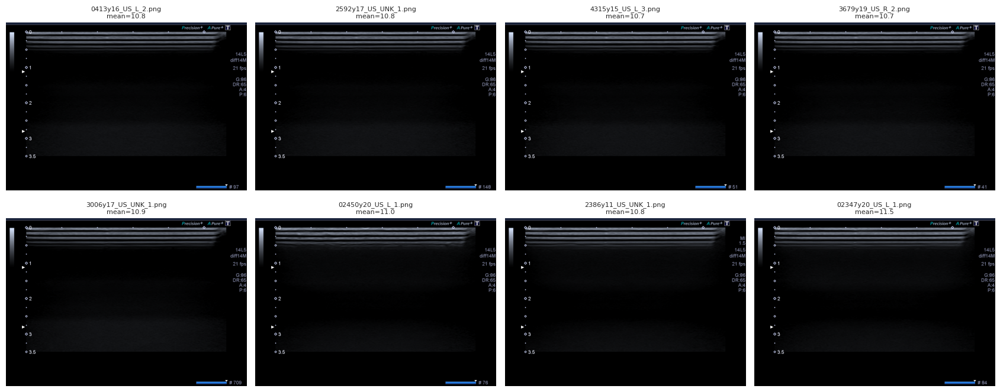


5 images les plus noires :
          filename  black_frac  mean_gray Pathology Label
1386y12_US_L_2.png       0.957      3.251       Malignant
3454y15_US_R_7.png       0.811     11.279          Benign
3454y15_US_R_3.png       0.803     10.688          Benign
4261y16_US_L_1.png       0.798     11.845          Benign
3454y15_US_R_9.png       0.790     12.057          Benign

=== Unilatéraux : basse résolution x Pathology ===
Pathology Label  Benign  Malignant  Normal
small_res                                 
False                85         49      33
True                  4         14       0

=== Mise en page courte (541 px) x Pathology (tous étiquetés) ===
Pathology Label  Benign  Malignant  Normal
us_short_layout                           
False               200         44      50
True                 14         19       0

=== Idem dans le sous-ensemble unilatéral ===
Pathology Label  Benign  Malignant  Normal
us_short_layout                           
False                84     

In [28]:
# ---------- 1) paires de groupes (3 patients atypiques) : mêmes vues, corrélation vs baseline ----------
def zn(v):
    v = v - v.mean(); return v / (np.linalg.norm(v) + 1e-6)

rows = []
for gid, g in dm.groupby("group_id"):
    if g["patient"].nunique() < 2: continue
    for (_, a), (_, b) in itertools.combinations(g.iterrows(), 2):
        if a["patient"] != b["patient"] and a["side"] == b["side"] and a["view_final"] == b["view_final"]:
            rows.append(dict(group=gid, a=a["filename"], b=b["filename"],
                             corr=round(abs(float(zn(Tm[a["row"]]) @ zn(Tm[b["row"]]))), 4)))
print("=== Paires d'un même groupe ===")
display(pd.DataFrame(rows))

pat, sv, pol, rw = dm.patient.values, (dm.side + dm.view_final).values, dm.polarity.values, dm.row.values
rng = np.random.default_rng(SEED); base = []
for i, j in rng.integers(0, len(dm), size=(6000, 2)):
    if pat[i] != pat[j] and sv[i] == sv[j] and pol[i] == pol[j]:
        base.append(abs(float(zn(Tm[rw[i]]) @ zn(Tm[rw[j]]))))
print("Baseline (paires aléatoires, mêmes vue/côté/polarité) : médiane =", round(np.median(base), 3),
      "| p95 =", round(np.percentile(base, 95), 3), "| n =", len(base))

# ---------- 2) échographies suspectes : voir les images ----------
names = ["0413y16_US_L_2.png", "2592y17_US_UNK_1.png", "4315y15_US_L_3.png", "3679y19_US_R_2.png",
         "3006y17_US_UNK_1.png", "02450y20_US_L_1.png", "2386y11_US_UNK_1.png", "02347y20_US_L_1.png"]
ds = du.set_index("filename").loc[names]
print(ds[["mean_gray", "black_frac", "bbox_h", "Pathology Label"]].round(3).to_string())

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (fn, r) in zip(axes.ravel(), ds.iterrows()):
    with Image.open(r["path"]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(f"{fn}\nmean={r['mean_gray']:.1f}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()
print("\n5 images les plus noires :")
print(du.nlargest(5, "black_frac")[["filename", "black_frac", "mean_gray", "Pathology Label"]].round(3).to_string(index=False))

# ---------- 3) raccourcis dans le sous-ensemble unilatéral + mise en page échographie ----------
lab = pm[pm["labeled"]]
u = lab[~lab["bilateral"]]
print("\n=== Unilatéraux : basse résolution x Pathology ===")
print(pd.crosstab(u["small_res"], u["Pathology Label"]).to_string())

lay = du.assign(short=du["bbox_h"] < 600).groupby("patient")["short"].any().rename("us_short_layout")
t = lab.merge(lay, on="patient", how="left")
print("\n=== Mise en page courte (541 px) x Pathology (tous étiquetés) ===")
print(pd.crosstab(t["us_short_layout"], t["Pathology Label"]).to_string())
print("\n=== Idem dans le sous-ensemble unilatéral ===")
tu = t[~t["bilateral"]]
print(pd.crosstab(tu["us_short_layout"], tu["Pathology Label"]).to_string())

sources d’acquisition + groupes atypiques

In [29]:
# ---------- mise en page courte ajoutée au tableau patient ----------
lay = du.assign(short=du["bbox_h"] < 600).groupby("patient")["short"].any().rename("us_short_layout")
pm = pm.drop(columns=["us_short_layout"], errors="ignore").merge(lay, on="patient", how="left")
pm["us_short_layout"] = pm["us_short_layout"].fillna(False).astype(bool)

lab = pm[pm["labeled"]].copy()
lab["malig"] = lab["Pathology Label"].eq("Malignant")

print("=== Basse résolution mammo x mise en page courte US (étiquetés) ===")
print(pd.crosstab(lab["small_res"], lab["us_short_layout"]).to_string())

lab["source"] = np.select(
    [lab.small_res & lab.us_short_layout, lab.small_res, lab.us_short_layout],
    ["A lowres+short", "B lowres seule", "C short seule"], default="D standard")
print("\n=== Source x bilatéral x Pathology ===")
print(lab.groupby(["bilateral", "source"])["Pathology Label"].value_counts().unstack(fill_value=0).to_string())

u = lab[~lab["bilateral"]]
print("\n=== Test de Fisher dans le sous-ensemble unilatéral ===")
for c in ["small_res", "us_short_layout"]:
    print(f"{c:<18} p = {fisher_exact(pd.crosstab(u[c], u['malig']).values)[1]:.2g}")

# ---------- groupes atypiques : mêmes seins ou seins opposés ? ----------
print("\n=== Vues par patient dans les 3 groupes atypiques ===")
for g in ["1566", "3128", "4412"]:
    sub = dm[dm.group_id == g]
    print(g, sub.groupby("patient").apply(lambda d: ",".join(sorted(set(d.side + "_" + d.view_final)))).to_dict())

pm.to_csv(WORK_DIR / "patient_master.csv", index=False)

=== Basse résolution mammo x mise en page courte US (étiquetés) ===
us_short_layout  False  True 
small_res                    
False              277     22
True                17     11

=== Source x bilatéral x Pathology ===
Pathology Label           Benign  Malignant  Normal
bilateral source                                   
False     A lowres+short       2          9       0
          B lowres seule       2          5       0
          C short seule        3         10       0
          D standard          82         39      33
True      B lowres seule       7          0       3
          C short seule        9          0       0
          D standard         109          0      14

=== Test de Fisher dans le sous-ensemble unilatéral ===
small_res          p = 8.6e-05
us_short_layout    p = 1.6e-06

=== Vues par patient dans les 3 groupes atypiques ===
1566 {'01566y21': 'R_CC,R_MLO', '01566y211': 'L_CC,L_MLO'}
3128 {'03128y21': 'L_CC,L_MLO', '03128y211': 'R_CC,R_MLO'}
4412 {'04412

### Surimpressions colorées dans les échographies (marqueurs, calipers)

In [30]:
CHROMA_T, MAX_COMP = 70, 300     # chroma = max(R,G,B) - min(R,G,B) ; composantes <= 300 px

def find_overlay(roi):
    chroma = roi.max(axis=2).astype(np.int16) - roi.min(axis=2).astype(np.int16)
    raw = (chroma > CHROMA_T).astype(np.uint8)
    n, lab_, stats, _ = cv2.connectedComponentsWithStats(raw, connectivity=8)
    small = np.where(stats[:, cv2.CC_STAT_AREA] <= MAX_COMP)[0]
    small = small[small > 0]                       # 0 = fond
    keep = np.isin(lab_, small).astype(np.uint8)
    return int(raw.sum()), keep

def overlay_stats(path, box=None):
    box = box or US_BOX
    with Image.open(path) as im:
        rgb = np.asarray(im.convert("RGB"))
    x0, y0, x1, y1 = box
    n_raw, ov = find_overlay(rgb[y0:y1, x0:x1])
    n_ov = int(ov.sum())
    return dict(path=path, n_overlay_px=n_ov, n_colored_big=n_raw - n_ov)

with ThreadPoolExecutor(max_workers=4) as ex:
    infos = list(tqdm(ex.map(lambda p: overlay_stats(p), du["path"]), total=len(du)))
ovdf = pd.DataFrame(infos)[["path", "n_overlay_px", "n_colored_big"]]
du = du.drop(columns=["n_ov", "has_ov", "n_overlay_px", "n_colored_big"], errors="ignore").merge(ovdf, on="path")
du["has_ov"] = du["n_overlay_px"] > 0

print("Images avec marqueurs détectés :", du["has_ov"].mean().round(3))
print(du.groupby("Pathology Label")["has_ov"].mean().round(3).to_string())
print("\nPixels de marqueurs (quantiles) :", du["n_overlay_px"].quantile([.5, .9, .99]).round(0).to_dict())
print("Images avec grande zone teintée laissée intacte :", (du["n_colored_big"] > 0).sum())

  0%|          | 0/1042 [00:00<?, ?it/s]

Images avec marqueurs détectés : 0.592
Pathology Label
Benign       0.638
Malignant    0.582
Normal       0.362

Pixels de marqueurs (quantiles) : {0.5: 8.0, 0.9: 289.0, 0.99: 621.0}
Images avec grande zone teintée laissée intacte : 26


la source correspond-elle à la période d’examen ?

In [31]:
lab["year"] = lab["patient"].str.extract(r"y(\d{2})")[0].astype(int)     # suffixe yXX : signification NON confirmée
lab["period"] = pd.cut(lab["year"], [0, 12, 16, 19, 23], labels=["<=12", "13-16", "17-19", "20-23"])
print("=== Période x source ===")
print(pd.crosstab(lab["period"], lab["source"]).to_string())
print("\n=== Période x Pathology ===")
print(pd.crosstab(lab["period"], lab["Pathology Label"]).to_string())
print("\n=== Période x bilatéral ===")
print(pd.crosstab(lab["period"], lab["bilateral"]).to_string())

=== Période x source ===
source  A lowres+short  B lowres seule  C short seule  D standard
period                                                           
<=12                 1               2              2          30
13-16                1               2              5          78
17-19                0               0              6         107
20-23                9              13              9          62

=== Période x Pathology ===
Pathology Label  Benign  Malignant  Normal
period                                    
<=12                 20          5      10
13-16                63         10      13
17-19                88          7      18
20-23                43         41       9

=== Période x bilatéral ===
bilateral  False  True 
period                 
<=12          24     11
13-16         54     32
17-19         54     59
20-23         53     40


# Étape 5B (fin 2) : marqueurs par seuil, icône T, images vides, année d'examen

=== Toutes les échographies étiquetées ===
                 ov>=1  ov>=30  ov>=100  ov>=250
Pathology Label                                 
Benign           0.638   0.480    0.473    0.287
Malignant        0.582   0.524    0.487    0.342
Normal           0.362   0.233    0.224    0.103

=== Patients unilatéraux seulement ===
                 ov>=1  ov>=30  ov>=100  ov>=250
Pathology Label                                 
Benign           0.558   0.412    0.399    0.227
Malignant        0.582   0.524    0.487    0.342
Normal           0.250   0.158    0.145    0.039

=== Niveau patient : au moins une image avec >= 100 px de marqueurs ===
any_marker       False  True 
Pathology Label              
Benign            0.30   0.70
Malignant         0.17   0.83
Normal            0.74   0.26


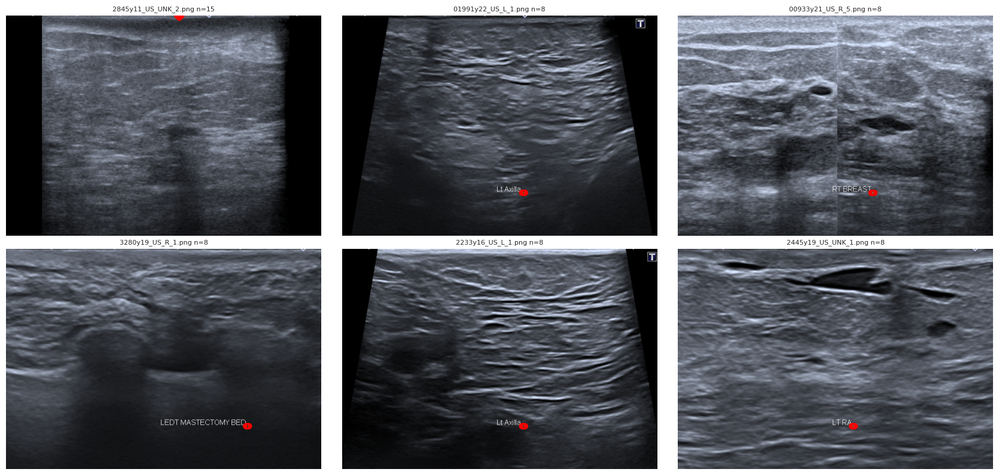

In [32]:
d = du.dropna(subset=["Pathology Label"]).copy()
for t in [1, 30, 100, 250]:
    d[f"ov>={t}"] = d["n_overlay_px"] >= t
cols = [c for c in d.columns if c.startswith("ov>=")]

print("=== Toutes les échographies étiquetées ===")
print(d.groupby("Pathology Label")[cols].mean().round(3).to_string())
print("\n=== Patients unilatéraux seulement ===")
print(d[d["bilateral"].eq(False)].groupby("Pathology Label")[cols].mean().round(3).to_string())

pp = d.groupby(["patient", "Pathology Label"])["n_overlay_px"].max().ge(100).rename("any_marker").reset_index()
print("\n=== Niveau patient : au moins une image avec >= 100 px de marqueurs ===")
print(pd.crosstab(pp["Pathology Label"], pp["any_marker"], normalize="index").round(2).to_string())

# que détecte-t-on quand n_overlay_px est petit (3 à 15 px) ? (cercles rouges = pixels détectés)
small = du[(du.n_overlay_px >= 3) & (du.n_overlay_px <= 15)].sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (_, r) in zip(axes.ravel(), small.iterrows()):
    with Image.open(r["path"]) as im:
        roi = np.asarray(im.convert("RGB"))[US_BOX[1]:US_BOX[3], US_BOX[0]:US_BOX[2]].copy()
    _, ov = find_overlay(roi)
    ys, xs = np.where(ov > 0)
    ax.imshow(roi); ax.scatter(xs, ys, s=40, facecolors="none", edgecolors="red")
    ax.set_title(f"{r['filename']} n={r['n_overlay_px']}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

### Sous-groupe suffixe 20-23 : source standard contre non standard

In [33]:
# sous-groupe période 20-23 unilatéral : toutes les sources, avec D
sub = lab[(lab["period"] == "20-23") & (~lab["bilateral"])].copy()
sub["src_group"] = np.where(sub["source"] == "D standard", "standard", "non-standard")
print("\n", pd.crosstab(sub["source"], sub["Pathology Label"]).to_string())
print("\n", pd.crosstab(sub["src_group"], sub["Pathology Label"]).to_string())
tt = pd.crosstab(sub["src_group"], sub["Pathology Label"].eq("Malignant"))
print("Fisher (non-standard vs standard, Malignant) p =", f"{fisher_exact(tt.values)[1]:.2g}")


 Pathology Label  Benign  Malignant  Normal
source                                    
A lowres+short        0          9       0
B lowres seule        1          4       0
C short seule         0          9       0
D standard            7         19       4

 Pathology Label  Benign  Malignant  Normal
src_group                                 
non-standard          1         22       0
standard              7         19       4
Fisher (non-standard vs standard, Malignant) p = 0.0071


formats de date des PDF (positions numériques seulement, pas de dates)

In [34]:
DATE_RE = re.compile(r"date\s*:?\s*(\d{1,2})\s*[/\-.]\s*([A-Za-z]{3}|\d{1,2})\s*[/\-.]\s*(\d{4}|\d{2})(?!\d)", re.I)
rows = []
for _, r in pdf_df.iterrows():
    mt = DATE_RE.search(r["text"])
    if not mt:
        rows.append(dict(patient=r["patient"], kind="aucune")); continue
    a, b, c = mt.groups()
    kind = "4 chiffres" if len(c) == 4 else ("2 chiffres + mois en lettres" if b.isalpha() else "2 chiffres numérique")
    rows.append(dict(patient=r["patient"], kind=kind, a=int(a), b=np.nan if b.isalpha() else int(b), c=int(c)))
dd_ = pd.DataFrame(rows)
print(dd_["kind"].value_counts().to_string())
print("\nPlages par position (a, b, c) :")
print(dd_.groupby("kind")[["a", "b", "c"]].agg(["min", "max"]).to_string())

sure = dd_[dd_.kind.isin(["4 chiffres", "2 chiffres + mois en lettres"])].copy()
sure["year"] = np.where(sure["c"] < 100, 2000 + sure["c"], sure["c"])
print("\nAnnées (formats non ambigus) :")
print(sure["year"].value_counts().sort_index().to_string())

kind
4 chiffres                      192
2 chiffres numérique             64
2 chiffres + mois en lettres     60
aucune                            5

Plages par position (a, b, c) :
                                a          b             c        
                              min   max  min   max     min     max
kind                                                              
2 chiffres + mois en lettres  2.0  31.0  NaN   NaN    21.0    23.0
2 chiffres numérique          2.0  31.0  3.0  11.0    20.0    23.0
4 chiffres                    1.0  31.0  1.0  30.0  2021.0  2023.0
aucune                        NaN   NaN  NaN   NaN     NaN     NaN

Années (formats non ambigus) :
year
2021.0    216
2022.0     20
2023.0     16


années d’examen et ancienneté du dossier

In [35]:
def year_from(text):
    mt = DATE_RE.search(text)
    if not mt:
        return np.nan
    y = int(mt.group(3))
    return 2000 + y if y < 100 else y

pdf_df["study_year"] = pdf_df["text"].apply(year_from)
print("Années lues :", int(pdf_df["study_year"].notna().sum()), "/", len(pdf_df))
print(pdf_df["study_year"].value_counts().sort_index().to_string())

lab = lab.drop(columns=["study_year"], errors="ignore").merge(pdf_df[["patient", "study_year"]], on="patient", how="left")
l2 = lab[lab.study_year.notna()].copy()
l2["exam"] = pd.cut(l2["study_year"], [2019, 2020, 2021, 2023], labels=["2020", "2021", "2022-23"])
print("\nPatients étiquetés avec année :", len(l2), "/", len(lab))

print("\n=== Année d'examen x source ===");      print(pd.crosstab(l2["exam"], l2["source"]).to_string())
print("\n=== Année d'examen x Pathology ===");   print(pd.crosstab(l2["exam"], l2["Pathology Label"]).to_string())

s21 = l2[(l2["exam"] == "2021") & (~l2["bilateral"])]
print("\n=== 2021 seulement, unilatéraux : source x Pathology ===")
print(pd.crosstab(s21["source"], s21["Pathology Label"]).to_string())

# le suffixe est-il l'année d'ouverture du dossier ? (écart = année d'examen - année du suffixe)
l2["gap"] = l2["study_year"] - (2000 + l2["year"])
l2["file_age"] = pd.cut(l2["gap"], [-1, 1, 5, 20], labels=["0-1 an", "2-5 ans", ">5 ans"])
print("\n=== Ancienneté du dossier x Pathology ===");  print(pd.crosstab(l2["file_age"], l2["Pathology Label"]).to_string())
print("\n=== Ancienneté du dossier x bilatéral ===");  print(pd.crosstab(l2["file_age"], l2["bilateral"]).to_string())

# le modèle de rapport (format de date) est-il lié au label ?
l2 = l2.merge(dd_[["patient", "kind"]].rename(columns={"kind": "date_format"}), on="patient", how="left")
print("\n=== Format de date du rapport x Pathology ===")
print(pd.crosstab(l2["date_format"], l2["Pathology Label"]).to_string())

lab.to_csv(WORK_DIR / "labeled_patients_with_year.csv", index=False)

Années lues : 316 / 321
study_year
2020.0      1
2021.0    275
2022.0     20
2023.0     20

Patients étiquetés avec année : 312 / 327

=== Année d'examen x source ===
source   A lowres+short  B lowres seule  C short seule  D standard
exam                                                              
2020                  0               0              0           1
2021                  1               0             11         259
2022-23               4              14             10          12

=== Année d'examen x Pathology ===
Pathology Label  Benign  Malignant  Normal
exam                                      
2020                  1          0       0
2021                191         33      47
2022-23              19         18       3

=== 2021 seulement, unilatéraux : source x Pathology ===
Pathology Label  Benign  Malignant  Normal
source                                    
A lowres+short        1          0       0
C short seule         2          2       0
D standard       

**Conclusion 5C.** La source (basse résolution, mise en page courte) reste liée au label chez les unilatéraux (p = 8,6e-5 et 1,6e-6). Les marqueurs échographiques séparent Normal (26 %) de Benign (70 %) et Malignant (83 %). 65 % des Malignant ont un suffixe 20-23 ; les examens de 2022-23 sont à 45 % de Malignant contre 12 % en 2021. Le suffixe `yXX` semble être l'ancienneté du dossier (hypothèse non confirmée) : il est supprimé par le pseudo-ID. **Aucune de ces variables ne doit servir de feature.**

# Étape 5D : traitement des images

### Mammographies : traitement des 951 images et sauvegarde du log

In [36]:
OUT_M, OUT_U = PROC / "mammo", PROC / "us"

def process_mammo(row):
    info = dict(path=row["path"], modality="Mammogram", patient=row["patient"],
                filename=row["filename"], view_final=row["view_final"], error="")
    try:
        out, i2 = prep_mammo(row)
        dst = OUT_M / f"{row['patient']}__{Path(row['filename']).stem}.png"
        cv2.imwrite(str(dst), out)
        info.update(out_path=str(dst), polarity=i2["polarity"], flipped=i2["flipped"],
                    trim=i2.get("trim", ""), area=i2["area"], bbox_frac=i2["bbox_frac"],
                    failed=i2["failed"], touch_left=i2["touch_left"])
    except Exception as e:
        info["error"] = repr(e)[:120]
    return info

with ThreadPoolExecutor(max_workers=4) as ex:
    res_m = list(tqdm(ex.map(process_mammo, [r for _, r in dm.iterrows()]), total=len(dm), desc="mammo"))

log = pd.DataFrame(res_m)
log = log.merge(pm[["patient", "group_id", "Pathology Label", "BI-RADS Label", "bilateral",
                    "small_res", "us_short_layout"]], on="patient", how="left")
log.to_csv(WORK_DIR / "preprocess_log.csv", index=False)
print("Log mammographies sauvegardé :", len(log), "lignes | erreurs :", int((log.error != "").sum()))

mammo:   0%|          | 0/951 [00:00<?, ?it/s]

Log mammographies sauvegardé : 951 lignes | erreurs : 0


### Fonctions de correction de bordure (marge blanche puis bordure noire)

In [37]:
def find_dm(pid, side, view):
    d = dm[(dm.patient == pid) & (dm.side == side) & (dm.view_final == view)]
    return d.iloc[0] if len(d) else None

def load_gray(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("L"))

def margin_then_border(a, max_frac=0.25, white=250, dark=80, tol=6):
    """Pour chaque côté : (marge blanche, bordure noire qui suit), en pixels."""
    H, W = a.shape
    cr, cc = a[int(H*.3):int(H*.7)], a[:, int(W*.3):int(W*.7)]
    P = {"l": cr.mean(axis=0), "r": cr.mean(axis=0)[::-1], "t": cc.mean(axis=1), "b": cc.mean(axis=1)[::-1]}
    def run(p, cond):
        n = miss = 0
        for i, v in enumerate(p):
            if cond(v): n, miss = i + 1, 0
            else:
                miss += 1
                if miss > tol: break
        return n
    out = {}
    for k, p in P.items():
        p = p[:int((W if k in "lr" else H) * max_frac)]
        w = run(p, lambda v: v > white)
        out[k] = (w, run(p[w:], lambda v: v < dark))
    return out

### Mammographies négatives : contrôle des bordures et correction forcée des cas douteux

        n  bordure_attendue_ok  bordure_ailleurs
side                                            
L     459                  457                 0
R     416                  413                 0

Médianes (marge incluse) : {'L': {'t_l': 88, 't_t': 92}, 'R': {'t_r': 87, 't_b': 91}}
     t_l      t_r     t_t     t_b    
     min  max min max min max min max
side                                 
L     81  102   0   0  90  93   0   0
R      0    0  80  93   0   0  89  93

Négatifs à bordure douteuse : 5
            filename side      trim     area  bbox_frac
02300y21_R_MLO_1.png    R  0,87,0,0 0.368174   0.477540
 2599y11_R_MLO_1.png    R  0,85,0,8 0.499524   0.604733
 2786y19_R_MLO_1.png    R 0,90,0,29 0.380642   0.432462
   4105y18_L_MLO.png    L   0,0,0,0 0.251434   0.309020
 4261y16_L_MLO_1.png    L   0,0,8,0 0.229208   1.000000

Avant / après :
            filename      trim  area  bbox_frac trim_après  area_après  bbox_frac_après
02300y21_R_MLO_1.png  0,87,0,0  0.37       0.48  0,87

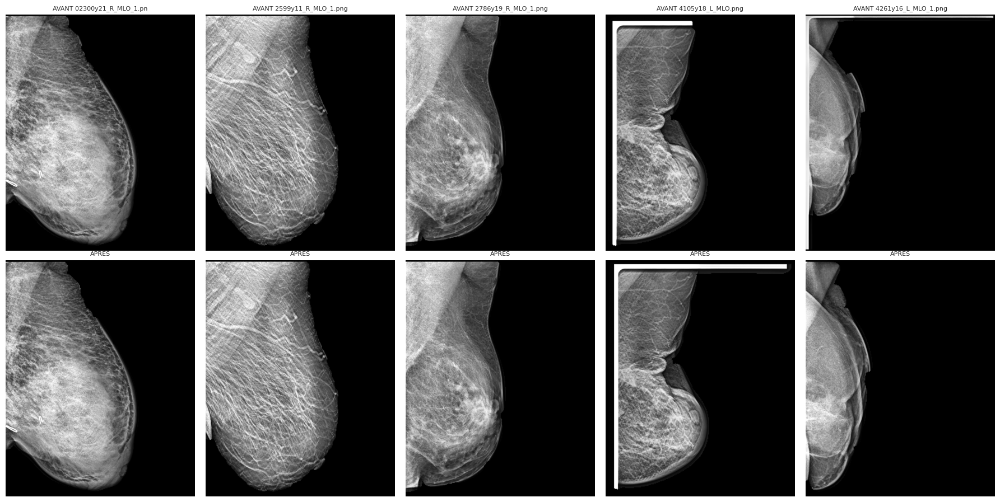


mask_full : 8 | area < 0.10 : 5 | échecs : 0


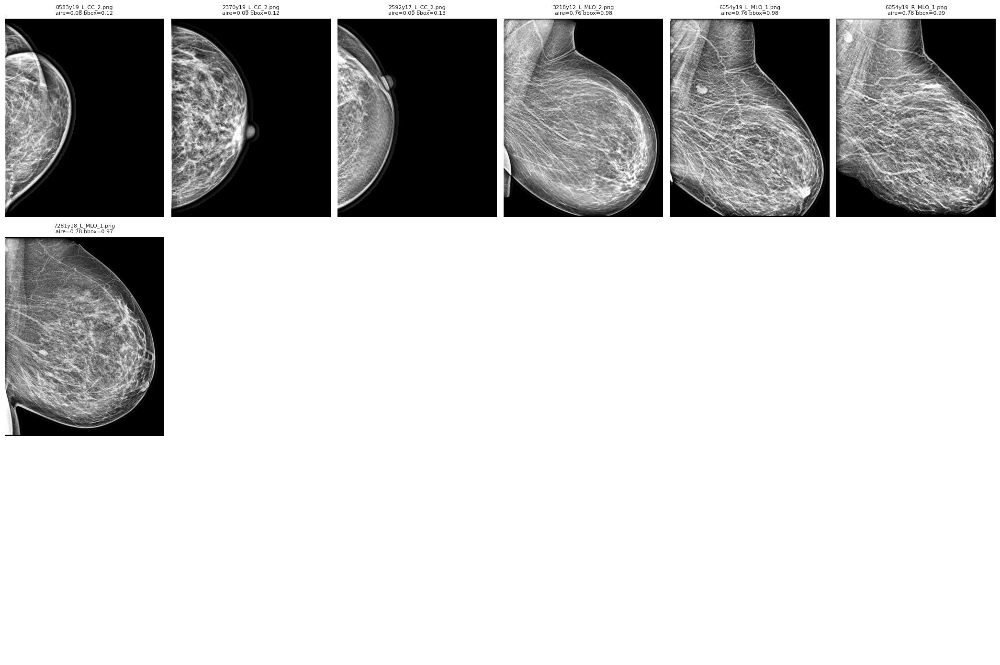

In [38]:
m = log[log.modality == "Mammogram"].copy()
neg = m[m.polarity == "negative"].copy()
tr = neg["trim"].fillna("").apply(lambda s: [int(x) for x in s.split(",")] if s else [0, 0, 0, 0])
neg[["t_l", "t_r", "t_t", "t_b"]] = pd.DataFrame(tr.tolist(), index=neg.index)
neg["side"] = np.where(neg["flipped"].eq(True), "R", "L")

EXP = {"L": ["t_l", "t_t"], "R": ["t_r", "t_b"]}      # côtés où la bordure est attendue (marge de 6 px incluse)
OTH = {"L": ["t_r", "t_b"], "R": ["t_l", "t_t"]}
neg["exp_ok"] = neg.apply(lambda r: all(60 <= r[c] <= 110 for c in EXP[r["side"]]), axis=1)
neg["other_nonzero"] = neg.apply(lambda r: any(r[c] > 0 for c in OTH[r["side"]]), axis=1)
print(neg.groupby("side").agg(n=("exp_ok", "size"), bordure_attendue_ok=("exp_ok", "sum"),
                              bordure_ailleurs=("other_nonzero", "sum")).to_string())

ok = neg[neg.exp_ok]
med = {s: {c: int(ok.loc[ok.side == s, c].median()) for c in EXP[s]} for s in ["L", "R"]}
print("\nMédianes (marge incluse) :", med)
print(ok.groupby("side")[["t_l", "t_r", "t_t", "t_b"]].agg(["min", "max"]).to_string())

flag = neg[~neg.exp_ok].copy()
print("\nNégatifs à bordure douteuse :", len(flag))
print(flag[["filename", "side", "trim", "area", "bbox_frac"]].to_string(index=False))

# --- correction : bordure forcée à la médiane de son côté (séquentiel, donc sans risque avec les threads) ---
_FORCE = None

def forced_trim(side):                      # (gauche, droite, haut, bas), sans la marge que prep_mammo rajoute
    v = med[side]
    return (v["t_l"] - 6, 0, v["t_t"] - 6, 0) if side == "L" else (0, v["t_r"] - 6, 0, v["t_b"] - 6)

before = {}
for _, r in flag.iterrows():
    before[r["path"]] = cv2.imread(r["out_path"], 0)
    row = dm[dm["path"] == r["path"]].iloc[0]
    _FORCE = forced_trim(r["side"])
    new = process_mammo(row)
    _FORCE = None
    for k in ["trim", "area", "bbox_frac", "failed", "touch_left", "out_path", "error"]:
        log.loc[log["path"] == r["path"], k] = new[k]

cmp = flag.set_index("path")[["filename", "trim", "area", "bbox_frac"]].join(
        log.set_index("path")[["trim", "area", "bbox_frac"]], rsuffix="_après")
print("\nAvant / après :")
print(cmp.round(2).to_string(index=False))

show = flag.head(6)
if len(show):
    fig, axes = plt.subplots(2, len(show), figsize=(3.6 * len(show), 9), squeeze=False)
    for k, (_, r) in enumerate(show.iterrows()):
        axes[0, k].imshow(before[r["path"]], cmap="gray", vmin=0, vmax=255); axes[0, k].set_title(f"AVANT {r['filename'][:19]}", fontsize=8)
        axes[1, k].imshow(cv2.imread(r["out_path"], 0), cmap="gray", vmin=0, vmax=255); axes[1, k].set_title("APRÈS", fontsize=8)
        axes[0, k].axis("off"); axes[1, k].axis("off")
    plt.tight_layout(); plt.show()

# --- les sorties suspectes restantes (mask_full ou petit sein), hors cas déjà validés ---
m = log[log.modality == "Mammogram"].copy()
m["mask_full"] = m["bbox_frac"] > 0.95
print("\nmask_full :", int(m.mask_full.sum()), "| area < 0.10 :", int((m.area < 0.10).sum()), "| échecs :", int(m.failed.sum()))
seen = ("02095y21", "00338y23", "05186y20_R_MLO", "0812y15_R_MLO")
chk = m[(m.mask_full | (m.area < 0.10)) & ~m.filename.str.startswith(seen)].head(18)
fig, axes = plt.subplots(3, 6, figsize=(21, 14))
for ax in axes.ravel(): ax.axis("off")
for ax, (_, r) in zip(axes.ravel(), chk.iterrows()):
    ax.imshow(cv2.imread(r["out_path"], 0), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{r['filename'][:20]}\naire={r['area']:.2f} bbox={r['bbox_frac']:.2f}", fontsize=8)
plt.tight_layout(); plt.show()

log.to_csv(WORK_DIR / "preprocess_log.csv", index=False)

### Correction de `4105y18_L_MLO` (marge blanche avant la bordure noire)

Trims détectés (l, r, t, b), marge blanche + bordure : [948, 0, 209, 0] | détail : {'l': (868, 80), 'r': (0, 0), 't': (124, 85), 'b': (0, 0)}
avant : aire=0.27 bbox=0.57 | après : aire=0.27 bbox=0.34 | correction acceptée : True


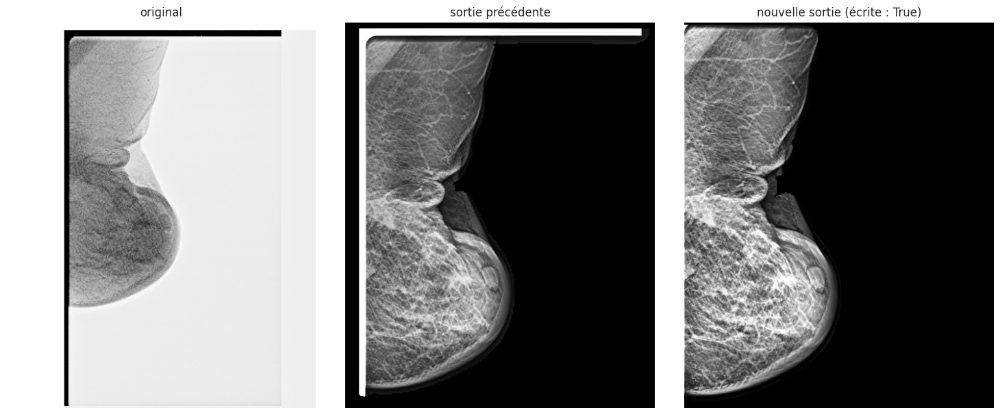

In [39]:
# ---- correction de 4105y18_L_MLO seulement (écrite si le résultat est meilleur) ----
_FORCE = None

row = find_dm("4105y18", "L", "MLO")
a = load_gray(row["path"])
tr = margin_then_border(a)
tot = [sum(tr[k]) for k in "lrtb"]
print("Trims détectés (l, r, t, b), marge blanche + bordure :", tot, "| détail :", tr)

out_path = log.loc[log["path"] == row["path"], "out_path"].iloc[0]
old = cv2.imread(out_path, 0)
_FORCE = tuple(max(v - 6, 0) if v > 0 else 0 for v in tot)     # prep_mammo rajoute 6 px de marge
new_out, ni = prep_mammo(row)
_FORCE = None
good = (not ni["failed"]) and ni["touch_left"] and ni["bbox_frac"] < 0.5
print(f"avant : aire={float(log.loc[log['path']==row['path'],'area'].iloc[0]):.2f} "
      f"bbox={float(log.loc[log['path']==row['path'],'bbox_frac'].iloc[0]):.2f} | "
      f"après : aire={ni['area']:.2f} bbox={ni['bbox_frac']:.2f} | correction acceptée : {good}")
if good:
    cv2.imwrite(out_path, new_out)
    for k in ["area", "bbox_frac", "failed", "touch_left"]:
        log.loc[log["path"] == row["path"], k] = ni[k]
    log.loc[log["path"] == row["path"], "trim"] = ni.get("trim", "")
    log.loc[log["path"] == row["path"], "border_fix"] = "margin_then_dark"
    log.to_csv(WORK_DIR / "preprocess_log.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(15, 6))
ax[0].imshow(a[::16, ::16], cmap="gray", vmin=0, vmax=255); ax[0].set_title("original")
ax[1].imshow(old, cmap="gray", vmin=0, vmax=255); ax[1].set_title("sortie précédente")
ax[2].imshow(new_out, cmap="gray", vmin=0, vmax=255); ax[2].set_title(f"nouvelle sortie (écrite : {good})")
for x in ax: x.axis("off")
plt.tight_layout(); plt.show()

### Échographies : badge « T » (icône de l'appareil), détection par modèle et pleine largeur

2215y19_US_UNK_2.png -> centre du T (x, y) : (792, 54)
00263y23_US_L_10.png -> centre du T (x, y) : (818, 54)
3216y14_US_R_3.png -> centre du T (x, y) : (770, 54)
Corrélation minimale entre les 3 fenêtres : 0.995


  0%|          | 0/1042 [00:00<?, ?it/s]

t_score
(-1.0, 0.3]      0
(0.3, 0.5]     256
(0.5, 0.6]      35
(0.6, 0.7]       0
(0.7, 0.8]       0
(0.8, 0.9]       0
(0.9, 1.01]    751
Badge T détecté : 0.721 (751 / 1042)

Hauteur du centre (y) : {54: 411, 52: 340}
Position horizontale (x) :
t_cx
(0, 100]         0
(100, 200]       0
(200, 300]       0
(300, 400]       0
(400, 500]       0
(500, 600]       0
(600, 700]       7
(700, 800]     201
(800, 900]     543
(900, 1000]      0
Badges qui chevauchent la zone recadrée : 502 / 751


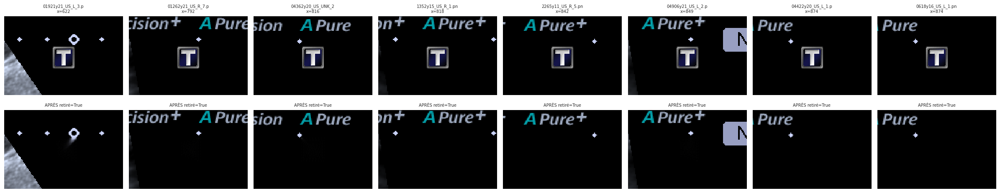


Badge x mise en page courte :
has_t   False  True 
bbox_h              
False    0.26   0.74
True     0.42   0.58

Badge x Pathology (unilatéraux, % des images de la classe) :
Pathology Label  Benign  Malignant  Normal
has_t                                     
False              0.28       0.34    0.18
True               0.72       0.66    0.82


In [40]:
def load_rgb(p):
    with Image.open(p) as im:
        return np.asarray(im.convert("RGB"))

def t_center(rgb):
    """Centre de la lettre T (ancien détecteur par luminosité : il fonctionnait sur la lettre)."""
    x0, y0, x1, y1 = US_BOX
    roi = rgb[y0:y1, x0:x1]
    h, w = roi.shape[:2]
    g = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY)
    xs0, ys1 = int(0.88 * w), int(0.12 * h)
    n, _, st, cen = cv2.connectedComponentsWithStats((g[:ys1, xs0:] > 170).astype(np.uint8), connectivity=8)
    ok = [i for i in range(1, n) if 15 <= st[i, 4] <= 600 and st[i, 2] <= 40 and st[i, 3] <= 40]
    if not ok:
        return None
    i = max(ok, key=lambda j: st[j, 4])
    return int(round(x0 + xs0 + cen[i][0])), int(round(y0 + cen[i][1]))

# ---------- modèle = médiane de 3 badges connus (fenêtre 31x31 en coordonnées pleine image) ----------
R = 15
KNOWN_T = ["2215y19_US_UNK_2.png", "00263y23_US_L_10.png", "3216y14_US_R_3.png"]
wins = []
for fn in KNOWN_T:
    rgb = load_rgb(du.loc[du.filename == fn, "path"].iloc[0])
    c = t_center(rgb)
    print(fn, "-> centre du T (x, y) :", c)
    assert c is not None, f"lettre T introuvable dans {fn}"
    cx, cy = c
    wins.append(cv2.cvtColor(rgb[cy - R:cy + R + 1, cx - R:cx + R + 1], cv2.COLOR_RGB2GRAY))
TPL = np.median(np.stack(wins), axis=0).astype(np.uint8)
print("Corrélation minimale entre les 3 fenêtres :", np.corrcoef([w.ravel() for w in wins]).min().round(3))

SX0, SX1, SY0, SY1 = 0, 960, 37, 170          # pleine largeur
TH_BADGE, HALF = 0.80, 12                      # masque (2*HALF+1)^2 = 25x25 px

def badge_find(rgb):
    """Retourne (score, (cx, cy)) : centre du badge T en coordonnées pleine image."""
    g = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)[SY0:SY1, SX0:SX1]
    res = np.nan_to_num(cv2.matchTemplate(g, TPL, cv2.TM_CCOEFF_NORMED))
    _, mx, _, loc = cv2.minMaxLoc(res)
    return float(mx), (SX0 + loc[0] + R, SY0 + loc[1] + R)

def remove_badge(rgb):
    s, (cx, cy) = badge_find(rgb)
    if s < TH_BADGE:
        return rgb, s, False
    m = np.zeros(rgb.shape[:2], np.uint8)
    m[cy - HALF:cy + HALF + 1, cx - HALF:cx + HALF + 1] = 1
    return cv2.inpaint(rgb, m, 3, cv2.INPAINT_TELEA), s, True

def t_info(p):
    s, (cx, cy) = badge_find(load_rgb(p))
    return s, cx, cy

with ThreadPoolExecutor(max_workers=4) as ex:
    ti = list(tqdm(ex.map(t_info, du["path"]), total=len(du)))
du["t_score"], du["t_cx"], du["t_cy"] = [t[0] for t in ti], [t[1] for t in ti], [t[2] for t in ti]
du["has_t"] = du["t_score"] >= TH_BADGE

print(pd.cut(du["t_score"], [-1, .3, .5, .6, .7, .8, .9, 1.01]).value_counts().sort_index().to_string())
print("Badge T détecté :", du["has_t"].mean().round(3), f"({int(du.has_t.sum())} / {len(du)})")
d = du[du.has_t]
print("\nHauteur du centre (y) :", d.t_cy.value_counts().head(5).to_dict())
print("Position horizontale (x) :")
print(pd.cut(d.t_cx, range(0, 1001, 100)).value_counts().sort_index().to_string())
inbox = d.t_cx.between(US_BOX[0] - HALF, US_BOX[2] + HALF) & d.t_cy.between(US_BOX[1] - HALF, US_BOX[3] + HALF)
print("Badges qui chevauchent la zone recadrée :", int(inbox.sum()), "/", len(d))
assert not du.loc[du.filename == "00933y21_US_L_1.png", "has_t"].iloc[0], "faux positif sur 00933y21"

# 8 badges répartis sur toutes les positions x
pick = d.sort_values("t_cx").iloc[np.linspace(0, len(d) - 1, 8).astype(int)]
fig, axes = plt.subplots(2, 8, figsize=(24, 5))
for k, (_, r) in enumerate(pick.iterrows()):
    rgb = load_rgb(r["path"]); fixed, s, ok = remove_badge(rgb)
    y0, y1 = max(r.t_cy - 40, 0), min(r.t_cy + 40, rgb.shape[0])
    x0, x1 = max(r.t_cx - 60, 0), min(r.t_cx + 60, rgb.shape[1])
    axes[0, k].imshow(rgb[y0:y1, x0:x1], interpolation="nearest"); axes[0, k].set_title(f"{r['filename'][:17]}\nx={r.t_cx}", fontsize=7)
    axes[1, k].imshow(fixed[y0:y1, x0:x1], interpolation="nearest"); axes[1, k].set_title(f"APRÈS retiré={ok}", fontsize=7)
    axes[0, k].axis("off"); axes[1, k].axis("off")
plt.tight_layout(); plt.show()

print("\nBadge x mise en page courte :")
print(pd.crosstab(du["bbox_h"] < 600, du["has_t"], normalize="index").round(2).to_string())
lu = du[du["Pathology Label"].notna() & du["bilateral"].eq(False)]
print("\nBadge x Pathology (unilatéraux, % des images de la classe) :")
print(pd.crosstab(lu["has_t"], lu["Pathology Label"], normalize="columns").round(2).to_string())

images vides, mesure calibrée sur des exemples vus

  0%|          | 0/1042 [00:00<?, ?it/s]

Calibration : 17 vides | 10 tissus
             ls75  ls90  lap75  lap90  rel90
max(vides)   1.79  2.21   2.49   3.63   0.12
min(tissus)  1.39  5.22   2.70   5.53   0.12
ratio        0.78  2.37   1.08   1.52   0.96

Mesure retenue : ls90
             filename groupe      ls90
   1386y12_US_L_2.png   vide  0.000000
 2386y11_US_UNK_1.png   vide  1.140000
 1218y15_US_UNK_5.png   vide  1.140000
  02450y20_US_L_1.png   vide  1.190000
   4315y15_US_L_3.png   vide  1.230000
 3006y17_US_UNK_1.png   vide  1.230000
 2592y17_US_UNK_1.png   vide  1.250000
   0413y16_US_L_2.png   vide  1.250000
   3679y19_US_R_2.png   vide  1.270000
   4645y15_US_L_2.png   vide  1.350000
   1291y17_US_R_2.png   vide  1.420000
   3611y17_US_L_2.png   vide  1.430000
  01880y20_US_R_2.png   vide  1.470000
   1504y09_US_L_1.png   vide  1.780000
   3638y16_US_R_1.png   vide  1.970000
 3557y15_US_UNK_1.png   vide  2.150000
  00212y21_US_L_2.png   vide  2.210000
   3679y19_US_R_3.png  tissu  5.220000
   0457y06_US_R_4.png

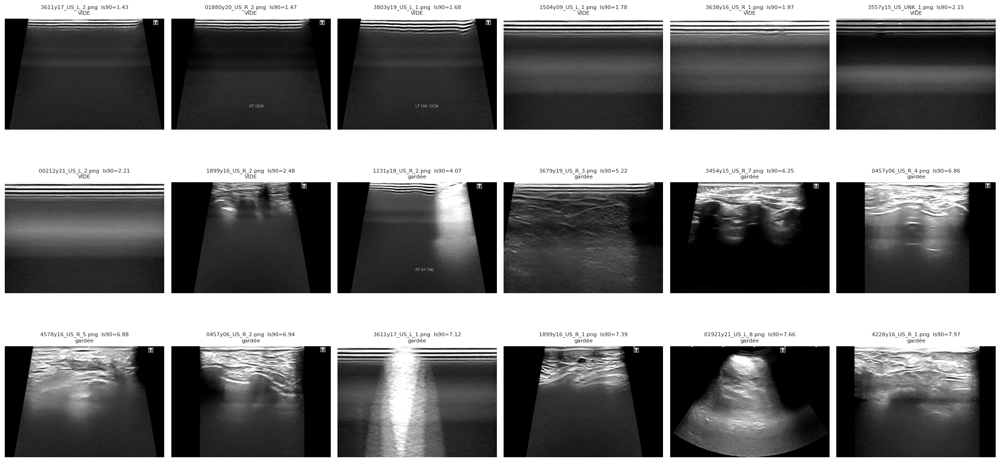

In [41]:
def us_metrics(path):
    with Image.open(path) as im:
        g = np.asarray(im.convert("L"), dtype=np.float32)[US_BOX[1]:US_BOX[3], US_BOX[0]:US_BOX[2]]
    sub = cv2.GaussianBlur(g[int(0.20 * g.shape[0]):], (0, 0), 1.0)      # on saute les bandes du haut
    mu, mu2 = cv2.blur(sub, (15, 15)), cv2.blur(sub * sub, (15, 15))
    ls = np.sqrt(np.maximum(mu2 - mu * mu, 0))                           # écart-type local 15x15
    lap = np.abs(cv2.Laplacian(sub, cv2.CV_32F, ksize=3))
    rel = ls / (mu + 5.0)
    return dict(path=path, ls75=np.percentile(ls, 75), ls90=np.percentile(ls, 90),
                lap75=np.percentile(lap, 75), lap90=np.percentile(lap, 90), rel90=np.percentile(rel, 90))

with ThreadPoolExecutor(max_workers=4) as ex:
    um = pd.DataFrame(list(tqdm(ex.map(us_metrics, du["path"]), total=len(du)))).merge(
            du[["path", "filename", "patient", "Pathology Label"]], on="path")

# exemples que j'ai vus : vides (bandes seules, avec ou sans texte) et tissus (dont tissu seulement en haut)
EMPTY = [f"{s}.png" for s in ["2386y11_US_UNK_1", "02450y20_US_L_1", "4315y15_US_L_3", "3006y17_US_UNK_1",
         "0413y16_US_L_2", "3679y19_US_R_2", "2592y17_US_UNK_1", "1291y17_US_R_2", "1386y12_US_L_2",
         "3611y17_US_L_2", "3638y16_US_R_1", "3557y15_US_UNK_1", "1504y09_US_L_1", "00212y21_US_L_2",
         "01880y20_US_R_2", "4645y15_US_L_2", "1218y15_US_UNK_5"]]
TISSUE = [f"{s}.png" for s in ["1899y16_US_R_1", "0457y06_US_R_4", "0457y06_US_R_2", "4578y16_US_R_5",
          "2265y11_US_R_3", "4639y16_US_R_6", "3679y19_US_R_3", "1016y15_US_R_2",
          "01615y21_US_UNK_3", "3855y19_US_R_4"]]

cand = ["ls75", "ls90", "lap75", "lap90", "rel90"]
E, T = um[um.filename.isin(EMPTY)], um[um.filename.isin(TISSUE)]
print("Calibration :", len(E), "vides |", len(T), "tissus")
cal = pd.DataFrame({c: [E[c].max(), T[c].min(), T[c].min() / E[c].max()] for c in cand},
                   index=["max(vides)", "min(tissus)", "ratio"]).round(2)
print(cal.to_string())
best = cal.loc["ratio"].idxmax()
print("\nMesure retenue :", best)
print(um[um.filename.isin(EMPTY + TISSUE)].assign(groupe=lambda d: np.where(d.filename.isin(EMPTY), "vide", "tissu"))
        .sort_values(best)[["filename", "groupe", best]].round(2).to_string(index=False))
assert cal.loc["ratio", best] > 1.1, "aucune mesure ne sépare proprement vides et tissus : envoie-moi le tableau"

TH_E = float(np.sqrt(E[best].max() * T[best].min()))
um["empty_frame"] = um[best] < TH_E
um["low_content"] = (~um["empty_frame"]) & (um[best] < 1.25 * TH_E)
print(f"\nSeuil = {TH_E:.2f}")
print(um[["empty_frame", "low_content"]].sum().to_string())
print(pd.crosstab(um["empty_frame"], um["Pathology Label"].fillna("NaN")).to_string())
left = um[~um.empty_frame].groupby("patient").size()
print("Patients sans échographie utile :", sorted(set(pm.patient) - set(left.index)))

# les 18 images les plus proches du seuil (9 côté vide, 9 côté gardé)
near = um.assign(d=np.abs(np.log(um[best] / TH_E))).nsmallest(18, "d").sort_values(best)
fig, axes = plt.subplots(3, 6, figsize=(21, 11))
for ax, (_, r) in zip(axes.ravel(), near.iterrows()):
    with Image.open(r["path"]) as im:
        ax.imshow(np.asarray(im.convert("L"))[US_BOX[1]:US_BOX[3], US_BOX[0]:US_BOX[2]], cmap="gray", vmin=0, vmax=120)
    ax.set_title(f"{r['filename'][:20]}  {best}={r[best]:.2f}\n{'VIDE' if r['empty_frame'] else 'gardée'}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

images vides, mesure recalibrée (tissu en haut inclus)

  0%|          | 0/1042 [00:00<?, ?it/s]

Calibration : 18 vides | 13 tissus
             ls90  ls90_14  ls95_14  gx90_14  gx95_14
max(vides)   2.21     2.56     3.65     4.06     5.23
min(tissus)  2.48     3.76     6.83     4.82     7.85
ratio        1.13     1.47     1.87     1.19     1.50

Mesure retenue : ls95_14
             filename groupe   ls95_14
   1386y12_US_L_2.png   vide  0.000000
 1218y15_US_UNK_5.png   vide  1.340000
   3611y17_US_L_2.png   vide  1.930000
  01880y20_US_R_2.png   vide  1.970000
  02450y20_US_L_1.png   vide  2.050000
   0413y16_US_L_2.png   vide  2.170000
   4315y15_US_L_3.png   vide  2.170000
   3679y19_US_R_2.png   vide  2.190000
 2592y17_US_UNK_1.png   vide  2.210000
   4645y15_US_L_2.png   vide  2.230000
 3006y17_US_UNK_1.png   vide  2.230000
 2386y11_US_UNK_1.png   vide  2.740000
   3803y19_US_L_1.png   vide  2.800000
   1291y17_US_R_2.png   vide  2.830000
  00212y21_US_L_2.png   vide  2.940000
   1504y09_US_L_1.png   vide  3.100000
   3638y16_US_R_1.png   vide  3.330000
 3557y15_US_UNK_1.png

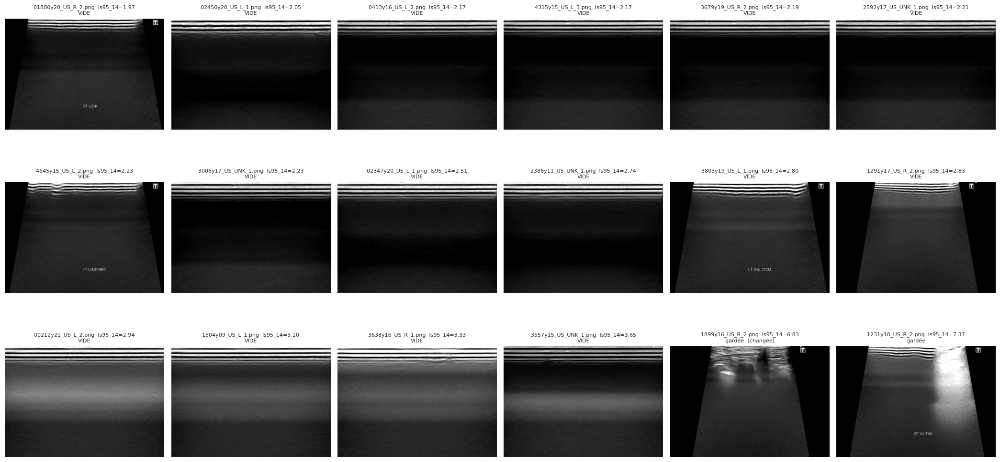

In [42]:
def us_metrics2(path):
    with Image.open(path) as im:
        g = np.asarray(im.convert("L"), dtype=np.float32)[US_BOX[1]:US_BOX[3], US_BOX[0]:US_BOX[2]]
    sub = cv2.GaussianBlur(g[int(0.14 * g.shape[0]):], (0, 0), 1.0)        # on saute seulement les bandes (~14 %)
    mu, mu2 = cv2.blur(sub, (15, 15)), cv2.blur(sub * sub, (15, 15))
    ls = np.sqrt(np.maximum(mu2 - mu * mu, 0))
    gx = np.abs(cv2.Sobel(sub, cv2.CV_32F, 1, 0, ksize=3))                  # insensible aux bandes horizontales
    return dict(path=path, ls90_14=np.percentile(ls, 90), ls95_14=np.percentile(ls, 95),
                gx90_14=np.percentile(gx, 90), gx95_14=np.percentile(gx, 95))

with ThreadPoolExecutor(max_workers=4) as ex:
    um2 = pd.DataFrame(list(tqdm(ex.map(us_metrics2, du["path"]), total=len(du)))).merge(
            um[["path", "filename", "patient", "Pathology Label", "ls90"]], on="path")

EMPTY2 = EMPTY + ["3803y19_US_L_1.png"]
TISSUE2 = TISSUE + ["1899y16_US_R_2.png", "3454y15_US_R_7.png", "4228y16_US_R_1.png"]
cand = ["ls90", "ls90_14", "ls95_14", "gx90_14", "gx95_14"]
E, T = um2[um2.filename.isin(EMPTY2)], um2[um2.filename.isin(TISSUE2)]
print("Calibration :", len(E), "vides |", len(T), "tissus")
cal = pd.DataFrame({c: [E[c].max(), T[c].min(), T[c].min() / max(E[c].max(), 1e-6)] for c in cand},
                   index=["max(vides)", "min(tissus)", "ratio"]).round(2)
print(cal.to_string())
best_name = cal.loc["ratio"].idxmax()
print("\nMesure retenue :", best_name)
print(um2[um2.filename.isin(EMPTY2 + TISSUE2)]
      .assign(groupe=lambda d: np.where(d.filename.isin(EMPTY2), "vide", "tissu"))
      .sort_values(best_name)[["filename", "groupe", best_name]].round(2).to_string(index=False))
assert cal.loc["ratio", best_name] > 1.15, "aucune mesure ne sépare vides et tissus : envoie-moi le tableau"

# politique : on n'exclut que ce qui est sûrement vide ; la zone grise est gardée avec un flag
mult = min(1.15, float(np.sqrt(cal.loc["ratio", best_name])))
TH_E = float(E[best_name].max() * mult)
TH_G = float(np.sqrt(E[best_name].max() * T[best_name].min()))
um2["metric"] = um2[best_name]
um2["empty_frame"] = um2["metric"] < TH_E
um2["low_content"] = (~um2["empty_frame"]) & (um2["metric"] < TH_G)
um2["old_empty"] = um2["ls90"] < 3.39
print(f"\nSeuil exclusion = {TH_E:.2f} | seuil zone grise = {TH_G:.2f}")
print(um2[["empty_frame", "low_content", "old_empty"]].sum().to_string())
print(pd.crosstab(um2["empty_frame"], um2["Pathology Label"].fillna("NaN")).to_string())
print("Décisions changées par rapport à la règle précédente :", int((um2.empty_frame != um2.old_empty).sum()))
left = um2[~um2.empty_frame].groupby("patient").size()
print("Patients sans échographie utile :", sorted(set(pm.patient) - set(left.index)))

sel = pd.concat([um2[um2.empty_frame != um2.old_empty], um2[um2.low_content]]).drop_duplicates("path")
if len(sel) < 12:
    near = um2.assign(d=np.abs(np.log((um2.metric + 1e-3) / TH_E))).nsmallest(18, "d")
    sel = pd.concat([sel, near]).drop_duplicates("path")
sel = sel.head(18).sort_values("metric")
fig, axes = plt.subplots(3, 6, figsize=(21, 11))
for ax in axes.ravel(): ax.axis("off")
for ax, (_, r) in zip(axes.ravel(), sel.iterrows()):
    with Image.open(r["path"]) as im:
        ax.imshow(np.asarray(im.convert("L"))[US_BOX[1]:US_BOX[3], US_BOX[0]:US_BOX[2]], cmap="gray", vmin=0, vmax=120)
    st = "VIDE" if r["empty_frame"] else ("limite" if r["low_content"] else "gardée")
    chg = "  (changée)" if r["empty_frame"] != r["old_empty"] else ""
    ax.set_title(f"{r['filename'][:20]}  {best_name}={r['metric']:.2f}\n{st}{chg}", fontsize=8)
plt.tight_layout(); plt.show()

um, best = um2, "metric"      # lus par la cellule de régénération

### Échographies : traitement final (badge retiré, marqueurs inpaints, images vides exclues)

  0%|          | 0/1042 [00:00<?, ?it/s]

Erreurs : 0 | sauvegardées : 1023 / 1042
Vides exclues : 19 | low_content : 0
Badges retirés : 744 | marqueurs >= 100 px : 469
Fichiers dans processed/us : 1023


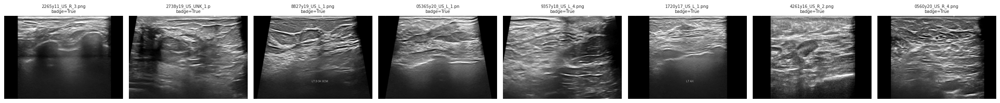

In [43]:
def prep_us(path, box=None):
    box = box or US_BOX
    rgb, s_t, badge = remove_badge(load_rgb(path))        # badge retiré sur l'image entière
    x0, y0, x1, y1 = box
    roi = rgb[y0:y1, x0:x1].copy()
    n_raw, ov = find_overlay(roi)
    n_ov = int(ov.sum())
    if n_ov:
        roi = cv2.inpaint(roi, cv2.dilate(ov, np.ones((3, 3), np.uint8), iterations=1), 3, cv2.INPAINT_TELEA)
    gray = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY)
    lo, hi = np.percentile(gray, 1), np.percentile(gray, 99.5)
    gray = np.clip((gray.astype(np.float32) - lo) * 255.0 / max(hi - lo, 1), 0, 255).astype(np.uint8)
    gray = cv2.resize(gray, US_SIZE, interpolation=cv2.INTER_AREA)
    return gray, dict(path=path, n_overlay_px=n_ov, t_score=s_t, badge=badge, lo=float(lo), hi=float(hi))

for f in OUT_U.glob("*.png"):          # on repart de zéro : certaines images sont désormais exclues
    f.unlink()
um_i = um.set_index("path")

def process_us(row):
    info = dict(path=row["path"], modality="Ultrasound", patient=row["patient"], filename=row["filename"], error="")
    try:
        u_ = um_i.loc[row["path"]]
        info.update(metric=float(u_[best]), empty_frame=bool(u_["empty_frame"]), low_content=bool(u_["low_content"]))
        if info["empty_frame"]:
            return info
        out, i2 = prep_us(row["path"])
        dst = OUT_U / f"{row['patient']}__{Path(row['filename']).stem}.png"
        cv2.imwrite(str(dst), out)
        info.update(out_path=str(dst), n_overlay_px=i2["n_overlay_px"], t_score=i2["t_score"], badge_removed=i2["badge"])
    except Exception as e:
        info["error"] = repr(e)[:120]
    return info

with ThreadPoolExecutor(max_workers=4) as ex:
    res_u = list(tqdm(ex.map(process_us, [r for _, r in du.iterrows()]), total=len(du)))

log_u = pd.DataFrame(res_u).merge(
    pm[["patient", "group_id", "Pathology Label", "BI-RADS Label", "bilateral", "small_res", "us_short_layout"]],
    on="patient", how="left")
log = pd.concat([log[log.modality == "Mammogram"], log_u], ignore_index=True)
log.to_csv(WORK_DIR / "preprocess_log.csv", index=False)

u = log[log.modality == "Ultrasound"]
print("Erreurs :", (u.error != "").sum(), "| sauvegardées :", u.out_path.notna().sum(), "/", len(u))
print("Vides exclues :", int(u.empty_frame.sum()), "| low_content :", int(u.low_content.sum()))
print("Badges retirés :", int(u.badge_removed.eq(True).sum()), "| marqueurs >= 100 px :", int((u.n_overlay_px.fillna(0) >= 100).sum()))
print("Fichiers dans processed/us :", len(list(OUT_U.glob('*.png'))))

wb = u[u.badge_removed.eq(True)]
pick = pd.concat([wb.sample(min(4, len(wb)), random_state=3), u[u.out_path.notna()].sample(4, random_state=3)])
fig, axes = plt.subplots(1, 8, figsize=(24, 3.6))
for ax, (_, r) in zip(axes, pick.iterrows()):
    ax.imshow(cv2.imread(r["out_path"], 0), cmap="gray", vmin=0, vmax=255); ax.axis("off")
    ax.set_title(f"{r['filename'][:18]}\nbadge={r['badge_removed']}", fontsize=7)
plt.tight_layout(); plt.show()

**Conclusion 5D.** Mammographies : 951 sorties, 0 échec de segmentation, 5 bordures douteuses corrigées. Échographies : badge T détecté sur 751 images sur 1042 (72 %) et retiré ; 19 images vides exclues ; 1023 PNG sauvegardés. 4 patients restent sans échographie utile (`has_us = False`).

# Étape 5E : que reste-t-il de la source dans les images prétraitées ?

In [44]:
# Étape 5D : sondes de signature (source, badge T, label) sur les images prétraitées
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

def radial_spec(g, nb=16):
    win = np.outer(np.hanning(g.shape[0]), np.hanning(g.shape[1]))
    P = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2((g - g.mean()) * win))) ** 2)
    yy, xx = np.indices(P.shape)
    r = np.hypot(yy - P.shape[0] // 2, xx - P.shape[1] // 2) / (min(P.shape) / 2)
    return np.array([P[(r >= i / nb) & (r < (i + 1) / nb)].mean() for i in range(nb)])

def extract(args):
    path, kind = args
    g = cv2.imread(path, 0)
    if g is None:
        return None
    g = g.astype(np.float32)
    h, w = g.shape
    if kind == "mammo":
        core = cv2.erode((g > 0).astype(np.uint8), np.ones((15, 15), np.uint8)) > 0
        crop = g[320:960, 0:512]                       # côté paroi thoracique : toujours du tissu
        thumb = cv2.resize(g, (16, 20), interpolation=cv2.INTER_AREA)
    else:
        core = cv2.erode((g > 5).astype(np.uint8), np.ones((9, 9), np.uint8)) > 0
        cy, cx = h // 2, w // 2
        crop = g[cy - 128:cy + 128, cx - 128:cx + 128]
        thumb = cv2.resize(g, (24, 14), interpolation=cv2.INTER_AREA)
    if core.sum() < 100:
        core = np.ones_like(core, bool)
    v = g[core]
    hist = np.histogram(v, bins=32, range=(1, 256))[0] / v.size
    g2 = cv2.resize(g, None, fx=.5, fy=.5, interpolation=cv2.INTER_AREA)
    m2 = cv2.resize(core.astype(np.uint8), (g2.shape[1], g2.shape[0]), interpolation=cv2.INTER_NEAREST) > 0
    l1 = np.abs(cv2.Laplacian(g, cv2.CV_32F))[core].mean()
    l2 = np.abs(cv2.Laplacian(g2, cv2.CV_32F))[m2].mean() if m2.any() else 0.0
    tex = np.r_[hist, l1, l2, l1 / (l2 + 1e-3), v.mean(), v.std(), radial_spec(crop)]
    return tex, thumb.ravel()

M = (log[(log.modality == "Mammogram") & log.out_path.notna()]
     .merge(dm[["path", "low_res"]], on="path", how="left").reset_index(drop=True))
U = (log[(log.modality == "Ultrasound") & log.out_path.notna()]
     .merge(du[["path", "bbox_h", "has_t"]], on="path", how="left").reset_index(drop=True))

def build(df, kind):
    with ThreadPoolExecutor(max_workers=4) as ex:
        out = list(tqdm(ex.map(extract, [(p, kind) for p in df.out_path]), total=len(df), desc=kind))
    return np.stack([o[0] for o in out]), np.stack([o[1] for o in out])

TM, HM = build(M, "mammo")
TU, HU = build(U, "us")
print("Mammo :", TM.shape, HM.shape, "| US :", TU.shape, HU.shape)
np.savez(WORK_DIR / "probe_features.npz", TM=TM, HM=HM, TU=TU, HU=HU)

mammo:   0%|          | 0/951 [00:00<?, ?it/s]

us:   0%|          | 0/1023 [00:00<?, ?it/s]

Mammo : (951, 53) (951, 320) | US : (1023, 53) (1023, 336)


In [45]:
def cv_auc(X, y, groups, n_splits=5, seed=0):
    y = np.asarray(y, dtype=float); ok = ~np.isnan(y)
    X, y, groups = X[ok], y[ok].astype(int), np.asarray(groups)[ok]
    if y.sum() < 10 or (1 - y).sum() < 10:
        return np.nan, np.nan, len(y), int(y.sum())
    aucs = []
    for tr, te in GroupKFold(n_splits).split(X, y, groups):
        if len(set(y[tr])) < 2 or len(set(y[te])) < 2:
            continue
        clf = HistGradientBoostingClassifier(max_depth=3, max_iter=150, learning_rate=0.08, random_state=seed)
        clf.fit(X[tr], y[tr])
        aucs.append(roc_auc_score(y[te], clf.predict_proba(X[te])[:, 1]))
    return float(np.mean(aucs)), float(np.std(aucs)), len(y), int(y.sum())

def probes(df, kind):
    mal = df["Pathology Label"].map({"Malignant": 1, "Benign": 0, "Normal": 0})
    uni = df["bilateral"].eq(False)
    if kind == "mammo":
        src, std, src_name = df["low_res"].astype(float), df["low_res"].eq(False), "source : basse résolution"
    else:
        src, std, src_name = (df["bbox_h"] < 600).astype(float), df["bbox_h"].ge(600), "mise en page courte"
    P = [(src_name, src, np.ones(len(df), bool))]
    if kind == "us":
        P.append(("trace du badge T", df["has_t"].astype(float), np.ones(len(df), bool)))
    P.append(("label Malignant (unilatéraux)", mal, uni.values))
    P.append(("label Malignant (unilatéraux, source standard)", mal, (uni & std).values))
    return P

rows = []
for kind, df, T, H in [("mammo", M, TM, HM), ("us", U, TU, HU)]:
    sets = {"texture": T, "vignette": H, "texture+vignette": np.hstack([T, H])}
    for name, y, keep in probes(df, kind):
        y = y.where(keep) if hasattr(y, "where") else y
        for sname, X in sets.items():
            a, s, n, npos = cv_auc(X, y.values, df["group_id"].values)
            rows.append(dict(modalité=kind, sonde=name, features=sname, AUC=a, ecart_type=s, n=n, positifs=npos))
        # contrôle négatif : étiquettes mélangées
        yv = y.values.astype(float); ok = ~np.isnan(yv)
        yp = yv.copy(); yp[ok] = np.random.default_rng(SEED).permutation(yv[ok])
        a, s, n, npos = cv_auc(sets["texture"], yp, df["group_id"].values)
        rows.append(dict(modalité=kind, sonde=name, features="(contrôle : étiquettes mélangées)", AUC=a, ecart_type=s, n=n, positifs=npos))

res = pd.DataFrame(rows).round(3)
pd.set_option("display.width", 220, "display.max_colwidth", 60)
print(res.to_string(index=False))
res.to_csv(WORK_DIR / "probe_results.csv", index=False)

modalité                                          sonde                          features   AUC  ecart_type    n  positifs
   mammo                      source : basse résolution                           texture 0.993       0.005  951        76
   mammo                      source : basse résolution                          vignette 0.953       0.022  951        76
   mammo                      source : basse résolution                  texture+vignette 0.996       0.003  951        76
   mammo                      source : basse résolution (contrôle : étiquettes mélangées) 0.515       0.117  951        76
   mammo                  label Malignant (unilatéraux)                           texture 0.685       0.091  369       125
   mammo                  label Malignant (unilatéraux)                          vignette 0.680       0.058  369       125
   mammo                  label Malignant (unilatéraux)                  texture+vignette 0.725       0.077  369       125
   mammo        

In [46]:
# Étape 5D (suite) : badge T dans / hors de la zone recadrée
U = U.drop(columns=["t_cx", "t_cy"], errors="ignore").merge(du[["path", "t_cx", "t_cy"]], on="path", how="left")
inbox = U.t_cx.between(US_BOX[0] - HALF, US_BOX[2] + HALF) & U.t_cy.between(US_BOX[1] - HALF, US_BOX[3] + HALF)
has_t = U["has_t"].eq(True)
grp = U["group_id"].values

print("Sans badge :", int((~has_t).sum()),
      "| badge dans la zone :", int((has_t & inbox).sum()),
      "| badge hors zone :", int((has_t & ~inbox).sum()))

sets = {"texture": TU, "vignette": HU, "texture+vignette": np.hstack([TU, HU])}
rows = []
for name, pos in [("badge DANS la zone vs sans badge", has_t & inbox),
                  ("badge HORS zone vs sans badge", has_t & ~inbox)]:
    other = (has_t & inbox) if "HORS" in name else (has_t & ~inbox)
    y = np.where(other, np.nan, pos.astype(float))            # l'autre groupe est exclu
    for sname, X in sets.items():
        for seed in (0, 1):
            a, s, n, npos = cv_auc(X, y, grp, seed=seed)
            rows.append(dict(sonde=name, features=sname, graine=seed, AUC=a, ecart_type=s, n=n, positifs=npos))
    yp = y.copy(); ok = ~np.isnan(yp)
    yp[ok] = np.random.default_rng(SEED).permutation(yp[ok])
    a, s, n, npos = cv_auc(TU, yp, grp)
    rows.append(dict(sonde=name, features="(contrôle : mélangé)", graine=0, AUC=a, ecart_type=s, n=n, positifs=npos))

print(pd.DataFrame(rows).round(3).to_string(index=False))

# lien du badge avec la géométrie du champ de vue (largeur utile à mi-hauteur de l'image traitée)
def fov_width(p):
    g = cv2.imread(p, 0)
    r = g[g.shape[0] // 3] > 8
    return float(r.mean())
with ThreadPoolExecutor(max_workers=4) as ex:
    U["fov_w"] = list(tqdm(ex.map(fov_width, U.out_path), total=len(U)))
print("\nLargeur du champ de vue (fraction) selon le badge :")
print(U.groupby([has_t.rename("badge"), inbox.rename("dans_zone")])["fov_w"].describe().round(2).to_string())

Sans badge : 279 | badge dans la zone : 496 | badge hors zone : 248
                           sonde             features  graine   AUC  ecart_type   n  positifs
badge DANS la zone vs sans badge              texture       0 0.972       0.008 775       496
badge DANS la zone vs sans badge              texture       1 0.972       0.008 775       496
badge DANS la zone vs sans badge             vignette       0 0.980       0.020 775       496
badge DANS la zone vs sans badge             vignette       1 0.980       0.020 775       496
badge DANS la zone vs sans badge     texture+vignette       0 0.980       0.020 775       496
badge DANS la zone vs sans badge     texture+vignette       1 0.980       0.020 775       496
badge DANS la zone vs sans badge (contrôle : mélangé)       0 0.491       0.027 775       496
   badge HORS zone vs sans badge              texture       0 0.923       0.059 527       248
   badge HORS zone vs sans badge              texture       1 0.923       0.059 527   

  0%|          | 0/1023 [00:00<?, ?it/s]


Largeur du champ de vue (fraction) selon le badge :
                 count  mean   std   min   25%   50%   75%   max
badge dans_zone                                                 
False False       17.0  0.98  0.03  0.91  0.98  1.00  1.00  1.00
      True       262.0  0.97  0.05  0.70  0.97  0.99  1.00  1.00
True  False      248.0  0.87  0.08  0.50  0.86  0.87  0.94  0.96
      True       496.0  0.76  0.08  0.30  0.71  0.78  0.80  0.87


**Conclusion 5E.** Une AUC de 0,996 retrouve la source (basse résolution) depuis des statistiques simples : le prétraitement n'efface pas la signature d'appareil. Le badge T est retrouvé à 0,98 même hors de la zone recadrée : c'est un indice du réglage de l'appareil, pas un résidu d'inpainting. Décision : accepter la signature et la gérer à l'évaluation (plis par groupe, métriques par source, augmentations).

# Étape 6 : Anonymisation - partie 1 : repérer les informations privées dans les PDF

In [47]:
# On repère seulement le TYPE d'information (aucun vrai nom, aucune vraie date n'est affichée)
patterns = {
    "ID du patient (ex: ID: 0016/11)": r"\bID\s*:?\s*\d+\s*/\s*\d+",
    "Nom du médecin (Ref. Dr / Dr.)":   r"(Ref\.?\s*Dr|Dr\.?)\s*:?\s*[A-Za-z]+",
    "Date (study / report / procedure)": r"(study|report|procedure)?\s*date\s*:?\s*\d",
    "MRN (numéro de dossier)":          r"\bMRN\b",
    "Âge":                              r"\bAge\s*:?\s*\d+",
    "BI-RADS écrit":                    r"bi-?\s?rads?",
    "Clinical Data":                    r"clinical\s*data",
}

rows = []
for _, r in pdf_df.iterrows():
    t = r["text"]
    row = {"patient": r["patient"]}
    for name, p in patterns.items():
        row[name] = bool(re.search(p, t, flags=re.I))
    rows.append(row)

priv = pd.DataFrame(rows)
print("Nombre de PDF :", len(priv))
print("\nCombien de PDF contiennent chaque information :")
print(priv.drop(columns="patient").sum().to_string())

# Un exemple de structure, avec lettres et chiffres masqués
ex = pdf_df.iloc[3]["text"][:500]
print("\n--- Structure d'un rapport (lettres et chiffres masqués) ---")
print(re.sub(r"[A-Za-z]", "x", re.sub(r"\d", "#", ex)))

Nombre de PDF : 321

Combien de PDF contiennent chaque information :
ID du patient (ex: ID: 0016/11)      295
Nom du médecin (Ref. Dr / Dr.)       298
Date (study / report / procedure)    318
MRN (numéro de dossier)               24
Âge                                   42
BI-RADS écrit                        315
Clinical Data                        275

--- Structure d'un rapport (lettres et chiffres masqués) ---
xx: #####/##
xxx. xxxx.: xxxxx xxxxxx xxxxxxxxx: xxxxxxxxxxx&xx xxxxxx
xxxxx xxxx: ##-##-## #:##:## xx xxx: ## xxxxx
xxxxxx xxxxxxxxxxx 
 xxxx xxxxxxx xxx xx xxxxxxxxx xxxxx xxxxxxxxx xxxxxxx (xxx x)
 xxx xxxxx xxxxxx xxxxx xxxxx xxxxx xxxxxxxxxx xxxxxxx xxxxxx xxxxxxxxxxxxx 
xxxxxxxxxxxxxx.
 xxx xxxx xxxxxx xxxxx xxxxx xxxxx xxxxxxxxxxxxx xxxxxxxxxx & xxxxx xxxxxxxxx, 
xx xxxxxxxx xx xxxxxxxx xxxxx xxxxxxx xxxxxx xxxxxxxxxxxxx xxxxxxxxxxxxxx.
 xx xxxx xxxxxxxxxx.
 xxxxxxxxx xxxxxxxx xxxxx 


### Version finale : nettoyage des rapports (ID, médecin, date, MRN, âge)

In [48]:
MONTH = r"(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*"
DATE_VAL = rf"\d{{1,2}}\s*[/\-.]\s*(?:\d{{1,2}}|{MONTH})\s*[/\-.]\s*\d{{2,4}}"
TIME_VAL = r"(?:\s*\d{1,2}:\d{2}(?::\d{2})?\s*[AP]M)?"

def anonymize(t):
    t = re.sub(r"\bID\s*:?\s*\d+\s*/\s*\d+", "ID: [ID]", t, flags=re.I)
    t = re.sub(r"Ref\.?\s*Dr\.?\s*:?[^\n]{0,80}?(?=\s*Procedure|\n|$)", "Ref. Dr: [DOCTOR]", t, flags=re.I)
    # Signature : Dr / Prof, avec . / ou espaces dans tous les sens, puis 1 à 4 mots
    t = re.sub(r"\b(?:Prof|Dr)\s*[./]*\s*[A-Za-z][A-Za-z\-]*(?:[ \t]+[A-Za-z][A-Za-z\-]*){0,3}", "Dr [DOCTOR]", t, flags=re.I)
    # Date + heure, même collées à un mot (pas de \b au début)
    t = re.sub(rf"{DATE_VAL}{TIME_VAL}", " [DATE] ", t, flags=re.I)
    t = re.sub(r"((?:study|report|procedure)\s*date\s*:?)\s*(?=[^\[\n])[^\n]{0,25}", r"\1 [DATE] ", t, flags=re.I)
    t = re.sub(r"\bMRN\s*:?\s*[\d/\-]+", "MRN: [MRN]", t, flags=re.I)
    t = re.sub(r"\bAge\s*:?\s*\d+\s*(?:years?|yrs?|y)?", "Age: [AGE]", t, flags=re.I)
    t = re.sub(r"\b\d+\s*years?\s*old", "[AGE] years old", t, flags=re.I)
    return t

def remove_birads(t):
    t = re.sub(r"bi-?\s?rads?\s*(?:category|cat\.?|score|class)?\s*:?\s*\(?\s*[0-6][a-c]?\s*\)?", "[BIRADS]", t, flags=re.I)
    return re.sub(r"bi-?\s?rads?", "[BIRADS]", t, flags=re.I)

def mask(s):
    s = re.sub(r"\[[A-Z]+\]", lambda m: m.group(0).replace("[", "<<").replace("]", ">>"), s)
    s = re.sub(r"\d", "#", s); s = re.sub(r"[a-z]", "x", s); s = re.sub(r"[A-Z]", "X", s)
    return s.replace("<<", "[").replace(">>", "]")

pdf_df["text_clean"] = pdf_df["text"].apply(anonymize)
pdf_df["text_blind"] = pdf_df["text_clean"].apply(remove_birads)

loss = pdf_df["text"].str.split().str.len() - pdf_df["text_clean"].str.split().str.len()
print("Mots perdus : médiane", int(loss.median()), "| 95e", int(loss.quantile(.95)), "| max", int(loss.max()))

p_date = r"\d{1,2}\s*[/\-.]\s*\d{1,2}\s*[/\-.]\s*\d{2,4}|\d{1,2}\s*-\s*[A-Za-z]{3}\s*-\s*\d{2}|date\s*:?\s*\d"
print("Dates restantes :", int(pdf_df["text_clean"].str.contains(p_date, flags=re.I, regex=True).sum()))
print("ID restants :", int(pdf_df["text_clean"].str.contains(r"\bID\s*:?\s*\d+\s*/\s*\d+", flags=re.I, regex=True).sum()))
print("Chiffre BI-RADS restant (blind) :", int(pdf_df["text_blind"].str.contains(r"bi-?\s?rads?\s*\(?\s*[0-6]", flags=re.I, regex=True).sum()))
print("BI-RADS manquants :", int((pdf_df["text"].str.contains(r"bi-?\s?rads?", flags=re.I, regex=True)
                                  & ~pdf_df["text_blind"].str.contains(r"\[BIRADS\]", regex=True)).sum()))

nod = pdf_df[~pdf_df["text_clean"].str.contains(r"\[DOCTOR\]", regex=True)]
had = nod["text"].str.contains(r"\bDr\b|Ref\.?\s*Dr|Prof", flags=re.I, regex=True)
print("Sans [DOCTOR] :", len(nod), "| dont origine avec Dr/Ref/Prof :", int(had.sum()))
for t in nod.loc[had, "text_clean"].head(5):
    print("  ", [mask(l.strip())[:60] for l in t.splitlines() if re.search(r"\bDr\b|Ref|Prof", l, re.I)][:2])

# Lignes de fin de rapport (signature possible), masquées : 2 lignes les plus courtes en fin de texte
print("\nFins de rapport (masquées) :")
for t in pdf_df["text_clean"].sample(5, random_state=1):
    print("  ", mask(t.strip().splitlines()[-1][:60]))

pdf_df.drop(columns=["text"]).to_csv(WORK_DIR / "reports_clean.csv", index=False)

Mots perdus : médiane 6 | 95e 9 | max 12
Dates restantes : 0
ID restants : 0
Chiffre BI-RADS restant (blind) : 0
BI-RADS manquants : 0
Sans [DOCTOR] : 1 | dont origine avec Dr/Ref/Prof : 0

Fins de rapport (masquées) :
   Xx [XXXXXX],XXX
   XX-XXX (#)           Xxxxxx xxxxxxxx xx XXX
                                                               
   Xx [XXXXXX], XX.
   Xx [XXXXXX] , XX


### Contenu de « Clinical Data » (champ rare, retiré de la version aveugle)

In [49]:
# Étape 6 : Anonymisation - partie 3 (suite) : Clinical Data sur plusieurs lignes
# 1) Clinical Data peut continuer sur la ligne suivante : on prend 120 caractères après le mot, lignes collées
def clinical2(t):
    m_ = re.search(r"clinical\s*data\s*:?\s*(.{0,120})", t, flags=re.I | re.S)
    if not m_:
        return None
    s = m_.group(1)
    s = re.split(r"BREAST\s+MAMMO|MAMMOGRAPHY|ULTRASOUND|\n\s*\n", s, flags=re.I)[0]
    return re.sub(r"\s+", " ", s).strip().lower()

pdf_df["clin2"] = pdf_df["text_clean"].apply(clinical2)
has_c = pdf_df["clin2"].notna() & (pdf_df["clin2"].str.len() > 3)
print("Clinical Data non vide :", int(has_c.sum()), "/ 321")

# 2) Mots-clés (mots médicaux seulement) et lien avec le label
kw = {"cancer": r"cancer|carcinoma|malignan", "post-op / mastectomy": r"mastectomy|post.?op|lumpectomy|surgery|resection",
      "screening / follow-up": r"screening|follow.?up", "mass / lump": r"mass|lump|nodule|lesion",
      "pain": r"pain|mastalgia", "family history": r"family|\bfh\b"}
lab_ = pdf_df.merge(pm[["patient", "Pathology Label"]], on="patient", how="left")
lab_ = lab_[lab_["Pathology Label"].notna() & lab_["clin2"].notna() & (lab_["clin2"].str.len() > 3)]
print("\nBase :", len(lab_), "| classes :", lab_["Pathology Label"].value_counts(normalize=True).round(2).to_dict())
rows = []
for k, p in kw.items():
    has = lab_["clin2"].str.contains(p, regex=True)
    n = int(has.sum())
    rows.append(dict(mot_clé=k, rapports=n,
                     pct_Malignant=round(100 * lab_.loc[has, "Pathology Label"].eq("Malignant").mean(), 0) if n else None,
                     pct_Normal=round(100 * lab_.loc[has, "Pathology Label"].eq("Normal").mean(), 0) if n else None))
print(pd.DataFrame(rows).to_string(index=False))

# 3) Le texte brut (masqué sauf les mots médicaux) : mots les plus fréquents
from collections import Counter
words = Counter(w for s in lab_["clin2"] for w in re.findall(r"[a-z]{4,}", s))
print("\nMots les plus fréquents dans Clinical Data :", words.most_common(25))

# 4) Dernières lignes avec chiffres : forme seulement
ends = pdf_df["text_clean"].apply(lambda t: t.strip().splitlines()[-1] if t.strip() else "")
print("\nDernières lignes avec chiffres, distinctes (masquées) :")
print(Counter(mask(e[:50]) for e in ends[ends.str.contains(r"\d")]).most_common(6))

Clinical Data non vide : 24 / 321

Base : 24 | classes : {'Benign': 0.54, 'Malignant': 0.29, 'Normal': 0.17}
              mot_clé  rapports  pct_Malignant  pct_Normal
               cancer        13           38.0        15.0
 post-op / mastectomy         0            NaN         NaN
screening / follow-up         0            NaN         NaN
          mass / lump         3            0.0        67.0
                 pain         0            NaN         NaN
       family history         0            NaN         NaN

Mots les plus fréquents dans Clinical Data : [('breast', 16), ('left', 13), ('cancer', 13), ('bilateral', 13), ('both', 10), ('brest', 9), ('mammogrphy', 9), ('breasts', 9), ('shadows', 7), ('right', 4), ('upper', 3), ('quadrant', 3), ('dense', 3), ('seen', 3), ('mass', 3), ('revealed', 2), ('outer', 2), ('lesion', 2), ('areas', 2), ('pattern', 2), ('report', 2), ('known', 1), ('case', 1), ('managed', 1), ('neoadjuvant', 1)]

Dernières lignes avec chiffres, distinctes (mas

### Sauvegarde : `text_clean` et `text_blind` (sans BI-RADS ni Clinical Data)

In [50]:
# Étape 6 : Anonymisation - partie 4 : sauvegarde finale des rapports (text_clean et text_blind)
def remove_clinical(t):
    # retire "Clinical Data: ..." jusqu'à la fin de la ligne (et la ligne suivante si elle semble en faire partie)
    return re.sub(r"(clinical\s*data\s*:?)[^\n]*(\n(?!\s*(?:BREAST|MAMMO|ULTRA|US\b))[^\n]*)?",
                  r"\1 [REMOVED]", t, flags=re.I)

pdf_df["text_blind"] = pdf_df["text_clean"].apply(remove_clinical).apply(remove_birads)

# Vérifications
print("BI-RADS chiffré restant :", int(pdf_df["text_blind"].str.contains(r"bi-?\s?rads?\s*\(?\s*[0-6]", flags=re.I, regex=True).sum()))
print("Clinical Data retiré dans :", int(pdf_df["text_blind"].str.contains(r"\[REMOVED\]").sum()), "rapports")
print("'cancer' restant dans la ligne Clinical Data (blind) :",
      int(pdf_df["text_blind"].apply(lambda t: bool(re.search(r"clinical\s*data\s*:?[^\n]*cancer", t, flags=re.I))).sum()))
loss = pdf_df["text"].str.split().str.len() - pdf_df["text_blind"].str.split().str.len()
print("Mots perdus (blind) : médiane", int(loss.median()), "| max", int(loss.max()))

# Sauvegarde : un fichier JSON par patient, sans aucun identifiant dans le contenu
import json
OUT_R = WORK_DIR / "reports"; OUT_R.mkdir(exist_ok=True)
rep = pdf_df[["patient", "text_clean", "text_blind"]].merge(pm[["patient", "group_id"]], on="patient", how="left")
for _, r in rep.iterrows():
    with open(OUT_R / f"{r['patient']}.json", "w") as f:
        json.dump({"patient": r["patient"], "text_clean": r["text_clean"], "text_blind": r["text_blind"]}, f, ensure_ascii=False)
print("Rapports sauvegardés :", len(list(OUT_R.glob('*.json'))))
pdf_df[["patient", "text_clean", "text_blind"]].to_csv(WORK_DIR / "reports_final.csv", index=False)

BI-RADS chiffré restant : 0
Clinical Data retiré dans : 33 rapports
'cancer' restant dans la ligne Clinical Data (blind) : 0
Mots perdus (blind) : médiane 17 | max 28
Rapports sauvegardés : 321


### Pseudo-IDs et renommage des fichiers (table de correspondance dans `SECRET_do_not_share`, à ne jamais partager)

In [51]:
# Étape 6 : Anonymisation - partie 5a : pseudo-IDs et renommage des fichiers
import shutil, json

# 1) Table de correspondance : un code aléatoire par patient (graine fixe = reproductible)
rng = np.random.default_rng(SEED)
pids = sorted(pm["patient"].tolist())
codes = rng.permutation(len(pids))
id_map = {p: f"P{c + 1:04d}" for p, c in zip(pids, codes)}

# groupes (même personne possible) : on les pseudonymise aussi
gids = sorted(pm["group_id"].unique())
gcodes = rng.permutation(len(gids))
grp_map = {g: f"G{c + 1:04d}" for g, c in zip(gids, gcodes)}

# 2) La table secrète va dans un dossier à part (à ne PAS partager)
SECRET = WORK_DIR / "SECRET_do_not_share"; SECRET.mkdir(exist_ok=True)
pd.DataFrame({"patient_original": list(id_map), "pseudo_id": list(id_map.values())}).to_csv(
    SECRET / "id_mapping.csv", index=False)

# 3) Images : on copie vers processed_anon/ avec un nom sans aucun ID d'origine
ANON_M = WORK_DIR / "processed_anon" / "mammo"; ANON_M.mkdir(parents=True, exist_ok=True)
ANON_U = WORK_DIR / "processed_anon" / "us";    ANON_U.mkdir(parents=True, exist_ok=True)

imgs = log[log.out_path.notna()].copy()
imgs["pseudo_id"] = imgs["patient"].map(id_map)
imgs["group_pseudo"] = imgs["group_id"].map(grp_map)

# numéro d'ordre par patient, modalité et vue : le nom ne contient plus l'ID d'origine
imgs = imgs.sort_values(["pseudo_id", "modality", "filename"]).reset_index(drop=True)
imgs["n"] = imgs.groupby(["pseudo_id", "modality"]).cumcount() + 1
new_paths = []
for _, r in imgs.iterrows():
    if r["modality"] == "Mammogram":
        name = f"{r['pseudo_id']}_MG_{r['n']:02d}.png"; dst = ANON_M / name
    else:
        name = f"{r['pseudo_id']}_US_{r['n']:02d}.png"; dst = ANON_U / name
    shutil.copyfile(r["out_path"], dst)
    new_paths.append(str(dst))
imgs["anon_path"] = new_paths

# 4) Table des images, SANS ancien ID ni ancien nom de fichier
img_table = imgs[["pseudo_id", "group_pseudo", "modality", "view_final", "anon_path",
                  "Pathology Label", "BI-RADS Label", "bilateral", "small_res", "us_short_layout"]].copy()
img_table["anon_name"] = img_table["anon_path"].apply(lambda p: Path(p).name)
img_table.drop(columns="anon_path").to_csv(WORK_DIR / "images_anon.csv", index=False)

# lien avec les anciens noms : dans le dossier secret seulement
imgs[["anon_name" if "anon_name" in imgs else "anon_path", "filename", "patient"]].to_csv(
    SECRET / "image_mapping.csv", index=False)

# 5) Rapports : même chose
ANON_R = WORK_DIR / "reports_anon"; ANON_R.mkdir(exist_ok=True)
rep2 = pdf_df[["patient", "text_clean", "text_blind"]].copy()
rep2["pseudo_id"] = rep2["patient"].map(id_map)
for _, r in rep2.iterrows():
    with open(ANON_R / f"{r['pseudo_id']}.json", "w") as f:
        json.dump({"pseudo_id": r["pseudo_id"], "text_clean": r["text_clean"], "text_blind": r["text_blind"]},
                  f, ensure_ascii=False)

# 6) Vérifications
print("Patients pseudonymisés :", len(id_map), "| groupes :", len(grp_map))
print("Images copiées : mammo", len(list(ANON_M.glob('*.png'))), "| US", len(list(ANON_U.glob('*.png'))))
print("Rapports anonymes :", len(list(ANON_R.glob('*.json'))))

# aucun fichier anonymisé ne doit contenir un ancien ID dans son nom
old_ids = set(id_map)
leak_names = [p.name for d in (ANON_M, ANON_U, ANON_R) for p in d.iterdir()
              if any(o in p.name for o in old_ids)]
print("Noms de fichiers contenant un ancien ID :", len(leak_names))

# les anciens IDs et le suffixe 'yXX' ne doivent pas apparaître dans le texte des rapports
txt_leak = sum(bool(re.search(r"\b\d+y\d{2}\b", open(f).read())) for f in ANON_R.glob("*.json"))
print("Rapports contenant un motif du type 0123y21 :", txt_leak)
print("\nExemple de table d'images (colonnes sans ancien ID) :")
print(img_table.drop(columns="anon_path").head(5).to_string(index=False))

Patients pseudonymisés : 332 | groupes : 323
Images copiées : mammo 951 | US 1023
Rapports anonymes : 321
Noms de fichiers contenant un ancien ID : 0
Rapports contenant un motif du type 0123y21 : 0

Exemple de table d'images (colonnes sans ancien ID) :
pseudo_id group_pseudo   modality view_final Pathology Label  BI-RADS Label  bilateral  small_res  us_short_layout       anon_name
    P0001        G0088  Mammogram         CC       Malignant              6      False       True            False P0001_MG_01.png
    P0001        G0088  Mammogram        MLO       Malignant              6      False       True            False P0001_MG_02.png
    P0001        G0088 Ultrasound        NaN       Malignant              6      False       True            False P0001_US_01.png
    P0001        G0088 Ultrasound        NaN       Malignant              6      False       True            False P0001_US_02.png
    P0001        G0088 Ultrasound        NaN       Malignant              6      False      

### OCR : lecteur de texte sur GPU (installation automatique si nécessaire)

In [52]:
import torch, subprocess, sys
try:
    import easyocr
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "easyocr"])
    import easyocr
print("GPU disponible :", torch.cuda.is_available())
reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)

GPU disponible : True


### Échographies anonymisées : tableau de travail

In [53]:
imgs_us = img_table[img_table.modality == "Ultrasound"].copy()
imgs_us["path"] = imgs_us["anon_name"].apply(lambda n: str(ANON_U / n))
print("Échographies anonymisées :", len(imgs_us))

Échographies anonymisées : 1023


Échographies à refaire : 1023


masquage v2:   0%|          | 0/1023 [00:00<?, ?it/s]

Images avec texte effacé : 369 | zones : 382


vérification:   0%|          | 0/1023 [00:00<?, ?it/s]


Images avec texte encore lisible : 0 / 1023

had_text : 369 images
Pathology Label
Benign       0.370
Malignant    0.364
Normal       0.312


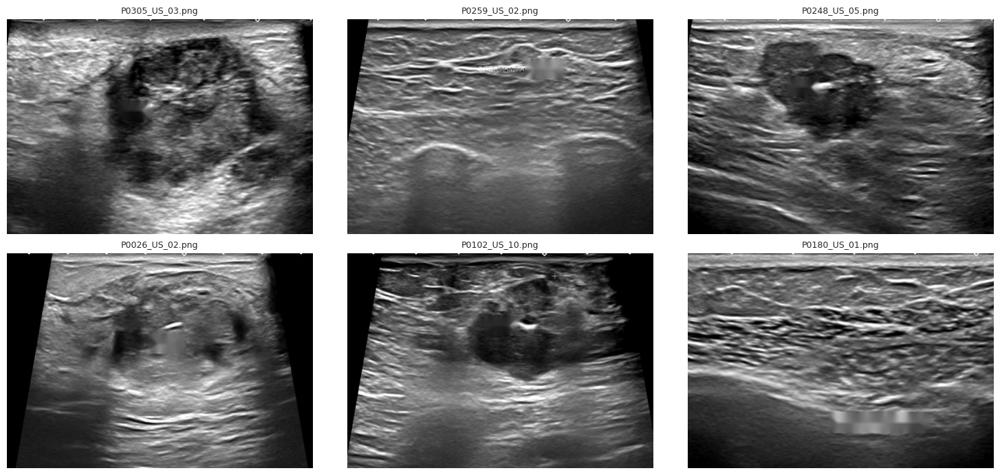

In [54]:
# Étape 6 : partie 7 : refaire le masquage du texte par inpainting (depuis les images d'origine)
# `imgs` (créée à la partie 5a) fait le lien : out_path = image d'origine, anon_path = copie anonymisée
us_map = imgs[imgs.modality == "Ultrasound"][["out_path", "anon_path"]].reset_index(drop=True)
print("Échographies à refaire :", len(us_map))
assert all(Path(p).exists() for p in us_map.out_path), "image d'origine introuvable"

def keep_word(t, c):
    t = t.strip()
    return any(ch.isalpha() for ch in t) and ((len(t) >= 2 and c > 0.3) or (len(t) >= 3 and c > 0.2))

def clean_text(src):
    g = cv2.imread(src, 0)
    big = cv2.resize(g, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    mask = np.zeros_like(g)
    n = 0
    for box, t, c in reader.readtext(big, detail=1, paragraph=False):
        if keep_word(t, c):
            xs = [p[0] for p in box]; ys = [p[1] for p in box]
            x1, x2 = int(min(xs) / 2) - 14, int(max(xs) / 2) + 14
            y1, y2 = int(min(ys) / 2) - 8, int(max(ys) / 2) + 8
            mask[max(y1, 0):y2, max(x1, 0):x2] = 255
            n += 1
    if n:
        g = cv2.inpaint(g, mask, 5, cv2.INPAINT_TELEA)
    return g, n

done2 = {}
for _, r in tqdm(us_map.iterrows(), total=len(us_map), desc="masquage v2"):
    g, nb = clean_text(r["out_path"])
    cv2.imwrite(r["anon_path"], g)          # on réécrit la copie anonymisée à partir de l'originale
    done2[Path(r["anon_path"]).name] = nb
json.dump(done2, open(WORK_DIR / "ocr_progress_v2.json", "w"))

s2 = pd.Series(done2)
print("Images avec texte effacé :", int((s2 > 0).sum()), "| zones :", int(s2.sum()))

# vérification sur les 1023 images, mêmes seuils que le masquage
rows3 = []
for n in tqdm(imgs_us["anon_name"].tolist(), desc="vérification"):
    g = cv2.imread(str(ANON_U / n), 0); h = g.shape[0]
    big = cv2.resize(g, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    for box, t, c in reader.readtext(big, detail=1, paragraph=False):
        if keep_word(t, c):
            ym = (min(p[1] for p in box) + max(p[1] for p in box)) / 2 / 2 / h
            rows3.append(dict(anon_name=n, texte=t.strip(), confiance=round(float(c), 2), y_relatif=round(float(ym), 2)))
left3 = pd.DataFrame(rows3)
print("\nImages avec texte encore lisible :", left3["anon_name"].nunique() if len(left3) else 0, "/", len(imgs_us))
if len(left3):
    print(left3.sort_values("confiance", ascending=False).head(15).to_string(index=False))

imgs_us["had_text"] = imgs_us["anon_name"].map(lambda n: done2.get(n, 0) > 0)
imgs_us[["pseudo_id", "anon_name", "had_text"]].to_csv(WORK_DIR / "us_had_text.csv", index=False)
print("\nhad_text :", int(imgs_us["had_text"].sum()), "images")
print(imgs_us.groupby("Pathology Label")["had_text"].mean().round(3).to_string())

# les mêmes 6 images + P0259 (texte résiduel) pour comparer avec la figure précédente
show = ["P0305_US_03.png", "P0259_US_02.png", "P0248_US_05.png", "P0026_US_02.png", "P0102_US_10.png", "P0180_US_01.png"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, n in zip(axes.ravel(), show):
    ax.imshow(cv2.imread(str(ANON_U / n), 0), cmap="gray", vmin=0, vmax=255)
    ax.set_title(n, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

### Contrôle final de l'anonymisation

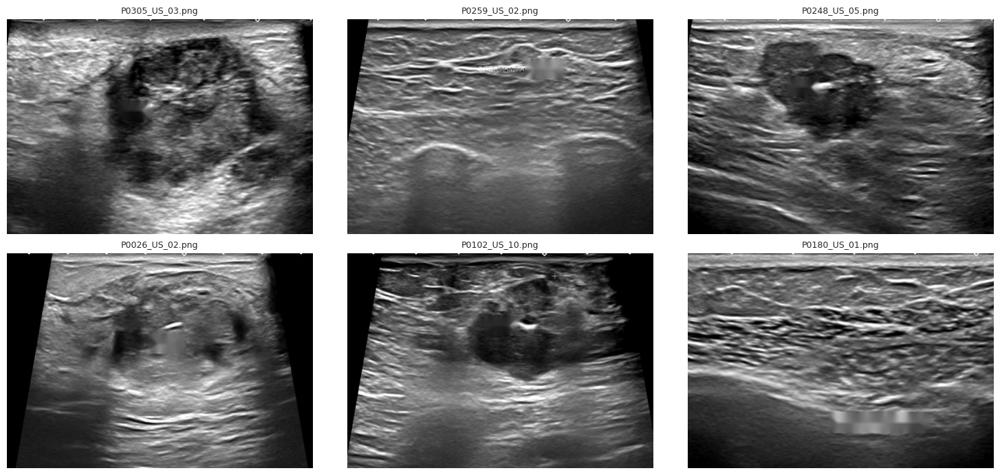

Images anonymisées : 1974 | illisibles : 0
Colonnes de images_anon.csv : ['pseudo_id', 'group_pseudo', 'modality', 'view_final', 'Pathology Label', 'BI-RADS Label', 'bilateral', 'small_res', 'us_short_layout', 'anon_name']
Ancien ID dans une cellule du tableau : 0
Rapports : 321 | avec ancien ID ou BI-RADS chiffré dans text_blind : 0
Métadonnées PNG trouvées dans un échantillon de 200 images : aucune

Dossiers dans /kaggle/working :
   .virtual_documents
   SECRET_do_not_share
   processed
   processed_anon
   reports
   reports_anon


In [55]:
# Étape 6 : Anonymisation - partie 6 : contrôle final du dataset anonymisé
# 1) Les images retraitées avec CLIP / NODE : les rectangles cachent-ils une lésion ?
show = [n for n in ["P0305_US_03.png", "P0259_US_02.png", "P0248_US_05.png", "P0026_US_02.png",
                    "P0102_US_10.png", "P0180_US_01.png"] if n in set(imgs_us.anon_name)]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax in axes.ravel(): ax.axis("off")
for ax, n in zip(axes.ravel(), show):
    ax.imshow(cv2.imread(str(ANON_U / n), 0), cmap="gray", vmin=0, vmax=255)
    ax.set_title(n, fontsize=9)
plt.tight_layout(); plt.show()

# 2) Contrôles d'intégrité du dataset anonymisé
all_imgs = sorted(ANON_M.glob("*.png")) + sorted(ANON_U.glob("*.png"))
bad = [p.name for p in all_imgs if cv2.imread(str(p), 0) is None]
print("Images anonymisées :", len(all_imgs), "| illisibles :", len(bad))

tab = pd.read_csv(WORK_DIR / "images_anon.csv")
old_ids = set(id_map)
print("Colonnes de images_anon.csv :", list(tab.columns))
print("Ancien ID dans une cellule du tableau :",
      int(tab.astype(str).apply(lambda c: c.str.contains(r"\b\d+y\d{2,3}\b", regex=True)).any(axis=1).sum()))

js = list(ANON_R.glob("*.json"))
n_bad = 0
for f in js:
    d = json.load(open(f))
    txt = d["text_clean"] + d["text_blind"]
    if re.search(r"\b\d+y\d{2,3}\b", txt) or re.search(r"bi-?\s?rads?\s*\(?\s*[0-6]", d["text_blind"], re.I):
        n_bad += 1
print("Rapports :", len(js), "| avec ancien ID ou BI-RADS chiffré dans text_blind :", n_bad)

# 3) Les images ont-elles encore des métadonnées PNG (texte, dpi, logiciel) ?
from PIL import Image
keys = set()
for p in all_imgs[:200]:
    with Image.open(p) as im:
        keys.update(im.info.keys())
print("Métadonnées PNG trouvées dans un échantillon de 200 images :", keys or "aucune")

# 4) Dossiers à ne pas partager
print("\nDossiers dans /kaggle/working :")
for p in sorted(WORK_DIR.iterdir()):
    if p.is_dir():
        print("  ", p.name)

**Conclusion 6.** Rapports : 0 ID, 0 date, 0 chiffre BI-RADS dans `text_blind`, 321 JSON anonymes. Images : noms sans ancien ID, 0 métadonnée PNG. Échographies : texte effacé par inpainting sur ≈369 images ; 0 texte encore lisible par l'OCR. **Limites :** la vérification utilise le même OCR que le masquage, des taches floues restent visibles, et les étiquettes des mammographies sont retirées par segmentation sans contrôle image par image.

# Étape 7 : validation et découpage

In [56]:
# Étape 7 : Validation des données et découpage train / val / test
from sklearn.model_selection import StratifiedGroupKFold

# ---------- 1) Tableau final par patient (identifiants pseudonymisés uniquement) ----------
f = pm.copy()
f["pseudo_id"] = f["patient"].map(id_map)
f["group_pseudo"] = f["group_id"].map(grp_map)

n_img = (imgs.groupby(["pseudo_id", "modality"]).size().unstack(fill_value=0)
             .rename(columns={"Mammogram": "n_mammo_clean", "Ultrasound": "n_us_clean2"}))
f = f.merge(n_img, on="pseudo_id", how="left").fillna({"n_mammo_clean": 0, "n_us_clean2": 0})
f["has_mammo"] = f["n_mammo_clean"] > 0
f["has_us"] = f["n_us_clean2"] > 0
f["has_report"] = f["pseudo_id"].map(lambda p: (ANON_R / f"{p}.json").exists())
f = f.merge(imgs_us.groupby("pseudo_id")["had_text"].any().rename("us_had_text").reset_index(), on="pseudo_id", how="left")
f["us_had_text"] = f["us_had_text"].fillna(False)

# ---------- 2) Règles de validation ----------
checks = {
    "BI-RADS entre 0 et 6":              f["BI-RADS Label"].between(0, 6),
    "Label absent seulement si BI-RADS 0": f["Pathology Label"].notna() | (f["BI-RADS Label"] == 0),
    "Au moins une mammographie":          f["has_mammo"],
    "Au moins une échographie":           f["has_us"],
}
print("=== Règles de validation (nombre de patients qui NE les respectent PAS) ===")
for k, v in checks.items():
    print(f"  {k:<40} {int((~v).sum())}")
cons = f.dropna(subset=["Pathology Label"])
exp = cons["BI-RADS Label"].map({1: "Normal", 2: "Benign", 3: "Benign", 4: "Malignant", 5: "Malignant", 6: "Malignant"})
print(f"  {'Pathology cohérent avec BI-RADS':<40} {int((exp != cons['Pathology Label']).sum())}")
print("  Patients sans échographie utile :", int((~f.has_us).sum()), "| sans rapport :", int((~f.has_report).sum()))

# ---------- 3) Source (pour l'équilibrage) et rôle de chaque patient ----------
f["source"] = np.where(f.small_res & f.us_short_layout, "A", np.where(f.small_res, "B", np.where(f.us_short_layout, "C", "D")))
f["role"] = np.where(f["Pathology Label"].isna(), "unlabeled", "labeled")
f["eval_main"] = f["role"].eq("labeled") & f["bilateral"].eq(False) & f["source"].eq("D")
f["strat"] = f["Pathology Label"].fillna("none") + "|" + f["source"].eq("D").map({True: "std", False: "alt"})

# ---------- 4) Découpage : 5 plis par groupe -> test (1 pli), val (1 pli), train (3 plis) ----------
lab = f[f.role == "labeled"].reset_index(drop=True)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = np.full(len(lab), -1)
for k, (_, te) in enumerate(sgkf.split(lab, lab["strat"], groups=lab["group_pseudo"])):
    folds[te] = k
lab["fold"] = folds
lab["split"] = lab["fold"].map({0: "test", 1: "val"}).fillna("train")
f = f.merge(lab[["pseudo_id", "split"]], on="pseudo_id", how="left")
f["split"] = f["split"].fillna("unlabeled")

# ---------- 5) Vérifications du découpage ----------
g_split = f[f.split != "unlabeled"].groupby("group_pseudo")["split"].nunique()
print("\nGroupes présents dans plusieurs ensembles (doit être 0) :", int((g_split > 1).sum()))
print("\n=== Patients par ensemble et par classe ===")
print(pd.crosstab(f["split"], f["Pathology Label"].fillna("(sans label)"), margins=True).to_string())
print("\n=== Part de la source non standard (A+B+C) par ensemble ===")
print(pd.crosstab(f["split"], f["source"]).to_string())
print("\n=== Patients bilatéraux par ensemble ===")
print(pd.crosstab(f["split"], f["bilateral"]).to_string())
print("\n=== Évaluation principale (unilatéraux, source standard) par ensemble ===")
print(pd.crosstab(f["split"], f["eval_main"]).to_string())
print("\n=== Malignant dans l'évaluation principale ===")
print(pd.crosstab(f[f.eval_main]["split"], f[f.eval_main]["Pathology Label"]).to_string())

# ---------- 6) Sauvegarde (aucun ancien ID) ----------
cols = ["pseudo_id", "group_pseudo", "BI-RADS Label", "Binary Label", "Pathology Label", "split", "bilateral",
        "source", "small_res", "us_short_layout", "eval_main", "has_mammo", "has_us", "has_report",
        "n_mammo_clean", "n_us_clean2", "us_had_text"]
f[cols].to_csv(WORK_DIR / "dataset_final.csv", index=False)
print("\nSauvegardé : dataset_final.csv", f[cols].shape)

=== Règles de validation (nombre de patients qui NE les respectent PAS) ===
  BI-RADS entre 0 et 6                     0
  Label absent seulement si BI-RADS 0      0
  Au moins une mammographie                0
  Au moins une échographie                 4
  Pathology cohérent avec BI-RADS          0
  Patients sans échographie utile : 4 | sans rapport : 11

Groupes présents dans plusieurs ensembles (doit être 0) : 0

=== Patients par ensemble et par classe ===
Pathology Label  (sans label)  Benign  Malignant  Normal  All
split                                                        
test                        0      48          9       7   64
train                       0     129         38      30  197
unlabeled                   5       0          0       0    5
val                         0      37         16      13   66
All                         5     214         63      50  332

=== Part de la source non standard (A+B+C) par ensemble ===
source     A   B   C    D
split         

In [57]:
# Étape 7 (suite) : validation croisée par groupe, stratifiée sur classe, source et bilatéral
from sklearn.model_selection import StratifiedGroupKFold

lab = f[f.role == "labeled"].reset_index(drop=True).copy()
lab["strat2"] = (lab["Pathology Label"] + "|" + lab["source"].eq("D").map({True: "std", False: "alt"})
                 + "|" + lab["bilateral"].map({True: "bi", False: "uni"}))
print("Taille de chaque strate :")
print(lab["strat2"].value_counts().to_string())

# les strates trop petites (< 5) sont fusionnées avec la même classe, source regroupée
small = lab["strat2"].map(lab["strat2"].value_counts()) < 5
lab.loc[small, "strat2"] = lab.loc[small, "Pathology Label"] + "|" + lab.loc[small, "bilateral"].map({True: "bi", False: "uni"})

best_fold, best_gap = None, 1e9
for seed in range(30):          # on teste 30 tirages et on garde le plus équilibré
    sg = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    fo = np.full(len(lab), -1)
    for k, (_, te) in enumerate(sg.split(lab, lab["strat2"], groups=lab["group_pseudo"])):
        fo[te] = k
    tmp = lab.assign(fold=fo)
    mal = tmp[tmp["Pathology Label"] == "Malignant"].groupby("fold").size().reindex(range(5), fill_value=0)
    main = tmp[tmp.eval_main & (tmp["Pathology Label"] == "Malignant")].groupby("fold").size().reindex(range(5), fill_value=0)
    bil = tmp.groupby("fold")["bilateral"].mean()
    gap = (mal.max() - mal.min()) + 2 * (main.max() - main.min()) + 10 * (bil.max() - bil.min())
    if gap < best_gap:
        best_gap, best_fold, best_seed = gap, fo.copy(), seed
lab["fold"] = best_fold
print("\nGraine retenue :", best_seed, "| écart d'équilibre :", round(best_gap, 2))

g_f = lab.groupby("group_pseudo")["fold"].nunique()
print("Groupes présents dans plusieurs plis (doit être 0) :", int((g_f > 1).sum()))

print("\n=== Patients par pli et par classe ===")
print(pd.crosstab(lab["fold"], lab["Pathology Label"], margins=True).to_string())
print("\n=== Malignant dans l'évaluation principale, par pli ===")
print(pd.crosstab(lab[lab.eval_main]["fold"], lab[lab.eval_main]["Pathology Label"], margins=True).to_string())
print("\n=== Source par pli ===");           print(pd.crosstab(lab["fold"], lab["source"]).to_string())
print("\n=== Part de bilatéraux par pli ==="); print(lab.groupby("fold")["bilateral"].mean().round(2).to_string())

f = f.drop(columns=["fold"], errors="ignore").merge(lab[["pseudo_id", "fold"]], on="pseudo_id", how="left")
cols2 = cols + ["fold"]
f[cols2].to_csv(WORK_DIR / "dataset_final.csv", index=False)
print("\nSauvegardé : dataset_final.csv avec colonne fold (NaN pour les 5 patients sans label)")

Taille de chaque strate :
strat2
Benign|std|bi        109
Benign|std|uni        82
Malignant|std|uni     39
Normal|std|uni        33
Malignant|alt|uni     24
Benign|alt|bi         16
Normal|std|bi         14
Benign|alt|uni         7
Normal|alt|bi          3

Graine retenue : 2 | écart d'équilibre : 8.6
Groupes présents dans plusieurs plis (doit être 0) : 0

=== Patients par pli et par classe ===
Pathology Label  Benign  Malignant  Normal  All
fold                                           
0                    41         14       9   64
1                    37         13      16   66
2                    40         14      12   66
3                    46         11       9   66
4                    50         11       4   65
All                 214         63      50  327

=== Malignant dans l'évaluation principale, par pli ===
Pathology Label  Benign  Malignant  Normal  All
fold                                           
0                    15          9       6   30
1               

**Conclusion 7.** Règles de validation respectées (4 patients sans échographie utile, 11 sans rapport, 5 BI-RADS 0 sans label). Un test unique ne contenait que 3 Malignant dans l'évaluation principale : on utilise la validation croisée à 5 plis par groupe (63 Malignant évalués, 39 dans l'évaluation principale, 0 groupe coupé). Le tirage a été choisi sur l'équilibre des plis (30 essais), sans modèle.

# Étape 8 : rapport qualité (JSON)

In [58]:
# Étape 8 : Quality report (JSON)
import json, datetime
from scipy.stats import fisher_exact

def py(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (pd.Timestamp,)): return str(o)
    return str(o)

L = f[f.role == "labeled"].copy()
L["malig"] = L["Pathology Label"].eq("Malignant")

# ---------- 1) Données ----------
dataset = dict(
    patients=int(len(f)), patients_labeled=int(len(L)), patients_unlabeled_birads0=int((f.role == "unlabeled").sum()),
    images_mammo=int((imgs.modality == "Mammogram").sum()), images_us=int((imgs.modality == "Ultrasound").sum()),
    reports=int(f.has_report.sum()), patients_without_report=int((~f.has_report).sum()),
    patients_without_us=int((~f.has_us).sum()), patients_without_mammo=int((~f.has_mammo).sum()),
    class_counts=f["Pathology Label"].value_counts().to_dict(),
    birads_counts={int(k): int(v) for k, v in f["BI-RADS Label"].value_counts().sort_index().items()},
    labels_derived_from_birads=True,
)

# ---------- 2) Images exclues et corrections ----------
excl = im_all["exclude_reason"].replace("", "kept").value_counts().to_dict()
# bordures corrigées à la main (4 forcées à la médiane ; la 5e, 4105y18_L_MLO, a déjà l'étiquette "border_fix")
if "border_fix" not in log.columns:
    log["border_fix"] = np.nan
forced = ["02300y21_R_MLO_1.png", "2599y11_R_MLO_1.png", "2786y19_R_MLO_1.png", "4261y16_L_MLO_1.png"]
log.loc[log.filename.isin(forced) & log["border_fix"].isna(), "border_fix"] = "forced_median"
us_log = log[log.modality == "Ultrasound"]
mm_log = log[log.modality == "Mammogram"]
images = dict(
    exclusions_step4=excl,
    ultrasound_empty_frames_excluded=int(us_log["empty_frame"].fillna(False).sum()) if "empty_frame" in us_log else None,
    ultrasound_badge_removed=int(us_log["badge_removed"].eq(True).sum()) if "badge_removed" in us_log else None,
    ultrasound_text_erased=int(imgs_us["had_text"].sum()),
    ultrasound_text_still_readable_by_ocr=int(left3["anon_name"].nunique()) if len(left3) else 0,
    mammo_segmentation_failures=int(mm_log["failed"].fillna(False).sum()),
    mammo_border_fix_applied=int(mm_log["border_fix"].notna().sum()) if "border_fix" in mm_log else None,
    mammo_view_corrections=int((mm.fix_reason != "").sum()),
    mammo_polarity={"negative": int((dm.polarity == "negative").sum()), "positive": int((dm.polarity == "positive").sum())},
    final_mammo_size=[MM_W, MM_H], final_us_size=list(US_SIZE),
)

# ---------- 3) Rapports ----------
rj = [json.load(open(p)) for p in ANON_R.glob("*.json")]
reports = dict(
    n=len(rj),
    clinical_data_removed_in_blind=int(sum("[REMOVED]" in r["text_blind"] for r in rj)),
    birads_digit_left_in_blind=int(sum(bool(re.search(r"bi-?\s?rads?\s*\(?\s*[0-6]", r["text_blind"], re.I)) for r in rj)),
    old_id_pattern_left=int(sum(bool(re.search(r"\b\d+y\d{2,3}\b", r["text_clean"] + r["text_blind"])) for r in rj)),
    note="text_clean garde le BI-RADS ; text_blind n'a ni BI-RADS ni Clinical Data. Le corps du rapport décrit encore les lésions.",
)

# ---------- 4) Raccourcis (taux de Malignant, test de Fisher) ----------
def rate(col, true_name, false_name, data=L):
    t = pd.crosstab(data[col], data["malig"])
    p = fisher_exact(t.values)[1] if t.shape == (2, 2) else None
    return {true_name: round(float(data.loc[data[col], "malig"].mean()), 3),
            false_name: round(float(data.loc[~data[col], "malig"].mean()), 3),
            "n_true": int(data[col].sum()), "p_fisher": None if p is None else float(f"{p:.2g}")}

U = L[~L.bilateral].copy()
L["no_report"] = ~L["has_report"]
shortcuts = dict(
    bilateral=rate("bilateral", "bilateral", "unilateral"),
    missing_report=rate("no_report", "no_report", "has_report"),
    low_resolution_mammo_all=rate("small_res", "low_res", "standard"),
    low_resolution_mammo_unilateral=rate("small_res", "low_res", "standard", U),
    short_us_layout_unilateral=rate("us_short_layout", "short", "standard", U),
    note="Aucune de ces variables ne doit servir de feature. Elles servent à stratifier et à rapporter les résultats.",
)

# ---------- 5) Sondes de signature (test 5D) ----------
try:
    pr = pd.read_csv(WORK_DIR / "probe_results.csv")
    probes = pr.to_dict(orient="records")
except Exception:
    probes = "probe_results.csv introuvable"

# ---------- 6) Découpage ----------
fold_tab = L.dropna(subset=["fold"]).groupby("fold").agg(
    patients=("pseudo_id", "size"), malignant=("malig", "sum"),
    eval_main_malignant=("eval_main", lambda s: int((s & L.loc[s.index, "malig"]).sum())),
    bilateral_share=("bilateral", "mean"), non_standard_source=("source", lambda s: int((s != "D").sum())))
split = dict(
    method="StratifiedGroupKFold, 5 plis, groupes = group_pseudo, strate = classe x source x bilatéral",
    seed_selected_among_30_by_balance=int(best_seed),
    groups_split_across_folds=int((L.dropna(subset=["fold"]).groupby("group_pseudo")["fold"].nunique() > 1).sum()),
    folds=fold_tab.round(3).reset_index().to_dict(orient="records"),
    eval_main_definition="unilatéraux, source standard (résolution et mise en page standard)",
    eval_main_patients=int(L.eval_main.sum()),
)

# ---------- 7) Limites ----------
limitations = [
    "Les labels Binary et Pathology sont déduits du BI-RADS : la vraie cible est le BI-RADS.",
    "Tous les patients Malignant sont unilatéraux ; aucun patient bilatéral n'est Malignant.",
    "La basse résolution (autre appareil) et la mise en page échographique courte sont liées au label et à la période 2022-2023.",
    "Le test de sonde AUC retrouve la source à 0,99 depuis les images prétraitées : la signature n'est pas effacée.",
    "Le suffixe yXX de l'ID semble lié à l'ancienneté du dossier (hypothèse non confirmée) et à la classe ; il est supprimé par le pseudo-ID.",
    "Le masquage du texte des échographies est vérifié par le même OCR qui l'a appliqué ; des taches floues restent visibles.",
    "Les étiquettes des mammographies sont retirées par segmentation, sans OCR ni contrôle image par image.",
    "Les échantillons par source non standard sont petits (41 patients) : résultats par source indicatifs.",
    "Un patient atypique a deux mammographies en RGBA et une marge d'export différente (une vue corrigée à la main).",]

report = dict(generated=datetime.datetime.now().isoformat(timespec="seconds"),
              dataset=dataset, images=images, reports=reports, shortcuts=shortcuts,
              signature_probes=probes, split=split, limitations=limitations)

# ---------- Contrôle : aucun ancien identifiant dans le rapport ----------
txt = json.dumps(report, default=py, ensure_ascii=False, indent=2)
print("Ancien ID dans le rapport :", len(re.findall(r"\b\d+y\d{2,3}\b", txt)))
open(WORK_DIR / "quality_report.json", "w").write(txt)
print("Écrit : quality_report.json (", len(txt) // 1024, "Ko )")
print("\n--- Aperçu : dataset, images, raccourcis ---")
print(json.dumps({k: report[k] for k in ["dataset", "images", "shortcuts"]}, default=py, ensure_ascii=False, indent=1)[:2800])

Ancien ID dans le rapport : 0
Écrit : quality_report.json ( 10 Ko )

--- Aperçu : dataset, images, raccourcis ---
{
 "dataset": {
  "patients": 332,
  "patients_labeled": 327,
  "patients_unlabeled_birads0": 5,
  "images_mammo": 951,
  "images_us": 1023,
  "reports": 321,
  "patients_without_report": 11,
  "patients_without_us": 4,
  "patients_without_mammo": 0,
  "class_counts": {
   "Benign": 214,
   "Malignant": 63,
   "Normal": 50
  },
  "birads_counts": {
   "0": 5,
   "1": 50,
   "2": 167,
   "3": 47,
   "4": 24,
   "5": 15,
   "6": 24
  },
  "labels_derived_from_birads": true
 },
 "images": {
  "exclusions_step4": {
   "kept": 1993,
   "exact_duplicate": 7,
   "corrupt_or_empty": 1
  },
  "ultrasound_empty_frames_excluded": 19,
  "ultrasound_badge_removed": 744,
  "ultrasound_text_erased": 369,
  "ultrasound_text_still_readable_by_ocr": 0,
  "mammo_segmentation_failures": 0,
  "mammo_border_fix_applied": 5,
  "mammo_view_corrections": 13,
  "mammo_polarity": {
   "negative": 875

# Nettoyage final (à faire manuellement, une fois le rapport vérifié)

1. Télécharger le dossier `SECRET_do_not_share` (clé de correspondance) puis ne jamais le publier.
2. Supprimer les dossiers et fichiers qui portent encore les anciens IDs. Décommente la cellule suivante pour les supprimer.

In [59]:
# import shutil
# for d in ["processed", "reports"]:
#     shutil.rmtree(WORK_DIR / d, ignore_errors=True)
# for f in ["files_inventory.csv", "png_integrity.csv", "pdf_integrity.csv", "images_clean_table.csv",
#           "patient_completeness.csv", "patient_master.csv", "mammo_views_fixed.csv", "images_final_list.csv",
#           "preprocess_log.csv", "labeled_patients_with_year.csv", "reports_clean.csv", "reports_final.csv",
#           "ocr_progress.json", "ocr_progress_v2.json", "ocr_remaining_text.csv", "probe_features.npz"]:
#     (WORK_DIR / f).unlink(missing_ok=True)
# print("Restent :", [p.name for p in WORK_DIR.iterdir()])